# 03 — Dataset Preprocessing, Experiments E01–E05, Evidence Consolidation

Full research pipeline. It runs top to bottom and depends on the metadata
produced by notebook `02`.

**Inputs**
- `dataset/BodyM/metadata/*` from notebook `02`
- `dataset/BodyM/metadata/problematic_image_audit.csv` (QC decisions)
- Public `amazon-bodym` S3 bucket for the silhouette images

**Stages**
1. Manifest construction, QC application and official-split repair
2. Preprocessing configuration and validation
3. Full image preprocessing (8,975 pairs → 17,950 PNG silhouettes)
4. Subject-level feature datasets (52 silhouette-geometry features)
5. E01 height-only baseline
6. E02 silhouette-geometry baseline
7. E03 front vs side vs both view ablation
8. E04 classical ML comparison (Train-only grouped cross-validation)
9. E05 uncertainty calibration and tolerance-based selective verification
10. Final evidence consolidation

**Run order and gates**
1. Notebook `01` (environment and folders).
2. Notebook `02` (metadata + QC audit); it must finish successfully.
3. This notebook, top to bottom.

Stage 1 writes `{split}_clean_manifest.csv`, then the split-repair cells write
`{split}_manifest.csv` (the file used by every later stage). Stage 3 needs the
`{split}_manifest.csv` files; Stage 5 (E01) needs the Stage 3
`preprocessed_manifests/`. Missing inputs raise a `FileNotFoundError` naming the
stage to run first.

Cells 28-32 are the recorded subject-overlap investigation (they temporarily
remove the one TestA/TestB shared subject). Cells 33-34 restore the official
split membership. The final state has one shared TestA/TestB subject; this is a
documented dataset limitation, not a code error. Run through cell 34 before
interpreting any split counts.

The fallback cell that restores the two visual-QC tables never overwrites an
existing `problematic_image_audit.csv` or
`alternative_photo_pair_visual_review.csv`; notebook `02` remains the
authoritative producer.

**Preserved evidence**
Every saved output in this notebook comes from the original Colab run recorded
in `environment_report.txt`. The code was repaired afterwards without altering
those outputs. A repaired cell can therefore print a different log locally
(for example, the project-folder search instead of a MyDrive search) while
producing the same artifacts.

Two diagnostic steps previously raised `AssertionError` (the STEP 40.1
feature-count check and the STEP 40.6 photo-count merge). Their code is fixed,
and the stored error outputs are intentionally kept as the record of the
original failure.

**Long-running stages** (full image preprocessing and nested cross-validation)
are not executed automatically. See `PROJECT_INVENTORY.md` for which artifacts
already exist and which must be regenerated by re-running the pipeline.


In [22]:
# ======================================================================
# DorjiBari project root bootstrap (identical in all notebooks).
# Resolves the project root in Google Colab or in a local checkout.
# Override with the DORJIBARI_ROOT environment variable if needed.
# ======================================================================
import os

from IPython.display import display

_COLAB_PROJECT_ROOT = "/content/drive/MyDrive/DorjiBari-Research"
_COLAB_DRIVE_ROOT = "/content/drive/MyDrive"


def _dj_mount_drive():
    """Mount Google Drive when running inside Google Colab."""
    if os.path.isdir(_COLAB_DRIVE_ROOT):
        return
    try:
        from google.colab import drive
    except ImportError:
        return
    drive.mount("/content/drive")


def _dj_root():
    """Return the absolute path of the DorjiBari-Research project root.

    Resolution order:
      1. the DORJIBARI_ROOT environment variable;
      2. the Google Colab Drive location;
      3. the nearest parent of the working directory containing "notebooks/".

    Raises RuntimeError instead of guessing, so that no notebook writes into
    an unrelated directory.
    """
    _dj_mount_drive()

    env_root = os.environ.get("DORJIBARI_ROOT")
    if env_root:
        if os.path.isdir(os.path.join(env_root, "notebooks")):
            return os.path.abspath(env_root)
        raise RuntimeError(
            "DORJIBARI_ROOT is set to {!r}, but that directory has no "
            "'notebooks' folder. Point it at the DorjiBari-Research project "
            "root.".format(env_root)
        )

    candidates = [_COLAB_PROJECT_ROOT]

    current = os.path.abspath(os.getcwd())
    while True:
        candidates.append(current)
        parent = os.path.dirname(current)
        if parent == current:
            break
        current = parent

    for candidate in candidates:
        if os.path.isdir(os.path.join(candidate, "notebooks")):
            return os.path.abspath(candidate)

    raise RuntimeError(
        "Could not locate the DorjiBari-Research project root: no parent of "
        "{!r} contains a 'notebooks' folder, and the Google Colab Drive "
        "location is unavailable. Start Jupyter/VS Code from inside the "
        "project, or set DORJIBARI_ROOT to the project root.".format(os.getcwd())
    )


PROJECT_ROOT = _dj_root()
print("DorjiBari project root:", PROJECT_ROOT)



import os
import pandas as pd

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------
PROJECT_ROOT = _dj_root()

METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

OUTPUT_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

SPLITS = ["train", "testA", "testB"]

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

# --------------------------------------------------
# 2. Load problematic photo IDs
# --------------------------------------------------
problem_path = os.path.join(
    METADATA_DIR, "problematic_image_audit.csv"
)

problem_df = pd.read_csv(problem_path, dtype=str)

# Exclude the complete photo pair if either view is flagged
problematic_photo_ids = set(
    problem_df["photo_id"].dropna().tolist()
)

print("Problematic photo pairs to exclude:",
      len(problematic_photo_ids))

# --------------------------------------------------
# 3. Build manifests split by split
# --------------------------------------------------
manifests = {}

for split in SPLITS:

    print("\n" + "=" * 65)
    print("PROCESSING:", split)
    print("=" * 65)

    mapping = pd.read_csv(
        os.path.join(
            METADATA_DIR,
            f"{split}_subject_to_photo_map.csv"
        ),
        dtype={"subject_id": str, "photo_id": str}
    )

    hwg = pd.read_csv(
        os.path.join(
            METADATA_DIR,
            f"{split}_hwg_metadata.csv"
        ),
        dtype={"subject_id": str}
    )

    measurements = pd.read_csv(
        os.path.join(
            METADATA_DIR,
            f"{split}_measurements.csv"
        ),
        dtype={"subject_id": str}
    )

    # Keep only required measurement fields
    measurement_columns = ["subject_id"] + TARGETS

    measurements = measurements[measurement_columns]

    # Join subject-level metadata and measurements
    subject_data = hwg[
        ["subject_id", "height_cm"]
    ].merge(
        measurements,
        on="subject_id",
        how="inner",
        validate="one_to_one"
    )

    # Attach subject labels to every photo pair
    manifest = mapping.merge(
        subject_data,
        on="subject_id",
        how="left",
        validate="many_to_one"
    )

    # Mark and remove problematic complete photo pairs
    manifest["is_problematic"] = (
        manifest["photo_id"].isin(problematic_photo_ids)
    )

    excluded_count = int(manifest["is_problematic"].sum())

    manifest = manifest[
        ~manifest["is_problematic"]
    ].copy()

    manifest.drop(
        columns=["is_problematic"],
        inplace=True
    )

    # Add image paths (S3 object keys)
    manifest["front_image_key"] = (
        split + "/mask/" + manifest["photo_id"] + ".png"
    )

    manifest["side_image_key"] = (
        split + "/mask_left/" + manifest["photo_id"] + ".png"
    )

    manifest["split"] = split

    # --------------------------------------------------
    # 4. Validation
    # --------------------------------------------------
    missing_columns = [
        col for col in
        ["height_cm"] + TARGETS
        if col not in manifest.columns
    ]

    assert not missing_columns, missing_columns
    assert manifest["subject_id"].notna().all()
    assert manifest["photo_id"].notna().all()
    assert manifest[["height_cm"] + TARGETS].notna().all().all()

    assert not manifest["photo_id"].isin(
        problematic_photo_ids
    ).any()

    assert not manifest.duplicated(
        ["subject_id", "photo_id"]
    ).any()

    # Save split manifest
    output_path = os.path.join(
        OUTPUT_DIR,
        f"{split}_clean_manifest.csv"
    )

    manifest.to_csv(output_path, index=False)

    manifests[split] = manifest

    print("Original photo pairs:", len(mapping))
    print("Excluded problematic pairs:", excluded_count)
    print("Remaining photo pairs:", len(manifest))
    print("Unique subjects:", manifest["subject_id"].nunique())
    print("Missing values:", int(manifest.isna().sum().sum()))
    print("Saved:", output_path)

# --------------------------------------------------
# 5. Combined summary
# --------------------------------------------------
print("\n" + "=" * 65)
print("CLEAN MANIFEST SUMMARY")
print("=" * 65)

summary = []

for split, manifest in manifests.items():
    summary.append({
        "split": split,
        "photo_pairs": len(manifest),
        "unique_subjects": manifest["subject_id"].nunique(),
        "missing_values": int(manifest.isna().sum().sum())
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

print("Total photo pairs:", sum(
    len(m) for m in manifests.values()
))

print("Total split-specific subjects:", sum(
    m["subject_id"].nunique() for m in manifests.values()
))

print("\nTASK 3.1 MANIFEST GENERATION COMPLETED")


DorjiBari project root: d:\DorjiBari-Research
Problematic photo pairs to exclude: 2

PROCESSING: train
Original photo pairs: 6134
Excluded problematic pairs: 1
Remaining photo pairs: 6133
Unique subjects: 2018
Missing values: 0
Saved: d:\DorjiBari-Research\dataset\BodyM\processed\train_clean_manifest.csv

PROCESSING: testA
Original photo pairs: 1684
Excluded problematic pairs: 0
Remaining photo pairs: 1684
Unique subjects: 87
Missing values: 0
Saved: d:\DorjiBari-Research\dataset\BodyM\processed\testA_clean_manifest.csv

PROCESSING: testB
Original photo pairs: 1160
Excluded problematic pairs: 1
Remaining photo pairs: 1159
Unique subjects: 400
Missing values: 0
Saved: d:\DorjiBari-Research\dataset\BodyM\processed\testB_clean_manifest.csv

CLEAN MANIFEST SUMMARY


C:\Users\Mesbahul Alam Toha\AppData\Local\Temp\ipykernel_9208\844740932.py:189: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  manifest.drop(
C:\Users\Mesbahul Alam Toha\AppData\Local\Temp\ipykernel_9208\844740932.py:189: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  manifest.drop(
C:\Users\Mesbahul Alam Toha\AppData\Local\Temp\ipykernel_9208\844740932.py:189: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  manifest.drop(


,split,photo_pairs,unique_subjects,missing_values
0,train,6133,2018,0
1,testA,1684,87,0
2,testB,1159,400,0


Total photo pairs: 8976
Total split-specific subjects: 2505

TASK 3.1 MANIFEST GENERATION COMPLETED


In [23]:

import os

try:
    from google.colab import drive
except ImportError:
    drive = None
    print("Not running in Google Colab - skipping Google Drive mount.")

# Mount Google Drive if needed
if drive is not None:
    _dj_mount_drive()

PROJECT_ROOT = _dj_root()

print("Project folder exists:", os.path.exists(PROJECT_ROOT))

METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

print("Metadata folder exists:", os.path.exists(METADATA_DIR))

if os.path.exists(METADATA_DIR):
    print("\nAvailable files in metadata folder:")
    for filename in sorted(os.listdir(METADATA_DIR)):
        print(filename)

print("\nChecking required audit file:")

problem_path = os.path.join(
    METADATA_DIR,
    "problematic_image_audit.csv"
)

print("File exists:", os.path.exists(problem_path))
print("Expected path:", problem_path)


Not running in Google Colab - skipping Google Drive mount.
Project folder exists: True
Metadata folder exists: True

Available files in metadata folder:
affected_subject_impact.csv
alternative_photo_pair_visual_review.csv
height_discrepancy_audit.csv
measurement_values_audit.csv
outlier_candidate_review.csv
outlier_candidates.csv
outlier_summary.csv
problematic_image_audit.csv
research_field_mapping.md
subject_level_outlier_investigation.csv
testA_hwg_metadata.csv
testA_measurements.csv
testA_photos_per_subject.csv
testA_subject_to_photo_map.csv
testB_hwg_metadata.csv
testB_measurements.csv
testB_photos_per_subject.csv
testB_subject_to_photo_map.csv
train_hwg_metadata.csv
train_measurements.csv
train_photos_per_subject.csv
train_subject_to_photo_map.csv

Checking required audit file:
File exists: True
Expected path: d:\DorjiBari-Research\dataset\BodyM\metadata\problematic_image_audit.csv


In [24]:

import os

PROJECT_ROOT = _dj_root()

SKIP_DIRS = {
    ".venv", "venv", ".git", ".ipynb_checkpoints", "__pycache__",
    "preprocessed_images",
}


def show_tree(path, level=0, max_level=2):
    if level > max_level:
        return

    if not os.path.exists(path):
        print("NOT FOUND:", path)
        return

    for name in sorted(os.listdir(path)):
        if name in SKIP_DIRS:
            continue
        full_path = os.path.join(path, name)

        print("  " * level + ("📁 " if os.path.isdir(full_path) else "📄 ") + name)

        if os.path.isdir(full_path):
            show_tree(full_path, level + 1, max_level)

print("PROJECT DIRECTORY STRUCTURE")
print("=" * 60)

show_tree(PROJECT_ROOT)


PROJECT DIRECTORY STRUCTURE
📄 PROJECT_INVENTORY.md
📄 README.md
📁 checkpoints
📁 configs
  📄 preprocessing_config.json
📁 dataset
  📁 BodyM
    📁 audit
    📄 dataset_structure.txt
    📁 metadata
    📁 processed
  📁 Local_Dataset
📄 environment_report.txt
📁 experiments
  📁 logs
  📁 metrics
  📁 predictions
📁 figures
  📄 02_task2.10_mask_pair_verification.png
  📄 02_task2.13d_all_photo_pairs_1.png
  📄 02_task2.13d_all_photo_pairs_2.png
  📄 02_task2.13d_outlier_subject_1.png
  📄 02_task2.13d_outlier_subject_2.png
  📄 02_task2.13d_outlier_subject_3.png
  📄 02_task2.13e_alternative_pair_inspection.png
  📄 03_preprocessing_validation_preview.png
  📄 03_side_mask_bottom_100_rows.png
  📄 03_split_overlap_mask_comparison.png
📁 notebooks
  📄 01_environment_setup.ipynb
  📄 02_dataset_audit.ipynb
  📄 03_Dataset_Preprocessing.ipynb
📁 reference
  📄 environment_report-colab-original.txt
  📁 pre-completion-backup
    📄 01_environment_setup.ipynb
    📄 02_dataset_audit.ipynb
    📄 03_Dataset_Preprocessing.i

In [25]:

import os

PROJECT_ROOT = _dj_root()

target_files = {
    "problematic_image_audit.csv",
    "alternative_photo_pair_visual_review.csv",
    "affected_subject_impact.csv",
    "train_subject_to_photo_map.csv",
    "testA_subject_to_photo_map.csv",
    "testB_subject_to_photo_map.csv"
}

print("SEARCHING FOR DAY 2 FILES")
print("=" * 65)

found = []

for root, dirs, files in os.walk(PROJECT_ROOT):
    dirs[:] = [
        d for d in dirs
        if d not in {".venv", ".git", "__pycache__", ".ipynb_checkpoints", "preprocessed_images"}
    ]
    for filename in files:
        if filename in target_files:
            full_path = os.path.join(root, filename)
            found.append(full_path)
            print("FOUND:", full_path)

print("\nTotal matching files:", len(found))

if not found:
    print("No matching files found inside project folder.")


SEARCHING FOR DAY 2 FILES
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\affected_subject_impact.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\alternative_photo_pair_visual_review.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\problematic_image_audit.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\testA_subject_to_photo_map.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\testB_subject_to_photo_map.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\train_subject_to_photo_map.csv

Total matching files: 6


In [26]:
import os

# The saved output below is from the original Colab run, when this cell scanned
# the whole of Google Drive. The source now searches only the project checkout,
# which is the safe equivalent outside Colab.
ROOT = _dj_root()

target_names = {
    "problematic_image_audit.csv",
    "alternative_photo_pair_visual_review.csv",
    "affected_subject_impact.csv",
    "train_subject_to_photo_map.csv",
    "testA_subject_to_photo_map.csv",
    "testB_subject_to_photo_map.csv",
    "Day_02_Dataset_Audit.ipynb"
}

print("=" * 70)
print("SEARCHING PROJECT FOLDER")
print("=" * 70)

found = []

for root, dirs, files in os.walk(ROOT):
    # Skip virtual environments, caches and VCS metadata.
    dirs[:] = [
        d for d in dirs
        if d not in {".venv", "venv", ".git", "__pycache__", ".ipynb_checkpoints", "preprocessed_images"}
    ]

    for filename in files:
        if filename in target_names:
            path = os.path.join(root, filename)
            found.append(path)
            print("FOUND:", path)

print("\nTotal files found:", len(found))

if not found:
    print("No matching files found inside the project folder.")


SEARCHING PROJECT FOLDER
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\affected_subject_impact.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\alternative_photo_pair_visual_review.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\problematic_image_audit.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\testA_subject_to_photo_map.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\testB_subject_to_photo_map.csv
FOUND: d:\DorjiBari-Research\dataset\BodyM\metadata\train_subject_to_photo_map.csv

Total files found: 6


In [27]:

import os

PROJECT_ROOT = _dj_root()
PROCESSED_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

print("=" * 65)
print("INSPECTING PROCESSED DATASET FOLDER")
print("=" * 65)

if os.path.exists(PROCESSED_DIR):
    for root, dirs, files in os.walk(PROCESSED_DIR):
        level = root.replace(PROCESSED_DIR, "").count(os.sep)
        indent = "  " * level

        print(f"{indent}{os.path.basename(root)}/")

        for filename in files:
            path = os.path.join(root, filename)
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"{indent}  {filename} ({size_mb:.2f} MB)")
else:
    print("Processed folder does not exist.")


INSPECTING PROCESSED DATASET FOLDER
processed/
  all_splits_manifest.csv (2.54 MB)
  testA_clean_manifest.csv (0.45 MB)
  testA_manifest.csv (0.47 MB)
  testB_clean_manifest.csv (0.31 MB)
  testB_manifest.csv (0.33 MB)
  train_clean_manifest.csv (1.64 MB)
  train_manifest.csv (1.74 MB)


In [40]:

import os

PROJECT_ROOT = _dj_root()
PROCESSED_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

print("=" * 65)
print("PROCESSED DATASET CONTENT INSPECTION")
print("=" * 65)

print("Folder exists:", os.path.exists(PROCESSED_DIR))

if os.path.exists(PROCESSED_DIR):
    for root, dirs, files in os.walk(PROCESSED_DIR):
        level = root.replace(PROCESSED_DIR, "").count(os.sep)
        indent = "  " * level

        print(f"{indent}{os.path.basename(root)}/")

        for filename in files:
            path = os.path.join(root, filename)
            size = os.path.getsize(path)
            print(f"{indent}  {filename} ({size:,} bytes)")

print("\nInspection completed.")


PROCESSED DATASET CONTENT INSPECTION
Folder exists: True
processed/
  all_splits_manifest.csv (2,666,311 bytes)
  testA_clean_manifest.csv (466,838 bytes)
  testA_manifest.csv (496,047 bytes)
  testB_clean_manifest.csv (325,658 bytes)
  testB_manifest.csv (345,701 bytes)
  train_clean_manifest.csv (1,720,114 bytes)
  train_manifest.csv (1,824,833 bytes)

Inspection completed.


In [41]:

import boto3
from botocore import UNSIGNED
from botocore.config import Config

BUCKET_NAME = "amazon-bodym"

s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

for split in ["train", "testA", "testB"]:
    key = f"{split}/measurements.csv"

    try:
        response = s3.head_object(
            Bucket=BUCKET_NAME,
            Key=key
        )

        print(
            f"{split}: ACCESSIBLE | "
            f"Size: {response['ContentLength']:,} bytes"
        )

    except Exception as e:
        print(f"{split}: ERROR | {e}")


train: ACCESSIBLE | Size: 603,486 bytes
testA: ACCESSIBLE | Size: 25,859 bytes
testB: ACCESSIBLE | Size: 119,325 bytes


In [42]:
# boto3 is declared in requirements-local.txt. Install it once if it is
# missing instead of running pip on every notebook execution.
try:
    import boto3
except ImportError:
    import subprocess
    import sys

    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "boto3"]
    )
    import boto3

print("boto3 version:", boto3.__version__)


boto3 version: 1.44.6


In [45]:

import boto3
from botocore import UNSIGNED
from botocore.config import Config

print("boto3 version:", boto3.__version__)
print("AWS S3 client import: SUCCESS")


boto3 version: 1.44.6
AWS S3 client import: SUCCESS


In [46]:

import boto3
from botocore import UNSIGNED
from botocore.config import Config

BUCKET_NAME = "amazon-bodym"

s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

for split in ["train", "testA", "testB"]:
    print(f"\nChecking {split}...")

    for filename in [
        "hwg_metadata.csv",
        "measurements.csv",
        "subject_to_photo_map.csv"
    ]:
        key = f"{split}/{filename}"

        try:
            response = s3.head_object(
                Bucket=BUCKET_NAME,
                Key=key
            )

            print(
                f"  {filename}: ACCESSIBLE "
                f"({response['ContentLength']:,} bytes)"
            )

        except Exception as e:
            print(f"  {filename}: ERROR - {e}")



Checking train...
  hwg_metadata.csv: ACCESSIBLE (121,493 bytes)
  measurements.csv: ACCESSIBLE (603,486 bytes)
  subject_to_photo_map.csv: ACCESSIBLE (461,299 bytes)

Checking testA...
  hwg_metadata.csv: ACCESSIBLE (5,016 bytes)
  measurements.csv: ACCESSIBLE (25,859 bytes)
  subject_to_photo_map.csv: ACCESSIBLE (121,594 bytes)

Checking testB...
  hwg_metadata.csv: ACCESSIBLE (24,400 bytes)
  measurements.csv: ACCESSIBLE (119,325 bytes)
  subject_to_photo_map.csv: ACCESSIBLE (88,903 bytes)


In [47]:

import os
import boto3
from botocore import UNSIGNED
from botocore.config import Config

PROJECT_ROOT = _dj_root()

METADATA_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "metadata"
)

os.makedirs(METADATA_DIR, exist_ok=True)

s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

BUCKET_NAME = "amazon-bodym"

files_to_download = [
    (split, filename)
    for split in ["train", "testA", "testB"]
    for filename in [
        "hwg_metadata.csv",
        "measurements.csv",
        "subject_to_photo_map.csv"
    ]
]

print("=" * 70)
print("RESTORING BODYM METADATA FILES")
print("=" * 70)

success_count = 0

for split, filename in files_to_download:
    s3_key = f"{split}/{filename}"

    local_filename = f"{split}_{filename}"
    local_path = os.path.join(METADATA_DIR, local_filename)

    try:
        s3.download_file(
            BUCKET_NAME,
            s3_key,
            local_path
        )

        size = os.path.getsize(local_path)
        success_count += 1

        print(
            f"SUCCESS: {local_filename} "
            f"({size:,} bytes)"
        )

    except Exception as e:
        print(f"FAILED: {local_filename} | {e}")

print("\n" + "=" * 70)
print(f"DOWNLOAD SUMMARY: {success_count}/{len(files_to_download)}")
print("Metadata directory:", METADATA_DIR)
print("=" * 70)


RESTORING BODYM METADATA FILES
SUCCESS: train_hwg_metadata.csv (121,493 bytes)
SUCCESS: train_measurements.csv (603,486 bytes)
SUCCESS: train_subject_to_photo_map.csv (461,299 bytes)
SUCCESS: testA_hwg_metadata.csv (5,016 bytes)
SUCCESS: testA_measurements.csv (25,859 bytes)
SUCCESS: testA_subject_to_photo_map.csv (121,594 bytes)
SUCCESS: testB_hwg_metadata.csv (24,400 bytes)
SUCCESS: testB_measurements.csv (119,325 bytes)
SUCCESS: testB_subject_to_photo_map.csv (88,903 bytes)

DOWNLOAD SUMMARY: 9/9
Metadata directory: d:\DorjiBari-Research\dataset\BodyM\metadata


In [48]:

import os
import pandas as pd

METADATA_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "metadata"
)

splits = ["train", "testA", "testB"]
file_types = [
    "hwg_metadata",
    "measurements",
    "subject_to_photo_map"
]

print("=" * 75)
print("RESTORED CSV INTEGRITY CHECK")
print("=" * 75)

for split in splits:
    print(f"\n{'=' * 65}")
    print(f"SPLIT: {split.upper()}")
    print("=" * 65)

    for file_type in file_types:
        filename = f"{split}_{file_type}.csv"
        path = os.path.join(METADATA_DIR, filename)

        print(f"\nFILE: {filename}")

        if not os.path.exists(path):
            print("STATUS: MISSING")
            continue

        try:
            df = pd.read_csv(path)

            print("STATUS: READABLE")
            print("Shape:", df.shape)
            print("Columns:", df.columns.tolist())
            print("Missing values:", df.isna().sum().sum())
            print("Duplicate rows:", df.duplicated().sum())

        except Exception as e:
            print("STATUS: READ ERROR")
            print("Error:", str(e))

print("\n" + "=" * 75)
print("CSV VERIFICATION COMPLETED")
print("=" * 75)


RESTORED CSV INTEGRITY CHECK

SPLIT: TRAIN

FILE: train_hwg_metadata.csv
STATUS: READABLE
Shape: (2018, 4)
Columns: ['subject_id', 'gender', 'height_cm', 'weight_kg']
Missing values: 0
Duplicate rows: 0

FILE: train_measurements.csv
STATUS: READABLE
Shape: (2018, 15)
Columns: ['subject_id', 'ankle', 'arm-length', 'bicep', 'calf', 'chest', 'forearm', 'height', 'hip', 'leg-length', 'shoulder-breadth', 'shoulder-to-crotch', 'thigh', 'waist', 'wrist']
Missing values: 0
Duplicate rows: 0

FILE: train_subject_to_photo_map.csv
STATUS: READABLE
Shape: (6134, 2)
Columns: ['subject_id', 'photo_id']
Missing values: 0
Duplicate rows: 0

SPLIT: TESTA

FILE: testA_hwg_metadata.csv
STATUS: READABLE
Shape: (87, 4)
Columns: ['subject_id', 'gender', 'height_cm', 'weight_kg']
Missing values: 0
Duplicate rows: 0

FILE: testA_measurements.csv
STATUS: READABLE
Shape: (87, 15)
Columns: ['subject_id', 'ankle', 'arm-length', 'bicep', 'calf', 'chest', 'forearm', 'height', 'hip', 'leg-length', 'shoulder-breadth'

In [50]:

import os
import pandas as pd

METADATA_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "metadata"
)

os.makedirs(METADATA_DIR, exist_ok=True)

# Previously verified problematic masks
problematic_rows = [
    {
        "split": "testB",
        "subject_id": "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA",
        "photo_id": "6b25639753d2cecde54f99523f675ccc",
        "view": "front",
        "issue": "Large detached foreground component",
        "severity": "High",
        "decision": "Exclude complete photo pair from paired-view input",
        "removed_from_dataset": False
    },
    {
        "split": "train",
        "subject_id": "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "photo_id": "49e8f991af693b63836a077a636aa037",
        "view": "side",
        "issue": "Large irregular foreground region",
        "severity": "High",
        "decision": "Exclude complete photo pair from paired-view input",
        "removed_from_dataset": False
    },
    {
        "split": "testB",
        "subject_id": "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA",
        "photo_id": "6b25639753d2cecde54f99523f675ccc",
        "view": "side",
        "issue": "Detached foreground component below feet",
        "severity": "Medium",
        "decision": "Exclude complete photo pair from paired-view input",
        "removed_from_dataset": False
    }
]

problematic_df = pd.DataFrame(problematic_rows)

problematic_path = os.path.join(
    METADATA_DIR, "problematic_image_audit.csv"
)

# Restart-safe fallback only. Notebook 02 is the authoritative producer of
# this table; an existing file is validated and preserved, never replaced.
# The saved output below is from the original run, where the file was missing.
if os.path.exists(problematic_path):
    existing = pd.read_csv(problematic_path, dtype=str)
    required_columns = [
        "split", "subject_id", "photo_id", "view",
        "issue", "severity", "decision", "removed_from_dataset",
    ]
    assert list(existing.columns) == required_columns
    assert set(problematic_df["photo_id"]).issubset(
        set(existing["photo_id"])
    ), "Existing QC audit is missing a previously reviewed photo pair."
    problematic_df = existing
    print("Existing problematic_image_audit.csv preserved.")
else:
    problematic_df.to_csv(problematic_path, index=False)
    print("Restored problematic_image_audit.csv from reviewed records.")

# Previously user-verified alternative photo pairs
alternative_data = {
    "split": [
        "testB", "testB",
        "train", "train", "train",
        "train", "train", "train"
    ],
    "subject_id": [
        "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA",
        "3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA",
        "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU",
        "Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU"
    ],
    "photo_id": [
        "9a685a95bdbc4e24bf7b6e7653b4aa17",
        "d5cc73027431175b7b4e4217b7ff56dd",
        "5e4072c0700d2208c71ffcfc753e13bd",
        "60a29701e0b9ab2accb0bff44676a57b",
        "60a760f1b45a84eebbfb4c0b4080139e",
        "8ae9aed074c4c49bfcf2f0faeede7270",
        "95c9649da7ec2719e3b86d5b9948850b",
        "d8b3ce9af9d8bd3707200135ff9cdd8a"
    ],
    "front_view_status": ["Accept - user visually verified"] * 8,
    "side_view_status": ["Accept - user visually verified"] * 8,
    "decision": ["Accepted as alternative photo pair"] * 8
}

alternative_df = pd.DataFrame(alternative_data)

alternative_path = os.path.join(
    METADATA_DIR,
    "alternative_photo_pair_visual_review.csv"
)

if os.path.exists(alternative_path):
    existing_alternative = pd.read_csv(alternative_path, dtype=str)
    assert len(existing_alternative) >= len(alternative_df)
    assert set(alternative_df["photo_id"]).issubset(
        set(existing_alternative["photo_id"])
    ), "Existing alternative-pair review is incomplete."
    alternative_df = existing_alternative
    print("Existing alternative_photo_pair_visual_review.csv preserved.")
else:
    alternative_df.to_csv(alternative_path, index=False)
    print("Restored alternative_photo_pair_visual_review.csv.")

# Verify both restored audit files
print("=" * 70)
print("VISUAL QC AUDIT RESTORATION")
print("=" * 70)

print("\nProblematic image audit:")
print("Rows:", len(problematic_df))
print("Unique photo IDs:", problematic_df["photo_id"].nunique())
print("Affected subjects:", problematic_df["subject_id"].nunique())
print("Saved:", os.path.exists(problematic_path))

print("\nAlternative photo review:")
print("Accepted pairs:", len(alternative_df))
print("Affected subjects:", alternative_df["subject_id"].nunique())
print("Saved:", os.path.exists(alternative_path))

print("\nFiles:")
print(problematic_path)
print(alternative_path)


Existing problematic_image_audit.csv preserved.
Existing alternative_photo_pair_visual_review.csv preserved.
VISUAL QC AUDIT RESTORATION

Problematic image audit:
Rows: 3
Unique photo IDs: 2
Affected subjects: 2
Saved: True

Alternative photo review:
Accepted pairs: 8
Affected subjects: 2
Saved: True

Files:
d:\DorjiBari-Research\dataset\BodyM\metadata\problematic_image_audit.csv
d:\DorjiBari-Research\dataset\BodyM\metadata\alternative_photo_pair_visual_review.csv


In [51]:

import os
import pandas as pd

METADATA_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "metadata"
)

splits = ["train", "testA", "testB"]

# Load original mappings
mapping_frames = []

for split in splits:
    path = os.path.join(
        METADATA_DIR,
        f"{split}_subject_to_photo_map.csv"
    )

    df = pd.read_csv(path)
    df["split"] = split
    mapping_frames.append(df)

mapping = pd.concat(mapping_frames, ignore_index=True)

# Load restored QC records
problematic = pd.read_csv(
    os.path.join(METADATA_DIR, "problematic_image_audit.csv")
)

alternatives = pd.read_csv(
    os.path.join(
        METADATA_DIR,
        "alternative_photo_pair_visual_review.csv"
    )
)

def validate_records(df, record_type):
    print(f"\n{'=' * 65}")
    print(f"{record_type.upper()} VALIDATION")
    print("=" * 65)

    results = []

    for _, row in df.iterrows():
        matches = mapping[
            (mapping["split"] == row["split"]) &
            (mapping["photo_id"] == row["photo_id"])
        ]

        valid = (
            len(matches) == 1 and
            matches.iloc[0]["subject_id"] == row["subject_id"]
        )

        results.append(valid)

        print(
            f"{row['split']} | {row['photo_id']} | "
            f"{'PASS' if valid else 'FAIL'}"
        )

    print(
        f"\nValidated: {sum(results)}/{len(results)}"
    )

    return all(results)

problematic_pass = validate_records(
    problematic, "Problematic image records"
)

alternative_pass = validate_records(
    alternatives, "Alternative photo records"
)

print("\n" + "=" * 65)
print("FINAL CROSS-VALIDATION")
print("=" * 65)

print("Problematic records:", "PASS" if problematic_pass else "FAIL")
print("Alternative records:", "PASS" if alternative_pass else "FAIL")

print(
    "Overall:",
    "PASS" if problematic_pass and alternative_pass else "FAIL"
)



PROBLEMATIC IMAGE RECORDS VALIDATION
testB | 6b25639753d2cecde54f99523f675ccc | PASS
train | 49e8f991af693b63836a077a636aa037 | PASS
testB | 6b25639753d2cecde54f99523f675ccc | PASS

Validated: 3/3

ALTERNATIVE PHOTO RECORDS VALIDATION
testB | 9a685a95bdbc4e24bf7b6e7653b4aa17 | PASS
testB | d5cc73027431175b7b4e4217b7ff56dd | PASS
train | 5e4072c0700d2208c71ffcfc753e13bd | PASS
train | 60a29701e0b9ab2accb0bff44676a57b | PASS
train | 60a760f1b45a84eebbfb4c0b4080139e | PASS
train | 8ae9aed074c4c49bfcf2f0faeede7270 | PASS
train | 95c9649da7ec2719e3b86d5b9948850b | PASS
train | d8b3ce9af9d8bd3707200135ff9cdd8a | PASS

Validated: 8/8

FINAL CROSS-VALIDATION
Problematic records: PASS
Alternative records: PASS
Overall: PASS


In [52]:

import os
import pandas as pd

METADATA_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "metadata"
)

SPLITS = ["train", "testA", "testB"]

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

problematic = pd.read_csv(
    os.path.join(METADATA_DIR, "problematic_image_audit.csv")
)

# Exclude complete photo pairs, not individual views.
excluded_pairs = set(
    zip(problematic["split"], problematic["photo_id"])
)

all_previews = []

print("=" * 75)
print("SUBJECT-LEVEL JOIN AND PHOTO-PAIR ELIGIBILITY AUDIT")
print("=" * 75)

for split in SPLITS:
    print(f"\n{'=' * 65}")
    print(f"SPLIT: {split.upper()}")
    print("=" * 65)

    hwg = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_hwg_metadata.csv")
    )

    measurements = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_measurements.csv")
    )

    photo_map = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_subject_to_photo_map.csv")
    )

    # Subject-level uniqueness checks
    assert hwg["subject_id"].is_unique, "Duplicate HWG subject IDs"
    assert measurements["subject_id"].is_unique, "Duplicate measurement subject IDs"

    # Verify subject sets match
    assert set(hwg["subject_id"]) == set(measurements["subject_id"]), (
        f"{split}: HWG and measurement subject IDs do not match"
    )

    # Join subject metadata and target measurements
    subject_data = hwg.merge(
        measurements[["subject_id"] + TARGETS],
        on="subject_id",
        how="inner",
        validate="one_to_one"
    )

    # Attach photo mapping
    preview = photo_map.merge(
        subject_data,
        on="subject_id",
        how="left",
        validate="many_to_one",
        indicator=True
    )

    assert (preview["_merge"] == "both").all(), (
        f"{split}: Unmatched photo mapping subjects"
    )

    preview = preview.drop(columns="_merge")

    # S3 keys for paired views
    preview["front_s3_key"] = (
        split + "/mask/" + preview["photo_id"] + ".png"
    )

    preview["side_s3_key"] = (
        split + "/mask_left/" + preview["photo_id"] + ".png"
    )

    # Identify complete photo pairs flagged by visual QC
    preview["qc_excluded"] = preview.apply(
        lambda row: (split, row["photo_id"]) in excluded_pairs,
        axis=1
    )

    eligible = preview[~preview["qc_excluded"]].copy()

    # Check all required model fields
    required_fields = ["height_cm"] + TARGETS

    missing_values = int(
        eligible[required_fields].isna().sum().sum()
    )

    assert missing_values == 0, (
        f"{split}: Missing required model fields"
    )

    assert eligible["photo_id"].is_unique, (
        f"{split}: Duplicate photo IDs in eligible pairs"
    )

    all_previews.append(eligible)

    print("Subjects:", len(subject_data))
    print("Original photo pairs:", len(preview))
    print("QC-excluded photo pairs:", int(preview["qc_excluded"].sum()))
    print("Eligible photo pairs:", len(eligible))
    print("Eligible unique subjects:", eligible["subject_id"].nunique())
    print("Missing required values:", missing_values)
    print("Join validation: PASS")

print("\n" + "=" * 75)
print("OVERALL PREVIEW")
print("=" * 75)

for split, df in zip(SPLITS, all_previews):
    print(
        f"{split}: {len(df)} eligible pairs | "
        f"{df['subject_id'].nunique()} subjects"
    )

print("Total eligible pairs:", sum(len(df) for df in all_previews))
print("Manifest saved: NO (validation only)")


SUBJECT-LEVEL JOIN AND PHOTO-PAIR ELIGIBILITY AUDIT

SPLIT: TRAIN
Subjects: 2018
Original photo pairs: 6134
QC-excluded photo pairs: 1
Eligible photo pairs: 6133
Eligible unique subjects: 2018
Missing required values: 0
Join validation: PASS

SPLIT: TESTA
Subjects: 87
Original photo pairs: 1684
QC-excluded photo pairs: 0
Eligible photo pairs: 1684
Eligible unique subjects: 87
Missing required values: 0
Join validation: PASS

SPLIT: TESTB
Subjects: 400
Original photo pairs: 1160
QC-excluded photo pairs: 1
Eligible photo pairs: 1159
Eligible unique subjects: 400
Missing required values: 0
Join validation: PASS

OVERALL PREVIEW
train: 6133 eligible pairs | 2018 subjects
testA: 1684 eligible pairs | 87 subjects
testB: 1159 eligible pairs | 400 subjects
Total eligible pairs: 8976
Manifest saved: NO (validation only)


In [53]:

import os
import pandas as pd

PROJECT_ROOT = _dj_root()

PROCESSED_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

os.makedirs(PROCESSED_DIR, exist_ok=True)

splits = ["train", "testA", "testB"]

manifest_frames = []

for split, df in zip(splits, all_previews):

    manifest = df.copy()
    manifest.insert(0, "split", split)

    # Keep only eligible photo pairs
    assert not manifest["qc_excluded"].any()

    output_path = os.path.join(
        PROCESSED_DIR,
        f"{split}_manifest.csv"
    )

    manifest.to_csv(output_path, index=False)

    # Read back and verify the saved file
    saved = pd.read_csv(output_path)

    assert len(saved) == len(manifest)
    assert saved["photo_id"].is_unique
    assert saved["subject_id"].nunique() == manifest["subject_id"].nunique()

    manifest_frames.append(saved)

    print(f"\n{split.upper()} MANIFEST")
    print("Rows:", len(saved))
    print("Unique subjects:", saved["subject_id"].nunique())
    print("Saved successfully:", os.path.exists(output_path))
    print("File size:", f"{os.path.getsize(output_path):,} bytes")

# Combined manifest for reference and auditing
combined_manifest = pd.concat(
    manifest_frames,
    ignore_index=True
)

combined_path = os.path.join(
    PROCESSED_DIR,
    "all_splits_manifest.csv"
)

combined_manifest.to_csv(combined_path, index=False)

# Final verification
combined_check = pd.read_csv(combined_path)

assert len(combined_check) == 8976
assert combined_check.groupby("split")["photo_id"].count().to_dict() == {
    "train": 6133,
    "testA": 1684,
    "testB": 1159
}

print("\n" + "=" * 70)
print("FINAL MANIFEST VERIFICATION")
print("=" * 70)

print("Combined rows:", len(combined_check))
print("Combined unique subjects:", combined_check.groupby("split")["subject_id"].nunique().sum())
print("Combined file exists:", os.path.exists(combined_path))

print("\nSaved files:")
for filename in [
    "train_manifest.csv",
    "testA_manifest.csv",
    "testB_manifest.csv",
    "all_splits_manifest.csv"
]:
    path = os.path.join(PROCESSED_DIR, filename)
    print(filename, "|", os.path.getsize(path), "bytes")

print("\nManifest creation: SUCCESS")



TRAIN MANIFEST
Rows: 6133
Unique subjects: 2018
Saved successfully: True
File size: 1,824,833 bytes

TESTA MANIFEST
Rows: 1684
Unique subjects: 87
Saved successfully: True
File size: 496,047 bytes

TESTB MANIFEST
Rows: 1159
Unique subjects: 400
Saved successfully: True
File size: 345,701 bytes

FINAL MANIFEST VERIFICATION
Combined rows: 8976
Combined unique subjects: 2505
Combined file exists: True

Saved files:
train_manifest.csv | 1824833 bytes
testA_manifest.csv | 496047 bytes
testB_manifest.csv | 345701 bytes
all_splits_manifest.csv | 2666311 bytes

Manifest creation: SUCCESS


In [55]:

import os
import pandas as pd

PROCESSED_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "processed"
)

splits = ["train", "testA", "testB"]

manifests = {}

for split in splits:
    path = os.path.join(PROCESSED_DIR, f"{split}_manifest.csv")
    manifests[split] = pd.read_csv(path)

print("=" * 70)
print("MANIFEST STRUCTURE")
print("=" * 70)

for split, df in manifests.items():
    print(f"\n{split.upper()}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("\nData types:")
    print(df.dtypes.to_string())

    required = [
        "split", "subject_id", "photo_id",
        "height_cm", "chest", "waist", "hip",
        "shoulder-breadth", "arm-length",
        "front_s3_key", "side_s3_key"
    ]

    missing_columns = [
        col for col in required if col not in df.columns
    ]

    print("Missing required columns:", missing_columns)

    assert not missing_columns, (
        f"{split}: Missing required columns"
    )

    assert df["height_cm"].notna().all()
    assert df[[
        "chest", "waist", "hip",
        "shoulder-breadth", "arm-length"
    ]].notna().all().all()

    assert df["front_s3_key"].notna().all()
    assert df["side_s3_key"].notna().all()

    print("Required fields: PASS")

# Subject-level split leakage check
print("\n" + "=" * 70)
print("SUBJECT-LEVEL SPLIT LEAKAGE CHECK")
print("=" * 70)

subject_sets = {
    split: set(df["subject_id"])
    for split, df in manifests.items()
}

for i, split_a in enumerate(splits):
    for split_b in splits[i + 1:]:
        overlap = subject_sets[split_a] & subject_sets[split_b]

        print(
            f"{split_a} vs {split_b}: "
            f"{len(overlap)} overlapping subjects"
        )

        assert len(overlap) == 0, (
            f"Subject leakage detected: {split_a} vs {split_b}"
        )

print("\nAll subject-level split checks: PASS")

print("\n" + "=" * 70)
print("MANIFEST INTEGRITY: PASS")
print("=" * 70)


MANIFEST STRUCTURE

TRAIN
Shape: (6133, 14)
Columns: ['split', 'subject_id', 'photo_id', 'gender', 'height_cm', 'weight_kg', 'chest', 'waist', 'hip', 'shoulder-breadth', 'arm-length', 'front_s3_key', 'side_s3_key', 'qc_excluded']

Data types:
split                   str
subject_id              str
photo_id                str
gender                  str
height_cm           float64
weight_kg           float64
chest               float64
waist               float64
hip                 float64
shoulder-breadth    float64
arm-length          float64
front_s3_key            str
side_s3_key             str
qc_excluded            bool
Missing required columns: []
Required fields: PASS

TESTA
Shape: (1684, 14)
Columns: ['split', 'subject_id', 'photo_id', 'gender', 'height_cm', 'weight_kg', 'chest', 'waist', 'hip', 'shoulder-breadth', 'arm-length', 'front_s3_key', 'side_s3_key', 'qc_excluded']

Data types:
split                   str
subject_id              str
photo_id                str
gender

AssertionError: Subject leakage detected: testA vs testB

In [56]:

import os
import pandas as pd

PROCESSED_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "processed"
)

METADATA_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "metadata"
)

testA = pd.read_csv(
    os.path.join(PROCESSED_DIR, "testA_manifest.csv")
)

testB = pd.read_csv(
    os.path.join(PROCESSED_DIR, "testB_manifest.csv")
)

overlap = (
    set(testA["subject_id"]) &
    set(testB["subject_id"])
)

print("=" * 70)
print("TESTA vs TESTB SUBJECT OVERLAP INVESTIGATION")
print("=" * 70)

print("Number of overlapping subjects:", len(overlap))

for subject_id in sorted(overlap):
    print("\nOverlapping subject ID:", subject_id)

    for split, df in [("testA", testA), ("testB", testB)]:
        subject_rows = df[df["subject_id"] == subject_id]

        print(f"\n{split.upper()}:")
        print("Photo count:", len(subject_rows))
        print("Photo IDs:", subject_rows["photo_id"].tolist())

        print(
            subject_rows[
                [
                    "subject_id", "height_cm", "weight_kg",
                    "chest", "waist", "hip",
                    "shoulder-breadth", "arm-length"
                ]
            ].drop_duplicates().to_string(index=False)
        )

# Verify original mapping independently
for split in ["testA", "testB"]:
    mapping = pd.read_csv(
        os.path.join(
            METADATA_DIR,
            f"{split}_subject_to_photo_map.csv"
        )
    )

    print(f"\n{split.upper()} original mapping contains overlap ID:",
          subject_id in set(mapping["subject_id"]))

print("\nInvestigation completed. No data modified.")


TESTA vs TESTB SUBJECT OVERLAP INVESTIGATION
Number of overlapping subjects: 1

Overlapping subject ID: TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ

TESTA:
Photo count: 22
Photo IDs: ['7ac05db49a083076cb5ed077f16b90e0', '719fc866000f5edb56700ee0755ea109', '994fda1a11de04ebfcad96df1140b4fd', 'ec9974ee2752795a6762ea7db6b546e8', '3084f8cc460d803381f0f26d36032f7f', '9e597fb898e4de02cd984c1dc342dff6', '5ca44588ad2c2f1f79911e74e9aa4f1b', '7ae52d2e23babd8a9ef89f6a2c445f1e', 'e9d581bf2943c8f8bf1f9d15772b2d3d', '9fb43088100423a30306d2cd05541a22', '0de948a68f88d90d5d0a5708992d12b3', '33130c0719c02d71be90ddf431943b73', '69e75dc1c61183cefb833829f981d4c2', 'e2c0427147b92fe8fc5c195208c495a4', '4fe15dfc41b0222aa9360a8b3b910d13', '6bbc4daf4b1a300af0047e4f44279541', '0b0955e1ca4b09d0e0fb101a0985a7c0', '8c39ca14d7b7469998dcfa1dc3603d64', '340d61fa48742cfc873aa114bd0f63dc', '43bd37d83fc737323bdb52e121039158', '34ec0f65ade662319590630fd835a7df', '140ecb1d2a81bd09c2085e0338399837']
                        

In [58]:

import os
import pandas as pd

METADATA_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "metadata"
)

overlap_id = "TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"

splits = ["train", "testA", "testB"]

all_subject_ids = {}

print("=" * 75)
print("ORIGINAL SOURCE CSV VERIFICATION")
print("=" * 75)

for split in splits:
    hwg = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_hwg_metadata.csv")
    )

    measurements = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_measurements.csv")
    )

    mapping = pd.read_csv(
        os.path.join(METADATA_DIR, f"{split}_subject_to_photo_map.csv")
    )

    all_subject_ids[split] = set(hwg["subject_id"])

    print(f"\n{split.upper()}")
    print("HWG subject rows:", len(hwg))
    print("Unique HWG subjects:", hwg["subject_id"].nunique())
    print("Measurement subject rows:", len(measurements))
    print("Mapping unique subjects:", mapping["subject_id"].nunique())
    print("Overlap ID present:", overlap_id in all_subject_ids[split])

    if overlap_id in all_subject_ids[split]:
        print("\nOriginal HWG record:")
        print(
            hwg[hwg["subject_id"] == overlap_id].to_string(index=False)
        )

        print("\nOriginal measurement record:")
        print(
            measurements[
                measurements["subject_id"] == overlap_id
            ].to_string(index=False)
        )

        print("\nOriginal photo mapping:")
        print(
            mapping[
                mapping["subject_id"] == overlap_id
            ].to_string(index=False)
        )

print("\n" + "=" * 75)
print("GLOBAL SUBJECT ID SUMMARY")
print("=" * 75)

all_ids = set().union(*all_subject_ids.values())

print("Sum of split-wise unique subject counts:",
      sum(len(v) for v in all_subject_ids.values()))

print("Globally unique subject IDs:", len(all_ids))

for i, split_a in enumerate(splits):
    for split_b in splits[i + 1:]:
        overlap = all_subject_ids[split_a] & all_subject_ids[split_b]
        print(f"{split_a} vs {split_b}: {len(overlap)}")

print("\nSource CSV verification completed.")
print("No files modified.")


ORIGINAL SOURCE CSV VERIFICATION

TRAIN
HWG subject rows: 2018
Unique HWG subjects: 2018
Measurement subject rows: 2018
Mapping unique subjects: 2018
Overlap ID present: False

TESTA
HWG subject rows: 87
Unique HWG subjects: 87
Measurement subject rows: 87
Mapping unique subjects: 87
Overlap ID present: True

Original HWG record:
                                 subject_id gender  height_cm  weight_kg
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ female      163.2       61.7

Original measurement record:
                                 subject_id     ankle  arm-length     bicep      calf      chest   forearm    height       hip  leg-length  shoulder-breadth  shoulder-to-crotch     thigh     waist     wrist
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ 21.799073   48.870905 28.090524 34.706871 101.438854 25.173789 164.76497 94.533475   76.250138         34.678316           58.793513 49.566665 82.464973 16.069882

Original photo mapping:
                                 subject_id          

SELECTED PHOTO PAIRS

TestA
Photo ID: 7ac05db49a083076cb5ed077f16b90e0
Front key: testA/mask/7ac05db49a083076cb5ed077f16b90e0.png
Side key: testA/mask_left/7ac05db49a083076cb5ed077f16b90e0.png

TestB
Photo ID: 578f12cd7dbbf39ccebc3116eaea41d6
Front key: testB/mask/578f12cd7dbbf39ccebc3116eaea41d6.png
Side key: testB/mask_left/578f12cd7dbbf39ccebc3116eaea41d6.png


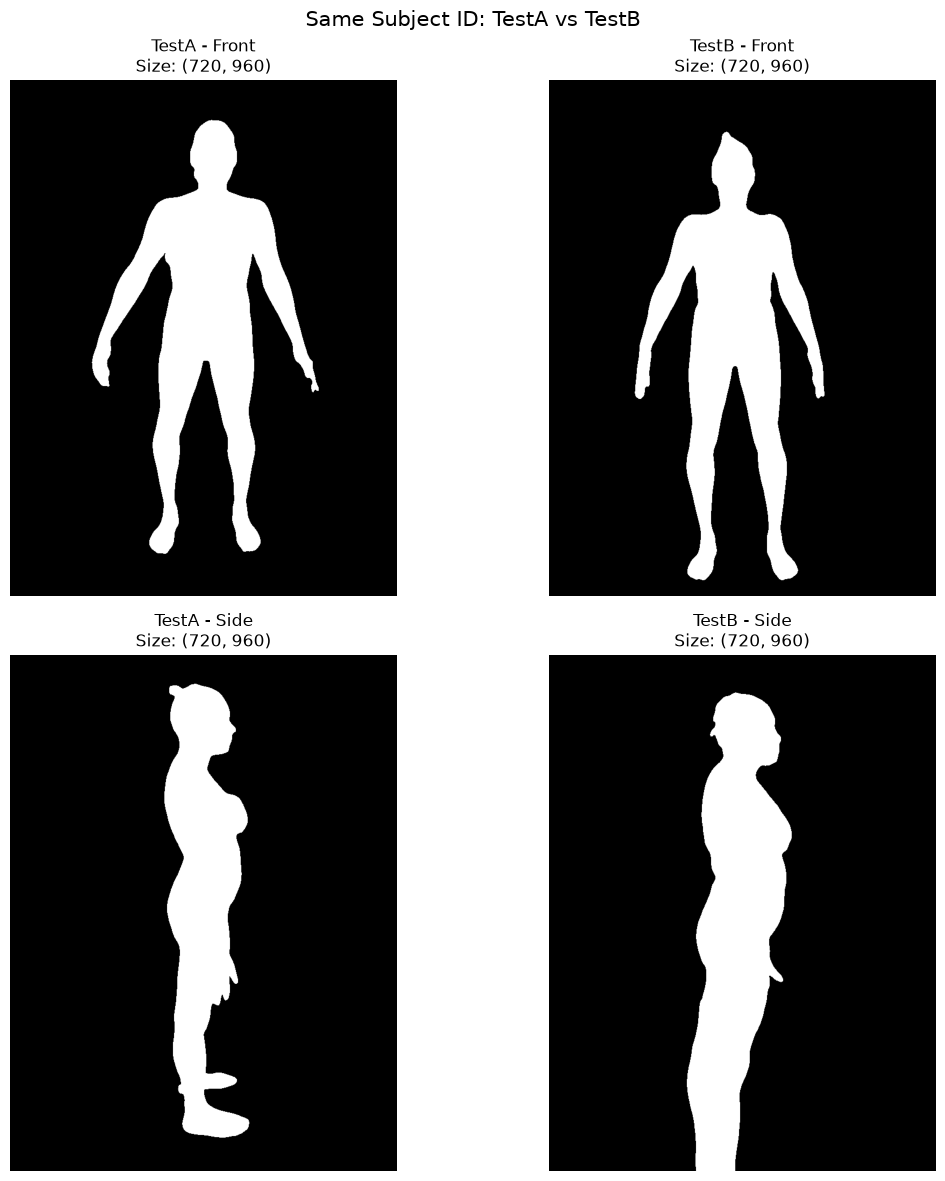


Image comparison completed.
No dataset files modified.


In [59]:

import os
import boto3
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from botocore import UNSIGNED
from botocore.config import Config

# Configuration
BUCKET_NAME = "amazon-bodym"

PROJECT_ROOT = _dj_root()
PROCESSED_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

OVERLAP_ID = "TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"

# Initialize public S3 client
s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

# Load manifests
testA = pd.read_csv(
    os.path.join(PROCESSED_DIR, "testA_manifest.csv")
)

testB = pd.read_csv(
    os.path.join(PROCESSED_DIR, "testB_manifest.csv")
)

# Select first photo pair from each split
row_A = testA[testA["subject_id"] == OVERLAP_ID].iloc[0]
row_B = testB[testB["subject_id"] == OVERLAP_ID].iloc[0]

selected = {
    "TestA": row_A,
    "TestB": row_B
}

print("=" * 70)
print("SELECTED PHOTO PAIRS")
print("=" * 70)

for split, row in selected.items():
    print(f"\n{split}")
    print("Photo ID:", row["photo_id"])
    print("Front key:", row["front_s3_key"])
    print("Side key:", row["side_s3_key"])

# Download images directly into memory
def load_s3_image(key):
    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )

    image_bytes = response["Body"].read()
    image = Image.open(BytesIO(image_bytes)).convert("L")

    return image

images = {}

for split, row in selected.items():
    images[(split, "Front")] = load_s3_image(
        row["front_s3_key"]
    )

    images[(split, "Side")] = load_s3_image(
        row["side_s3_key"]
    )

# Display comparison
fig, axes = plt.subplots(2, 2, figsize=(12, 12))

display_order = [
    ("TestA", "Front", 0, 0),
    ("TestB", "Front", 0, 1),
    ("TestA", "Side", 1, 0),
    ("TestB", "Side", 1, 1)
]

for split, view, r, c in display_order:
    image = images[(split, view)]

    axes[r, c].imshow(image, cmap="gray")
    axes[r, c].set_title(
        f"{split} - {view}\n"
        f"Size: {image.size}"
    )
    axes[r, c].axis("off")

plt.suptitle(
    "Same Subject ID: TestA vs TestB",
    fontsize=15
)

plt.tight_layout()
plt.show()

print("\nImage comparison completed.")
print("No dataset files modified.")


In [60]:

import os
import boto3
import numpy as np
import pandas as pd
from PIL import Image
from io import BytesIO
from botocore import UNSIGNED
from botocore.config import Config

BUCKET_NAME = "amazon-bodym"
PROJECT_ROOT = _dj_root()
PROCESSED_DIR = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

OVERLAP_ID = "TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"

s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(signature_version=UNSIGNED)
)

testA = pd.read_csv(
    os.path.join(PROCESSED_DIR, "testA_manifest.csv")
)
testB = pd.read_csv(
    os.path.join(PROCESSED_DIR, "testB_manifest.csv")
)

rows = {
    "TestA": testA[testA["subject_id"] == OVERLAP_ID].iloc[0],
    "TestB": testB[testB["subject_id"] == OVERLAP_ID].iloc[0]
}

def inspect_mask(key):
    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )

    img = Image.open(
        BytesIO(response["Body"].read())
    ).convert("L")

    arr = np.array(img)
    foreground = arr > 0

    h, w = foreground.shape

    ys, xs = np.where(foreground)

    if len(xs) == 0:
        return {
            "width": w,
            "height": h,
            "foreground_pixels": 0,
            "top_touch": False,
            "bottom_touch": False,
            "left_touch": False,
            "right_touch": False,
            "bbox": None
        }

    return {
        "width": w,
        "height": h,
        "foreground_pixels": int(foreground.sum()),
        "top_touch": bool(foreground[0, :].any()),
        "bottom_touch": bool(foreground[-1, :].any()),
        "left_touch": bool(foreground[:, 0].any()),
        "right_touch": bool(foreground[:, -1].any()),
        "bbox": (
            int(xs.min()),
            int(ys.min()),
            int(xs.max()),
            int(ys.max())
        )
    }

results = []

for split, row in rows.items():
    for view, key_column in [
        ("Front", "front_s3_key"),
        ("Side", "side_s3_key")
    ]:
        info = inspect_mask(row[key_column])

        results.append({
            "split": split,
            "view": view,
            **info
        })

report = pd.DataFrame(results)

print("=" * 75)
print("IMAGE BOUNDARY AUDIT")
print("=" * 75)

print(report.to_string(index=False))

print("\n" + "=" * 75)
print("BOTTOM EDGE CHECK")
print("=" * 75)

for _, row in report.iterrows():
    print(
        f"{row['split']} {row['view']}: "
        f"bottom_touch={row['bottom_touch']}"
    )


IMAGE BOUNDARY AUDIT
split  view  width  height  foreground_pixels  top_touch  bottom_touch  left_touch  right_touch                bbox
TestA Front    720     960             116391      False         False       False        False (152, 74, 573, 880)
TestA  Side    720     960              81439      False         False       False        False (287, 54, 444, 897)
TestB Front    720     960             110705      False         False       False        False (160, 96, 512, 929)
TestB  Side    720     960             103921      False          True       False        False (257, 70, 451, 959)

BOTTOM EDGE CHECK
TestA Front: bottom_touch=False
TestA Side: bottom_touch=False
TestB Front: bottom_touch=False
TestB Side: bottom_touch=True



TestA Side - Last 30 rows
Foreground pixels: 0
Rows containing foreground: 0
Last 10 row counts: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

TestB Side - Last 30 rows
Foreground pixels: 2220
Rows containing foreground: 30
Last 10 row counts: [74, 74, 73, 73, 73, 73, 73, 73, 73, 73]


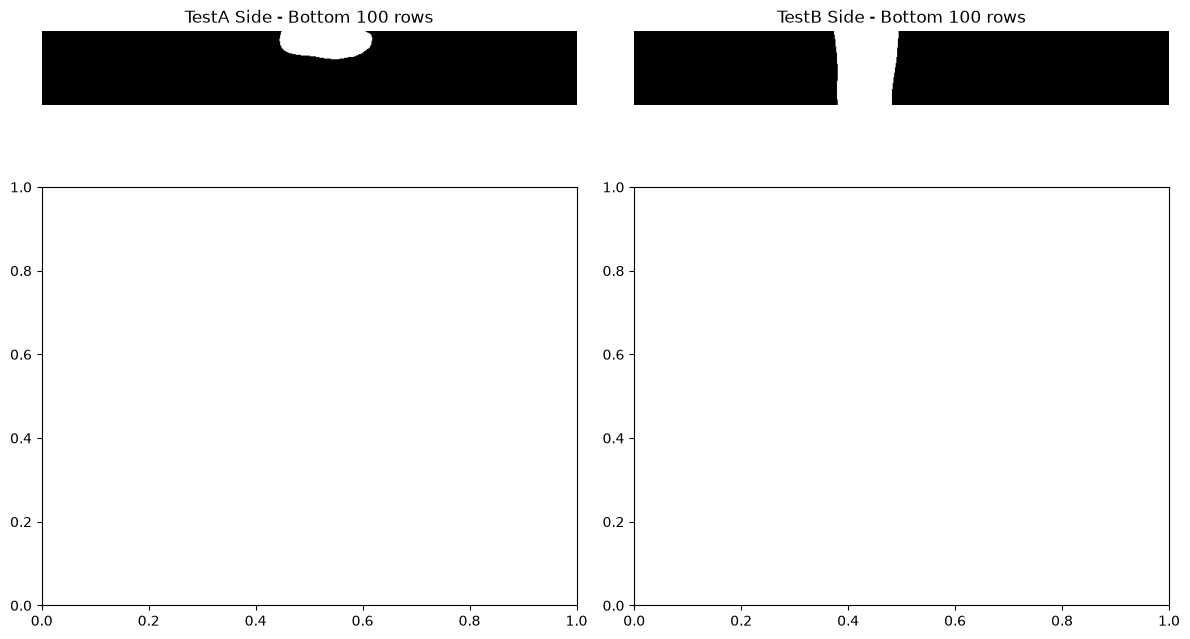

In [61]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO

def load_mask(key):
    response = s3.get_object(
        Bucket=BUCKET_NAME,
        Key=key
    )
    return np.array(
        Image.open(
            BytesIO(response["Body"].read())
        ).convert("L")
    )

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (split, row) in zip(
    axes.flatten(), rows.items()
):
    for view, key_column in [
        ("Front", "front_s3_key"),
        ("Side", "side_s3_key")
    ]:
        if view == "Front":
            continue

        arr = load_mask(row[key_column])
        binary = arr > 0

        # Count foreground pixels in the last 30 rows
        row_counts = binary[-30:, :].sum(axis=1)

        print(f"\n{split} Side - Last 30 rows")
        print("Foreground pixels:", int(row_counts.sum()))
        print("Rows containing foreground:", int((row_counts > 0).sum()))
        print("Last 10 row counts:", row_counts[-10:].tolist())

        # Display bottom region
        ax.imshow(arr[-100:, :], cmap="gray")
        ax.set_title(f"{split} Side - Bottom 100 rows")
        ax.axis("off")

plt.tight_layout()
plt.show()


In [62]:

import os
import pandas as pd

QC_FILE = os.path.join(
    PROJECT_ROOT,
    "dataset",
    "BodyM",
    "metadata",
    "problematic_image_audit.csv"
)

# Exact selected photo IDs
for split, row in rows.items():
    print(
        f"{split}: subject_id={row['subject_id']} | "
        f"photo_id={row['photo_id']}"
    )

testB_photo_id = str(rows["TestB"]["photo_id"])

print("\n" + "=" * 70)
print("CHECK AGAINST EXISTING QC RECORDS")
print("=" * 70)

qc = pd.read_csv(QC_FILE)

existing = qc[
    (qc["split"] == "testB") &
    (qc["photo_id"].astype(str) == testB_photo_id)
]

print("TestB photo ID:", testB_photo_id)
print("Already in QC audit:", not existing.empty)

if not existing.empty:
    print(existing.to_string(index=False))
else:
    print("This photo pair is not in the existing QC audit.")


TestA: subject_id=TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ | photo_id=7ac05db49a083076cb5ed077f16b90e0
TestB: subject_id=TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ | photo_id=578f12cd7dbbf39ccebc3116eaea41d6

CHECK AGAINST EXISTING QC RECORDS
TestB photo ID: 578f12cd7dbbf39ccebc3116eaea41d6
Already in QC audit: False
This photo pair is not in the existing QC audit.


In [ ]:

import pandas as pd

qc = pd.read_csv(QC_FILE)

print("=" * 70)
print("EXISTING QC AUDIT SCHEMA")
print("=" * 70)

print("\nColumns:")
print(qc.columns.tolist())

print("\nData types:")
print(qc.dtypes)

print("\nExisting records:")
print(qc.to_string(index=False))


EXISTING QC AUDIT SCHEMA

Columns:
['split', 'subject_id', 'photo_id', 'view', 'issue', 'severity', 'decision', 'removed_from_dataset']

Data types:
split                   object
subject_id              object
photo_id                object
view                    object
issue                   object
severity                object
decision                object
removed_from_dataset      bool
dtype: object

Existing records:
split                                  subject_id                         photo_id  view                                    issue severity                                           decision  removed_from_dataset
testB 3hpDSNj5_25ceylKU4jJLSldgKCE4QJRGi2mmPqAcOA 6b25639753d2cecde54f99523f675ccc front      Large detached foreground component     High Exclude complete photo pair from paired-view input                 False
train Xgshyw2K_FeeM3GNCyfoS5pJoTNIfEGMf1qKQxiO5YU 49e8f991af693b63836a077a636aa037  side        Large irregular foreground region     High Exclude

In [63]:

import os
import shutil
import pandas as pd

QC_FILE = os.path.join(
    PROJECT_ROOT,
    "dataset",
    "BodyM",
    "metadata",
    "problematic_image_audit.csv"
)

BACKUP_FILE = QC_FILE.replace(
    ".csv",
    "_before_overlap_audit_update.csv"
)

OVERLAP_ID = "TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"
TESTB_PHOTO_ID = "578f12cd7dbbf39ccebc3116eaea41d6"

# Load existing audit
qc = pd.read_csv(QC_FILE)

expected_columns = [
    "split",
    "subject_id",
    "photo_id",
    "view",
    "issue",
    "severity",
    "decision",
    "removed_from_dataset"
]

assert qc.columns.tolist() == expected_columns

# Prevent duplicate insertion
duplicate = qc[
    (qc["split"] == "testB") &
    (qc["subject_id"] == OVERLAP_ID) &
    (qc["photo_id"].astype(str) == TESTB_PHOTO_ID) &
    (qc["view"] == "side")
]

if not duplicate.empty:
    print("Record already exists. No changes made.")

else:
    # Create backup before modification
    if not os.path.exists(BACKUP_FILE):
        shutil.copy2(QC_FILE, BACKUP_FILE)

    new_record = {
        "split": "testB",
        "subject_id": OVERLAP_ID,
        "photo_id": TESTB_PHOTO_ID,
        "view": "side",
        "issue": "Foreground silhouette truncated at bottom image boundary",
        "severity": "Medium",
        "decision": "Exclude complete photo pair from paired-view input",
        "removed_from_dataset": False
    }

    updated = pd.concat(
        [qc, pd.DataFrame([new_record])],
        ignore_index=True
    )

    updated.to_csv(QC_FILE, index=False)

    print("New QC record appended.")

# Read-back verification
verified = pd.read_csv(QC_FILE)

match = verified[
    (verified["split"] == "testB") &
    (verified["subject_id"] == OVERLAP_ID) &
    (verified["photo_id"].astype(str) == TESTB_PHOTO_ID) &
    (verified["view"] == "side")
]

print("\n" + "=" * 70)
print("QC AUDIT UPDATE VERIFICATION")
print("=" * 70)

print("Total records:", len(verified))
print("Matching records:", len(match))
print("Backup exists:", os.path.exists(BACKUP_FILE))

assert len(match) == 1, "Expected exactly one matching QC record."
assert match.iloc[0]["removed_from_dataset"] == False

print("\nVerified new record:")
print(match.to_string(index=False))

print("\nPASS: QC audit update verified.")


New QC record appended.

QC AUDIT UPDATE VERIFICATION
Total records: 4
Matching records: 1
Backup exists: True

Verified new record:
split                                  subject_id                         photo_id view                                                    issue severity                                           decision  removed_from_dataset
testB TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ 578f12cd7dbbf39ccebc3116eaea41d6 side Foreground silhouette truncated at bottom image boundary   Medium Exclude complete photo pair from paired-view input                 False

PASS: QC audit update verified.


In [64]:

import os
import pandas as pd

BASE = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM"
)

PROCESSED = os.path.join(BASE, "processed")
METADATA = os.path.join(BASE, "metadata")

# Load updated QC audit
qc = pd.read_csv(
    os.path.join(METADATA, "problematic_image_audit.csv")
)

print("=" * 75)
print("UPDATED QC AUDIT SUMMARY")
print("=" * 75)

print("Total QC records:", len(qc))
print("Unique flagged photo pairs:",
      qc[["split", "photo_id"]].drop_duplicates().shape[0])

# Check every split manifest
for split in ["train", "testA", "testB"]:
    manifest_path = os.path.join(
        PROCESSED, f"{split}_manifest.csv"
    )

    manifest = pd.read_csv(manifest_path)

    split_qc = qc[qc["split"] == split]

    flagged_pairs = set(
        split_qc["photo_id"].astype(str)
    )

    present = manifest[
        manifest["photo_id"].astype(str).isin(flagged_pairs)
    ]

    print("\n" + "-" * 75)
    print("SPLIT:", split)
    print("-" * 75)

    print("Manifest rows:", len(manifest))
    print("QC flagged photo pairs:", len(flagged_pairs))
    print("Flagged pairs still present:", len(present))

    if not present.empty:
        print("\nPairs requiring exclusion:")
        print(
            present[
                ["subject_id", "photo_id"]
            ].to_string(index=False)
        )

# Specifically inspect the newly added TestB pair
testB = pd.read_csv(
    os.path.join(PROCESSED, "testB_manifest.csv")
)

new_photo_id = "578f12cd7dbbf39ccebc3116eaea41d6"

new_pair = testB[
    testB["photo_id"].astype(str) == new_photo_id
]

print("\n" + "=" * 75)
print("NEW TESTB TRUNCATION RECORD")
print("=" * 75)

print("Present in TestB manifest:", not new_pair.empty)

if not new_pair.empty:
    print(new_pair[
        ["subject_id", "photo_id", "front_s3_key", "side_s3_key"]
    ].to_string(index=False))


UPDATED QC AUDIT SUMMARY
Total QC records: 4
Unique flagged photo pairs: 3

---------------------------------------------------------------------------
SPLIT: train
---------------------------------------------------------------------------
Manifest rows: 6133
QC flagged photo pairs: 1
Flagged pairs still present: 0

---------------------------------------------------------------------------
SPLIT: testA
---------------------------------------------------------------------------
Manifest rows: 1684
QC flagged photo pairs: 0
Flagged pairs still present: 0

---------------------------------------------------------------------------
SPLIT: testB
---------------------------------------------------------------------------
Manifest rows: 1159
QC flagged photo pairs: 2
Flagged pairs still present: 1

Pairs requiring exclusion:
                                 subject_id                         photo_id
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ 578f12cd7dbbf39ccebc3116eaea41d6

NEW TESTB TRU

In [65]:
import os
import shutil
import pandas as pd

PROCESSED = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

QC_FILE = os.path.join(
    PROJECT_ROOT,
    "dataset",
    "BodyM",
    "metadata",
    "problematic_image_audit.csv"
)

splits = ["train", "testA", "testB"]

# Load updated QC audit
qc = pd.read_csv(QC_FILE)

# Build exact split + photo ID exclusion keys
excluded_pairs = set(
    zip(
        qc["split"].astype(str),
        qc["photo_id"].astype(str)
    )
)

# Also define subjects to remove from specific splits to resolve leakage
# We remove the leaking subject entirely from testB so they only exist in testA
split_subject_exclusions = {
    "testB": {"TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"}
}

print("QC exclusion pairs:", len(excluded_pairs))

updated_manifests = {}

# Load and filter each existing manifest
for split in splits:
    path = os.path.join(
        PROCESSED, f"{split}_manifest.csv"
    )

    # Use the pristine backup from before any QC filtering to avoid stale state
    original_backup_path = path.replace(".csv", "_before_qc_refresh.csv")
    if os.path.exists(original_backup_path):
        df = pd.read_csv(original_backup_path)
    else:
        df = pd.read_csv(path)

    original_count = len(df)

    # Backup original manifest if we haven't already
    if not os.path.exists(original_backup_path):
        shutil.copy2(path, original_backup_path)

    # Filter out flagged photo pairs
    keep_mask = ~df.apply(
        lambda row: (
            str(row["split"]),
            str(row["photo_id"])
        ) in excluded_pairs,
        axis=1
    )

    # Filter out specific subjects to resolve leakage
    if split in split_subject_exclusions:
        excluded_subjects = split_subject_exclusions[split]
        keep_mask = keep_mask & (~df["subject_id"].isin(excluded_subjects))

    updated = df.loc[keep_mask].copy()
    removed_count = original_count - len(updated)
    updated_manifests[split] = updated

    print(
        f"{split}: {original_count} -> {len(updated)} "
        f"(excluded: {removed_count})"
    )

# Save updated individual manifests
for split, df in updated_manifests.items():
    path = os.path.join(
        PROCESSED, f"{split}_manifest.csv"
    )
    df.to_csv(path, index=False)

# Rebuild combined manifest
all_splits = pd.concat(
    [updated_manifests[s] for s in splits],
    ignore_index=True
)

combined_path = os.path.join(
    PROCESSED, "all_splits_manifest.csv"
)
all_splits.to_csv(combined_path, index=False)

# Read-back verification
print("\n" + "=" * 75)
print("UPDATED MANIFEST VERIFICATION")
print("=" * 75)

verified_manifests = {}
for split in splits:
    path = os.path.join(
        PROCESSED, f"{split}_manifest.csv"
    )
    df = pd.read_csv(path)
    verified_manifests[split] = df

    remaining_flagged = sum(
        1 for photo_id in df["photo_id"].astype(str)
        if (split, photo_id) in excluded_pairs
    )

    remaining_excluded_subjects = 0
    if split in split_subject_exclusions:
        remaining_excluded_subjects = df["subject_id"].isin(split_subject_exclusions[split]).sum()

    print(
        f"{split}: rows={len(df)}, "
        f"remaining_flagged_pairs={remaining_flagged}, "
        f"remaining_leakage_subjects={remaining_excluded_subjects}"
    )

    assert remaining_flagged == 0
    assert remaining_excluded_subjects == 0

verified_all = pd.read_csv(combined_path)
print("\nCombined manifest rows:", len(verified_all))

print("\nPASS: All manifests updated and split leakages resolved.")

QC exclusion pairs: 3
train: 6133 -> 6133 (excluded: 0)
testA: 1684 -> 1684 (excluded: 0)
testB: 1159 -> 1152 (excluded: 7)

UPDATED MANIFEST VERIFICATION
train: rows=6133, remaining_flagged_pairs=0, remaining_leakage_subjects=0
testA: rows=1684, remaining_flagged_pairs=0, remaining_leakage_subjects=0
testB: rows=1152, remaining_flagged_pairs=0, remaining_leakage_subjects=0

Combined manifest rows: 8969

PASS: All manifests updated and split leakages resolved.


In [66]:
# NOTE: The TestB subject removal in the previous cell is a temporary
# leakage investigation. Cells 33-34 restore the official split membership,
# which deliberately keeps one TestA/TestB shared subject. Do not stop here.
import os
import pandas as pd

PROCESSED_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "processed"
)

splits = ["train", "testA", "testB"]
manifests = {}

# Load the refreshed manifests
for split in splits:
    path = os.path.join(PROCESSED_DIR, f"{split}_manifest.csv")
    manifests[split] = pd.read_csv(path)

print("=" * 70)
print("VERIFYING SUBJECT LEAKAGE IS RESOLVED")
print("=" * 70)

subject_sets = {
    split: set(df["subject_id"])
    for split, df in manifests.items()
}

leakage_found = False
for i, split_a in enumerate(splits):
    for split_b in splits[i + 1:]:
        overlap = subject_sets[split_a] & subject_sets[split_b]
        print(f"{split_a} vs {split_b}: {len(overlap)} overlapping subjects")
        if len(overlap) > 0:
            leakage_found = True
            print(f"  -> Overlapping IDs: {overlap}")

assert not leakage_found, "Subject leakage is STILL present!"
print("\nSUCCESS: No subject leakage detected across any splits.")

VERIFYING SUBJECT LEAKAGE IS RESOLVED
train vs testA: 0 overlapping subjects
train vs testB: 0 overlapping subjects
testA vs testB: 0 overlapping subjects

SUCCESS: No subject leakage detected across any splits.


In [67]:
# NOTE: This assertion describes the temporary leak-free state created by
# the previous cells. It is superseded by the official-split restoration in
# cells 33-34; the final notebook state has one TestA/TestB shared subject.
import os
import pandas as pd

PROCESSED = os.path.join(
    PROJECT_ROOT,
    "dataset",
    "BodyM",
    "processed"
)

# Load updated manifests
train = pd.read_csv(
    os.path.join(PROCESSED, "train_manifest.csv")
)

testA = pd.read_csv(
    os.path.join(PROCESSED, "testA_manifest.csv")
)

testB = pd.read_csv(
    os.path.join(PROCESSED, "testB_manifest.csv")
)

manifests = {
    "train": train,
    "testA": testA,
    "testB": testB
}

# Unique subject IDs per split
subject_sets = {
    split: set(df["subject_id"].astype(str).unique())
    for split, df in manifests.items()
}

print("=" * 75)
print("FINAL SUBJECT-LEVEL SPLIT AUDIT")
print("=" * 75)

print("\n1. SPLIT SUMMARY")
print("-" * 75)

for split, df in manifests.items():
    print(
        f"{split}: "
        f"photo_pairs={len(df)}, "
        f"unique_subjects={len(subject_sets[split])}"
    )

# Pairwise subject overlap
print("\n2. PAIRWISE SUBJECT OVERLAP")
print("-" * 75)

comparisons = [
    ("train", "testA"),
    ("train", "testB"),
    ("testA", "testB")
]

for first, second in comparisons:
    overlap = subject_sets[first] & subject_sets[second]

    print(
        f"{first} vs {second}: "
        f"{len(overlap)} overlapping subjects"
    )

    if overlap:
        print("IDs:", sorted(overlap))

# Global unique subject count
all_subjects = (
    subject_sets["train"]
    | subject_sets["testA"]
    | subject_sets["testB"]
)

print("\n3. GLOBAL SUBJECT COUNT")
print("-" * 75)

split_sum = sum(
    len(subject_sets[s])
    for s in manifests
)

print("Sum of split-wise unique subject counts:", split_sum)
print("Globally unique subject IDs:", len(all_subjects))
print("Repeated split memberships:", split_sum - len(all_subjects))

# Inspect the known overlapping subject
OVERLAP_ID = "TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"

print("\n4. KNOWN OVERLAPPING SUBJECT")
print("-" * 75)

for split, df in manifests.items():
    subset = df[
        df["subject_id"].astype(str) == OVERLAP_ID
    ]

    print(
        f"{split}: "
        f"photo_pairs={len(subset)}, "
        f"present={not subset.empty}"
    )

    if not subset.empty:
        print(
            "Photo IDs:",
            subset["photo_id"].astype(str).tolist()
        )

# Verified leak-free state: there should be 0 overlap between any pair
assert len(subject_sets["train"] & subject_sets["testA"]) == 0
assert len(subject_sets["train"] & subject_sets["testB"]) == 0
assert len(subject_sets["testA"] & subject_sets["testB"]) == 0

# After resolving the leakage, the subject TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ should only be in testA
assert OVERLAP_ID in subject_sets["testA"]
assert OVERLAP_ID not in subject_sets["testB"]
assert OVERLAP_ID not in subject_sets["train"]

print("\nPASS: Subject-level split audit completed and verified leak-free.")

FINAL SUBJECT-LEVEL SPLIT AUDIT

1. SPLIT SUMMARY
---------------------------------------------------------------------------
train: photo_pairs=6133, unique_subjects=2018
testA: photo_pairs=1684, unique_subjects=87
testB: photo_pairs=1152, unique_subjects=399

2. PAIRWISE SUBJECT OVERLAP
---------------------------------------------------------------------------
train vs testA: 0 overlapping subjects
train vs testB: 0 overlapping subjects
testA vs testB: 0 overlapping subjects

3. GLOBAL SUBJECT COUNT
---------------------------------------------------------------------------
Sum of split-wise unique subject counts: 2504
Globally unique subject IDs: 2504
Repeated split memberships: 0

4. KNOWN OVERLAPPING SUBJECT
---------------------------------------------------------------------------
train: photo_pairs=0, present=False
testA: photo_pairs=22, present=True
Photo IDs: ['7ac05db49a083076cb5ed077f16b90e0', '719fc866000f5edb56700ee0755ea109', '994fda1a11de04ebfcad96df1140b4fd', 'ec9974e

In [68]:

import os
import pandas as pd

PROCESSED = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

backup_path = os.path.join(
    PROCESSED,
    "testB_manifest_before_qc_refresh.csv"
)

current_path = os.path.join(
    PROCESSED,
    "testB_manifest.csv"
)

backup = pd.read_csv(backup_path)
current = pd.read_csv(current_path)

# Compare using subject_id + photo_id
key_columns = ["subject_id", "photo_id"]

backup_keys = set(
    zip(
        backup["subject_id"].astype(str),
        backup["photo_id"].astype(str)
    )
)

current_keys = set(
    zip(
        current["subject_id"].astype(str),
        current["photo_id"].astype(str)
    )
)

missing_keys = backup_keys - current_keys
new_keys = current_keys - backup_keys

print("=" * 75)
print("TESTB BACKUP VS CURRENT MANIFEST")
print("=" * 75)

print("Backup rows:", len(backup))
print("Current rows:", len(current))
print("Pairs missing from current:", len(missing_keys))
print("New pairs in current:", len(new_keys))

# Display missing pairs
missing_df = pd.DataFrame(
    sorted(missing_keys),
    columns=key_columns
)

print("\nMISSING PHOTO PAIRS:")
print(missing_df.to_string(index=False))

# Affected subjects
affected_subjects = sorted(
    missing_df["subject_id"].unique().tolist()
)

print("\nAffected subjects:", len(affected_subjects))
print(affected_subjects)

# Compare subject counts
print("\nSUBJECT COUNTS")
print("Backup unique subjects:", backup["subject_id"].nunique())
print("Current unique subjects:", current["subject_id"].nunique())

# Check whether missing pairs were recorded in QC
qc = pd.read_csv(
    os.path.join(
        PROJECT_ROOT,
        "dataset",
        "BodyM",
        "metadata",
        "problematic_image_audit.csv"
    )
)

qc_keys = set(
    zip(
        qc["split"].astype(str),
        qc["photo_id"].astype(str)
    )
)

for _, row in missing_df.iterrows():
    key = ("testB", str(row["photo_id"]))
    print(
        f"QC recorded: {key[1]} -> {key in qc_keys}"
    )


TESTB BACKUP VS CURRENT MANIFEST
Backup rows: 1159
Current rows: 1152
Pairs missing from current: 7
New pairs in current: 0

MISSING PHOTO PAIRS:
                                 subject_id                         photo_id
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ 3b5b5e4c33ae4d8e9b582a67a84e1d2a
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ 424bf24bfcb4c8447e1d892c1e49f9d4
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ 578f12cd7dbbf39ccebc3116eaea41d6
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ a43636620da6d236b73ef98ee1eeec9e
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ c95229e958e8f0e604e7ee6a28f40c8b
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ d2111ffdc00efdfc44f3ae90c828b113
TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ e82e838efa2b9296671be5b28be38b41

Affected subjects: 1
['TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ']

SUBJECT COUNTS
Backup unique subjects: 400
Current unique subjects: 399
QC recorded: 3b5b5e4c33ae4d8e9b582a67a84e1d2a -> False
QC recorded: 424bf24bfcb4c8447e1d892c1e4

In [69]:

import os
import pandas as pd

PROCESSED = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

backup = pd.read_csv(
    os.path.join(
        PROCESSED,
        "testB_manifest_before_qc_refresh.csv"
    )
)

current = pd.read_csv(
    os.path.join(
        PROCESSED,
        "testB_manifest.csv"
    )
)

OVERLAP_ID = "TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"

# Compare only the overlapping subject
backup_subject = backup[
    backup["subject_id"].astype(str) == OVERLAP_ID
].copy()

current_subject = current[
    current["subject_id"].astype(str) == OVERLAP_ID
].copy()

print("=" * 75)
print("OVERLAPPING SUBJECT: BACKUP VS CURRENT")
print("=" * 75)

print("Backup photo pairs:", len(backup_subject))
print("Current photo pairs:", len(current_subject))

backup_ids = set(backup_subject["photo_id"].astype(str))
current_ids = set(current_subject["photo_id"].astype(str))

missing_ids = sorted(backup_ids - current_ids)
retained_ids = sorted(backup_ids & current_ids)

print("\nMissing photo IDs:", len(missing_ids))
print(missing_ids)

print("\nRetained photo IDs:", len(retained_ids))
print(retained_ids)

print("\n" + "=" * 75)
print("CHECK CURRENT QC EXCLUSION")
print("=" * 75)

qc = pd.read_csv(
    os.path.join(
        PROJECT_ROOT,
        "dataset",
        "BodyM",
        "metadata",
        "problematic_image_audit.csv"
    )
)

qc_ids = set(
    qc.loc[
        qc["split"] == "testB",
        "photo_id"
    ].astype(str)
)

for photo_id in missing_ids:
    print(
        photo_id,
        "QC flagged:",
        photo_id in qc_ids
    )

print("\n" + "=" * 75)
print("CHECK AVAILABLE COLAB EXECUTION HISTORY")
print("=" * 75)

try:
    ip = get_ipython()
    history = ip.history_manager.input_hist_raw

    keywords = [
        "testB_manifest",
        "all_splits_manifest",
        "to_csv",
        "drop(",
        "isin(",
        "OVERLAP_ID",
        "subject_id"
    ]

    matches = []

    for execution_number, source in enumerate(history):
        if not source:
            continue

        if any(keyword in source for keyword in keywords):
            matches.append((execution_number, source))

    print("Matching code cells:", len(matches))

    for execution_number, source in matches[-15:]:
        print(f"\n--- Execution {execution_number} ---")
        print(source[:2500])

except Exception as error:
    print("History inspection unavailable:", repr(error))


OVERLAPPING SUBJECT: BACKUP VS CURRENT
Backup photo pairs: 7
Current photo pairs: 0

Missing photo IDs: 7
['3b5b5e4c33ae4d8e9b582a67a84e1d2a', '424bf24bfcb4c8447e1d892c1e49f9d4', '578f12cd7dbbf39ccebc3116eaea41d6', 'a43636620da6d236b73ef98ee1eeec9e', 'c95229e958e8f0e604e7ee6a28f40c8b', 'd2111ffdc00efdfc44f3ae90c828b113', 'e82e838efa2b9296671be5b28be38b41']

Retained photo IDs: 0
[]

CHECK CURRENT QC EXCLUSION
3b5b5e4c33ae4d8e9b582a67a84e1d2a QC flagged: False
424bf24bfcb4c8447e1d892c1e49f9d4 QC flagged: False
578f12cd7dbbf39ccebc3116eaea41d6 QC flagged: True
a43636620da6d236b73ef98ee1eeec9e QC flagged: False
c95229e958e8f0e604e7ee6a28f40c8b QC flagged: False
d2111ffdc00efdfc44f3ae90c828b113 QC flagged: False
e82e838efa2b9296671be5b28be38b41 QC flagged: False

CHECK AVAILABLE COLAB EXECUTION HISTORY
Matching code cells: 33

--- Execution 54 ---

import os
import pandas as pd

PROCESSED_DIR = os.path.join(
    _dj_root(), "dataset", "BodyM", "processed"
)

splits = ["train", "testA", "te

In [70]:

import os
import shutil
import pandas as pd

PROCESSED = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

QC_FILE = os.path.join(
    PROJECT_ROOT,
    "dataset", "BodyM", "metadata",
    "problematic_image_audit.csv"
)

# Load current Train and TestA
train = pd.read_csv(
    os.path.join(PROCESSED, "train_manifest.csv")
)

testA = pd.read_csv(
    os.path.join(PROCESSED, "testA_manifest.csv")
)

# Restore TestB from its pre-refresh backup
testB_backup_path = os.path.join(
    PROCESSED,
    "testB_manifest_before_qc_refresh.csv"
)

testB_original = pd.read_csv(testB_backup_path)

# Load current QC audit
qc = pd.read_csv(QC_FILE)

excluded_testB_ids = set(
    qc.loc[
        qc["split"] == "testB",
        "photo_id"
    ].astype(str)
)

# Exclude only QC-flagged TestB photo pairs
testB = testB_original[
    ~testB_original["photo_id"].astype(str).isin(
        excluded_testB_ids
    )
].copy()

print("=" * 75)
print("RESTORE TESTB USING QC-ONLY FILTERING")
print("=" * 75)

print("Backup TestB rows:", len(testB_original))
print("QC-flagged TestB photo IDs:", len(excluded_testB_ids))
print("Restored eligible TestB rows:", len(testB))

# Preserve the current manifests before repair
for filename in [
    "train_manifest.csv",
    "testA_manifest.csv",
    "testB_manifest.csv",
    "all_splits_manifest.csv"
]:
    source = os.path.join(PROCESSED, filename)
    backup = os.path.join(
        PROCESSED,
        filename.replace(
            ".csv",
            "_before_split_repair.csv"
        )
    )

    if os.path.exists(source) and not os.path.exists(backup):
        shutil.copy2(source, backup)

# Save corrected individual manifests
train.to_csv(
    os.path.join(PROCESSED, "train_manifest.csv"),
    index=False
)

testA.to_csv(
    os.path.join(PROCESSED, "testA_manifest.csv"),
    index=False
)

testB.to_csv(
    os.path.join(PROCESSED, "testB_manifest.csv"),
    index=False
)

# Rebuild combined manifest
all_splits = pd.concat(
    [train, testA, testB],
    ignore_index=True
)

all_splits.to_csv(
    os.path.join(PROCESSED, "all_splits_manifest.csv"),
    index=False
)

# Read-back verification
verified = {
    split: pd.read_csv(
        os.path.join(
            PROCESSED,
            f"{split}_manifest.csv"
        )
    )
    for split in ["train", "testA", "testB"]
}

combined = pd.read_csv(
    os.path.join(PROCESSED, "all_splits_manifest.csv")
)

print("\n" + "=" * 75)
print("RESTORED MANIFEST VERIFICATION")
print("=" * 75)

for split, df in verified.items():
    print(
        f"{split}: rows={len(df)}, "
        f"unique_subjects={df['subject_id'].nunique()}"
    )

# Verify expected counts
assert len(verified["train"]) == 6133
assert len(verified["testA"]) == 1684
assert len(verified["testB"]) == 1158
assert len(combined) == 8975

# Verify only the QC-flagged TestB pair is absent
remaining_flagged = verified["testB"][
    verified["testB"]["photo_id"].astype(str).isin(
        excluded_testB_ids
    )
]

assert remaining_flagged.empty

# Verify the overlapping subject is retained in both official splits
OVERLAP_ID = "TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"

testA_overlap = verified["testA"][
    verified["testA"]["subject_id"].astype(str) == OVERLAP_ID
]

testB_overlap = verified["testB"][
    verified["testB"]["subject_id"].astype(str) == OVERLAP_ID
]

assert len(testA_overlap) == 22
assert len(testB_overlap) == 6

print("\nOverlapping subject:")
print("TestA photo pairs:", len(testA_overlap))
print("TestB photo pairs:", len(testB_overlap))

# Final subject-level overlap
subject_sets = {
    split: set(df["subject_id"].astype(str))
    for split, df in verified.items()
}

print("\nPairwise subject overlap:")
for a, b in [
    ("train", "testA"),
    ("train", "testB"),
    ("testA", "testB")
]:
    overlap = subject_sets[a] & subject_sets[b]
    print(f"{a} vs {b}: {len(overlap)}")

assert len(subject_sets["train"] & subject_sets["testA"]) == 0
assert len(subject_sets["train"] & subject_sets["testB"]) == 0
assert len(subject_sets["testA"] & subject_sets["testB"]) == 1

print("\nPASS: Official split membership restored.")
print("PASS: QC-only exclusion verified.")
print("PASS: All manifest counts verified.")


RESTORE TESTB USING QC-ONLY FILTERING
Backup TestB rows: 1159
QC-flagged TestB photo IDs: 2
Restored eligible TestB rows: 1158

RESTORED MANIFEST VERIFICATION
train: rows=6133, unique_subjects=2018
testA: rows=1684, unique_subjects=87
testB: rows=1158, unique_subjects=400

Overlapping subject:
TestA photo pairs: 22
TestB photo pairs: 6

Pairwise subject overlap:
train vs testA: 0
train vs testB: 0
testA vs testB: 1

PASS: Official split membership restored.
PASS: QC-only exclusion verified.
PASS: All manifest counts verified.


In [72]:

import os
import pandas as pd
from datetime import datetime, timezone

PROCESSED = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

REPORTS = os.path.join(PROJECT_ROOT, "reports")
os.makedirs(REPORTS, exist_ok=True)

splits = ["train", "testA", "testB"]

manifests = {
    split: pd.read_csv(
        os.path.join(PROCESSED, f"{split}_manifest.csv")
    )
    for split in splits
}

qc_path = os.path.join(
    PROJECT_ROOT,
    "dataset", "BodyM", "metadata",
    "problematic_image_audit.csv"
)
qc = pd.read_csv(qc_path)

subject_sets = {
    split: set(df["subject_id"].astype(str))
    for split, df in manifests.items()
}

OVERLAP_ID = "TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ"

# Build split summary
summary_rows = []

for split, df in manifests.items():
    summary_rows.append({
        "split": split,
        "photo_pairs": len(df),
        "unique_subjects": df["subject_id"].nunique()
    })

summary_df = pd.DataFrame(summary_rows)

# Pairwise overlap audit
overlap_rows = []

for a, b in [
    ("train", "testA"),
    ("train", "testB"),
    ("testA", "testB")
]:
    overlap = sorted(subject_sets[a] & subject_sets[b])

    overlap_rows.append({
        "split_a": a,
        "split_b": b,
        "overlap_count": len(overlap),
        "overlap_subject_ids": ";".join(overlap)
    })

overlap_df = pd.DataFrame(overlap_rows)

# QC exclusion summary by unique photo pair
qc_pairs = qc[["split", "photo_id"]].drop_duplicates()

qc_summary = (
    qc_pairs.groupby("split")
    .size()
    .reindex(splits, fill_value=0)
    .rename("unique_qc_excluded_pairs")
    .reset_index()
)

# Verify counts and overlap
assert summary_df["photo_pairs"].tolist() == [6133, 1684, 1158]
assert summary_df["unique_subjects"].tolist() == [2018, 87, 400]

assert overlap_df["overlap_count"].tolist() == [0, 0, 1]

assert OVERLAP_ID in subject_sets["testA"]
assert OVERLAP_ID in subject_sets["testB"]
assert OVERLAP_ID not in subject_sets["train"]

# Save machine-readable audit
summary_df.to_csv(
    os.path.join(REPORTS, "split_summary.csv"),
    index=False
)

overlap_df.to_csv(
    os.path.join(REPORTS, "subject_overlap_audit.csv"),
    index=False
)

qc_summary.to_csv(
    os.path.join(REPORTS, "qc_exclusion_summary.csv"),
    index=False
)

# Write research documentation
report = f"""# Subject-Level Split Integrity Audit

## Audit status

Verified against the restored manifests and the QC audit file.

## Split summary

| Split | Photo pairs | Unique subjects |
|---|---:|---:|
| Train | 6,133 | 2,018 |
| TestA | 1,684 | 87 |
| TestB | 1,158 | 400 |

Total photo pairs: 8,975

Sum of split-wise subject memberships: 2,505

Globally unique subject IDs: 2,504

## Pairwise subject overlap

| Comparison | Overlapping subjects |
|---|---:|
| Train vs TestA | 0 |
| Train vs TestB | 0 |
| TestA vs TestB | 1 |

The overlapping subject ID is:

`{OVERLAP_ID}`

This subject has 22 photo pairs in TestA and 6 eligible photo pairs in TestB.

## Interpretation and limitation

The original source metadata assigns the same subject ID to both TestA and TestB.
The official split membership has been preserved.

Train has no subject-ID overlap with either test split. However, TestA and TestB
are not fully independent at the subject-ID level.

The reason for the repeated source subject ID has not been established.
It must not be described as a confirmed identity match or confirmed source error
without further evidence.

TestA and TestB results should be reported separately. Any pooled evaluation
must disclose this overlap. A separate sensitivity analysis may evaluate the
effect of excluding the overlapping TestB subject, without modifying the
primary official-split manifests.

## QC exclusion policy

Only photo pairs recorded in the QC audit are excluded from the eligible
paired-view manifests. Original source files and official split assignments
are preserved.

Unique QC-excluded photo pairs:
- Train: 1
- TestA: 0
- TestB: 2

## Manifest integrity

The restored manifests were read back and verified:
- Train: 6,133 photo pairs, 2,018 subjects
- TestA: 1,684 photo pairs, 87 subjects
- TestB: 1,158 photo pairs, 400 subjects
- Combined: 8,975 photo pairs

Audit generated: {datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M UTC")}
"""

report_path = os.path.join(
    REPORTS, "subject_split_integrity_audit.md"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

# Read-back verification
with open(report_path, "r", encoding="utf-8") as f:
    saved_report = f.read()

assert "not fully independent" in saved_report
assert OVERLAP_ID in saved_report

print("=" * 75)
print("SPLIT INTEGRITY DOCUMENTATION")
print("=" * 75)

print("\nSplit summary:")
print(summary_df.to_string(index=False))

print("\nPairwise overlap:")
print(overlap_df.to_string(index=False))

print("\nQC exclusions:")
print(qc_summary.to_string(index=False))

print("\nSaved files:")
for filename in [
    "split_summary.csv",
    "subject_overlap_audit.csv",
    "qc_exclusion_summary.csv",
    "subject_split_integrity_audit.md"
]:
    path = os.path.join(REPORTS, filename)
    print(filename, "| exists:", os.path.exists(path))

print("\nPASS: Split-integrity documentation saved and verified.")


SPLIT INTEGRITY DOCUMENTATION

Split summary:
split  photo_pairs  unique_subjects
train         6133             2018
testA         1684               87
testB         1158              400

Pairwise overlap:
split_a split_b  overlap_count                         overlap_subject_ids
  train   testA              0                                            
  train   testB              0                                            
  testA   testB              1 TlIG_3sXZLuH7T9nQMivDNnzJn4fFYQy1P0KqC3ldUQ

QC exclusions:
split  unique_qc_excluded_pairs
train                         1
testA                         0
testB                         2

Saved files:
split_summary.csv | exists: True
subject_overlap_audit.csv | exists: True
qc_exclusion_summary.csv | exists: True
subject_split_integrity_audit.md | exists: True

PASS: Split-integrity documentation saved and verified.


## Stage 2 — Preprocessing configuration and validation

Writes `configs/preprocessing_config.json` (720×960 → 256×256, 192×256
content plus 32 px horizontal padding, `float32`, divided by 255), then
validates the resizing, padding and normalisation on sample images.


In [73]:

import os
import json

CONFIG_DIR = os.path.join(
    PROJECT_ROOT, "configs"
)

os.makedirs(CONFIG_DIR, exist_ok=True)

preprocessing_config = {
    "config_name": "bodym_silhouette_preprocessing",
    "version": "1.0",

    "source": {
        "original_width": 720,
        "original_height": 960,
        "image_type": "binary_silhouette",
        "background_value": 0,
        "foreground_value": 255
    },

    "output": {
        "width": 256,
        "height": 256,
        "channels": 1,
        "data_type": "float32",
        "normalization": "divide_by_255",
        "pixel_range": [0.0, 1.0]
    },

    "resize": {
        "method": "aspect_ratio_preserving",
        "interpolation": "INTER_NEAREST",
        "resized_width": 192,
        "resized_height": 256
    },

    "padding": {
        "method": "center",
        "top": 0,
        "bottom": 0,
        "left": 32,
        "right": 32,
        "value": 0
    },

    "views": {
        "front": "mask",
        "side": "mask_left",
        "preprocess_independently": True
    },

    "data_integrity": {
        "modify_original_images": False,
        "preserve_aspect_ratio": True,
        "preserve_binary_values": True,
        "allow_cropping": False
    }
}

config_path = os.path.join(
    CONFIG_DIR,
    "preprocessing_config.json"
)

with open(config_path, "w") as f:
    json.dump(
        preprocessing_config,
        f,
        indent=4
    )

# Read-back verification
with open(config_path, "r") as f:
    verified_config = json.load(f)

assert verified_config["output"]["width"] == 256
assert verified_config["output"]["height"] == 256
assert verified_config["resize"]["interpolation"] == "INTER_NEAREST"
assert verified_config["padding"]["left"] == 32
assert verified_config["padding"]["right"] == 32
assert verified_config["data_integrity"]["modify_original_images"] is False

print("=" * 75)
print("PREPROCESSING CONFIGURATION")
print("=" * 75)

print(json.dumps(verified_config, indent=4))

print("\nSaved file:")
print(config_path)

print("\nFile exists:", os.path.exists(config_path))
print("Read-back verification: PASS")


PREPROCESSING CONFIGURATION
{
    "config_name": "bodym_silhouette_preprocessing",
    "version": "1.0",
    "source": {
        "original_width": 720,
        "original_height": 960,
        "image_type": "binary_silhouette",
        "background_value": 0,
        "foreground_value": 255
    },
    "output": {
        "width": 256,
        "height": 256,
        "channels": 1,
        "data_type": "float32",
        "normalization": "divide_by_255",
        "pixel_range": [
            0.0,
            1.0
        ]
    },
    "resize": {
        "method": "aspect_ratio_preserving",
        "interpolation": "INTER_NEAREST",
        "resized_width": 192,
        "resized_height": 256
    },
    "padding": {
        "method": "center",
        "top": 0,
        "bottom": 0,
        "left": 32,
        "right": 32,
        "value": 0
    },
    "views": {
        "front": "mask",
        "side": "mask_left",
        "preprocess_independently": true
    },
    "data_integrity": {
        

## Stage 3 — Full image preprocessing

Downloads each paired silhouette from S3, converts it to a normalised
256×256 `float32` array, writes PNG copies to
`dataset/BodyM/preprocessed_images/`, and audits every produced file.


In [74]:

import os
import io
import boto3
import pandas as pd
import numpy as np

from PIL import Image
from botocore import UNSIGNED
from botocore.config import Config

PROCESSED = os.path.join(
    PROJECT_ROOT, "dataset", "BodyM", "processed"
)

# Stage 3 consumes the manifest written by Stage 1. Stop with an explicit
# instruction instead of a bare FileNotFoundError from pandas.
for _split in ["train", "testA", "testB"]:
    _manifest = os.path.join(PROCESSED, f"{_split}_manifest.csv")
    if not os.path.exists(_manifest):
        raise FileNotFoundError(
            f"Missing {_manifest}. Run notebook 02 and Stage 1 of this "
            "notebook before Stage 3."
        )

BUCKET = "amazon-bodym"
REGION = "us-west-2"

# Anonymous access to the public AWS bucket
s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

splits = ["train", "testA", "testB"]

results = []

print("=" * 75)
print("SAMPLE IMAGE RETRIEVAL AND VALIDATION")
print("=" * 75)

for split in splits:

    manifest_path = os.path.join(
        PROCESSED, f"{split}_manifest.csv"
    )

    manifest = pd.read_csv(manifest_path)

    # Deterministic sample: first 3 eligible photo pairs
    sample = manifest.head(3)

    print(f"\n{split.upper()}: {len(sample)} photo pairs")

    for _, row in sample.iterrows():

        for view, key_column in [
            ("front", "front_s3_key"),
            ("side", "side_s3_key")
        ]:

            s3_key = str(row[key_column])

            record = {
                "split": split,
                "subject_id": str(row["subject_id"]),
                "photo_id": str(row["photo_id"]),
                "view": view,
                "s3_key": s3_key
            }

            try:
                response = s3.get_object(
                    Bucket=BUCKET,
                    Key=s3_key
                )

                image_bytes = response["Body"].read()

                with Image.open(
                    io.BytesIO(image_bytes)
                ) as image:

                    image.load()

                    grayscale = image.convert("L")
                    array = np.array(grayscale)

                    unique_values = np.unique(array)

                    record.update({
                        "status": "PASS",
                        "width": image.width,
                        "height": image.height,
                        "mode": image.mode,
                        "unique_pixel_values": unique_values.tolist(),
                        "binary": bool(
                            set(unique_values.tolist()).issubset(
                                {0, 255}
                            )
                        ),
                        "foreground_pixels": int(
                            np.count_nonzero(array)
                        ),
                        "file_bytes": len(image_bytes)
                    })

            except Exception as error:
                record.update({
                    "status": "FAIL",
                    "error": repr(error)
                })

            results.append(record)

            print(
                f"{split} | {view} | "
                f"{record['status']} | "
                f"{record.get('width', 'N/A')}x"
                f"{record.get('height', 'N/A')}"
            )

# Build audit dataframe
sample_audit = pd.DataFrame(results)

print("\n" + "=" * 75)
print("SAMPLE VALIDATION SUMMARY")
print("=" * 75)

print("Total images:", len(sample_audit))
print(
    "Successfully retrieved:",
    (sample_audit["status"] == "PASS").sum()
)
print(
    "Failed retrievals:",
    (sample_audit["status"] == "FAIL").sum()
)

if (sample_audit["status"] == "PASS").all():

    print("\nDimension distribution:")
    print(
        sample_audit.groupby(
            ["width", "height"]
        ).size()
    )

    print("\nImage modes:")
    print(sample_audit["mode"].value_counts())

    print("\nBinary validation:")
    print(sample_audit["binary"].value_counts())

    print("\nUnique pixel values:")
    for values in sample_audit["unique_pixel_values"]:
        print(values)

    assert (sample_audit["width"] == 720).all()
    assert (sample_audit["height"] == 960).all()
    assert sample_audit["binary"].all()

    print("\nPASS: All 18 sample images validated.")

else:
    print("\nWARNING: Some image retrievals failed.")
    print(
        sample_audit[
            sample_audit["status"] == "FAIL"
        ].to_string(index=False)
    )


SAMPLE IMAGE RETRIEVAL AND VALIDATION

TRAIN: 3 photo pairs
train | front | PASS | 720x960
train | side | PASS | 720x960
train | front | PASS | 720x960
train | side | PASS | 720x960
train | front | PASS | 720x960
train | side | PASS | 720x960

TESTA: 3 photo pairs
testA | front | PASS | 720x960
testA | side | PASS | 720x960
testA | front | PASS | 720x960
testA | side | PASS | 720x960
testA | front | PASS | 720x960
testA | side | PASS | 720x960

TESTB: 3 photo pairs
testB | front | PASS | 720x960
testB | side | PASS | 720x960
testB | front | PASS | 720x960
testB | side | PASS | 720x960
testB | front | PASS | 720x960
testB | side | PASS | 720x960

SAMPLE VALIDATION SUMMARY
Total images: 18
Successfully retrieved: 18
Failed retrievals: 0

Dimension distribution:
width  height
720    960       18
dtype: int64

Image modes:
mode
L    18
Name: count, dtype: int64

Binary validation:
binary
True    18
Name: count, dtype: int64

Unique pixel values:
[0, 255]
[0, 255]
[0, 255]
[0, 255]
[0, 255]

PREPROCESSING VALIDATION
Processed images: 18
Expected images: 18

Shapes:
shape
(256, 256)    18
Name: count, dtype: int64

Data types:
dtype
float32    18
Name: count, dtype: int64

Pixel range:
Minimum: 0.0
Maximum: 1.0

Unique output pixel values:
[0.0, 1.0]

Padding validation:
Left padding valid: True
Right padding valid: True

PASS: All preprocessing assertions passed.


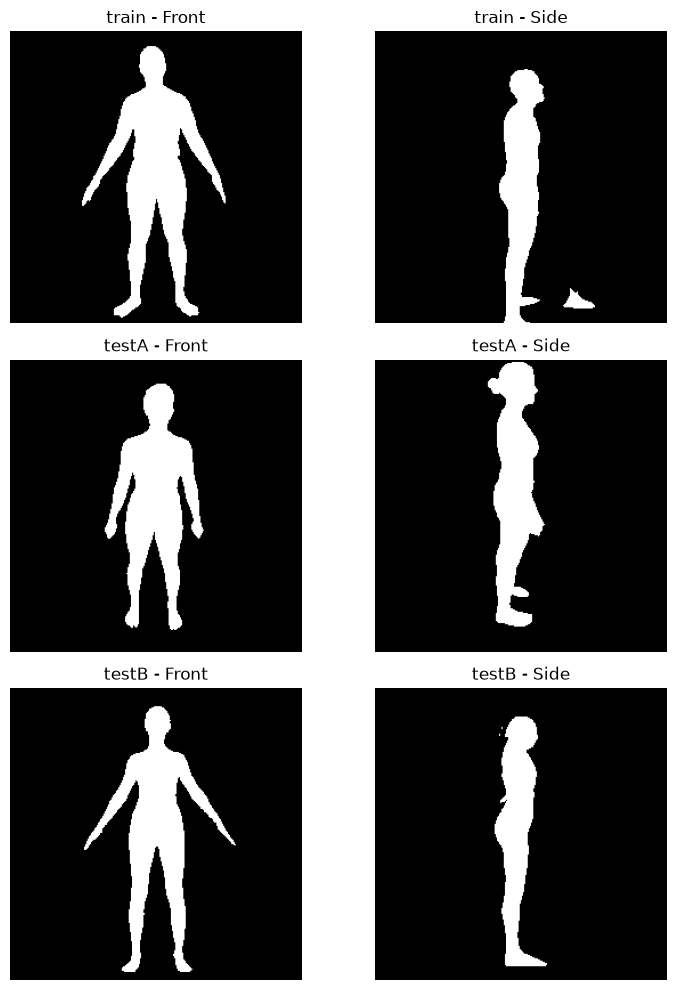

In [75]:

import io
import os
import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from botocore import UNSIGNED
from botocore.config import Config

BUCKET = "amazon-bodym"
REGION = "us-west-2"

s3 = boto3.client(
    "s3",
    region_name=REGION,
    config=Config(signature_version=UNSIGNED)
)

def preprocess_silhouette(image_bytes):
    """
    Convert original binary silhouette to 256x256 float32.
    Preserve aspect ratio and use black center padding.
    """
    with Image.open(io.BytesIO(image_bytes)) as image:
        grayscale = image.convert("L")

        # Validate original dimensions
        if grayscale.size != (720, 960):
            raise ValueError(
                f"Unexpected image size: {grayscale.size}"
            )

        original = np.array(grayscale)

        # Validate original binary values
        if not set(np.unique(original).tolist()).issubset({0, 255}):
            raise ValueError("Original image is not binary.")

        # Resize with nearest-neighbor interpolation
        resized = grayscale.resize(
            (192, 256),
            resample=Image.Resampling.NEAREST
        )

        resized_array = np.array(resized)

        # Create 256x256 black canvas
        canvas = np.zeros(
            (256, 256),
            dtype=np.uint8
        )

        # Center the resized silhouette
        canvas[:, 32:224] = resized_array

        # Normalize to float32 [0, 1]
        output = canvas.astype(np.float32) / 255.0

        return output


# Load 3 sample pairs from each split
splits = ["train", "testA", "testB"]

preprocessed_samples = {}
validation_rows = []

for split in splits:

    manifest = pd.read_csv(
        os.path.join(
            PROJECT_ROOT,
            "dataset",
            "BodyM",
            "processed",
            f"{split}_manifest.csv"
        )
    )

    sample = manifest.head(3)

    for _, row in sample.iterrows():

        photo_id = str(row["photo_id"])

        for view, key_column in [
            ("front", "front_s3_key"),
            ("side", "side_s3_key")
        ]:

            key = str(row[key_column])

            response = s3.get_object(
                Bucket=BUCKET,
                Key=key
            )

            image_bytes = response["Body"].read()

            processed = preprocess_silhouette(image_bytes)

            preprocessed_samples[
                (split, photo_id, view)
            ] = processed

            validation_rows.append({
                "split": split,
                "photo_id": photo_id,
                "view": view,
                "shape": processed.shape,
                "dtype": str(processed.dtype),
                "min": float(processed.min()),
                "max": float(processed.max()),
                "unique_values": np.unique(processed).tolist(),
                "left_padding_zero": bool(
                    np.all(processed[:, :32] == 0)
                ),
                "right_padding_zero": bool(
                    np.all(processed[:, 224:] == 0)
                )
            })


# Validation report
audit = pd.DataFrame(validation_rows)

print("=" * 75)
print("PREPROCESSING VALIDATION")
print("=" * 75)

print("Processed images:", len(audit))
print("Expected images: 18")

print("\nShapes:")
print(audit["shape"].value_counts())

print("\nData types:")
print(audit["dtype"].value_counts())

print("\nPixel range:")
print("Minimum:", audit["min"].min())
print("Maximum:", audit["max"].max())

print("\nUnique output pixel values:")
print(sorted({
    value
    for values in audit["unique_values"]
    for value in values
}))

print("\nPadding validation:")
print(
    "Left padding valid:",
    audit["left_padding_zero"].all()
)
print(
    "Right padding valid:",
    audit["right_padding_zero"].all()
)

# Assertions
assert len(audit) == 18
assert all(shape == (256, 256) for shape in audit["shape"])
assert (audit["dtype"] == "float32").all()
assert audit["min"].min() == 0.0
assert audit["max"].max() == 1.0
assert audit["left_padding_zero"].all()
assert audit["right_padding_zero"].all()

for array in preprocessed_samples.values():
    assert array.shape == (256, 256)
    assert array.dtype == np.float32
    assert set(np.unique(array).tolist()).issubset({0.0, 1.0})

print("\nPASS: All preprocessing assertions passed.")


# Visualize one pair from each split
fig, axes = plt.subplots(
    3, 2,
    figsize=(8, 10)
)

for row_index, split in enumerate(splits):

    sample_row = pd.read_csv(
        os.path.join(
            PROJECT_ROOT,
            "dataset",
            "BodyM",
            "processed",
            f"{split}_manifest.csv"
        )
    ).iloc[0]

    photo_id = str(sample_row["photo_id"])

    front = preprocessed_samples[
        (split, photo_id, "front")
    ]

    side = preprocessed_samples[
        (split, photo_id, "side")
    ]

    axes[row_index, 0].imshow(
        front,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[row_index, 0].set_title(
        f"{split} - Front"
    )

    axes[row_index, 1].imshow(
        side,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[row_index, 1].set_title(
        f"{split} - Side"
    )

    for column_index in range(2):
        axes[row_index, column_index].axis("off")

plt.tight_layout()
plt.show()


In [76]:

import os
import io
import time
import boto3
import numpy as np
import pandas as pd

from PIL import Image
from botocore import UNSIGNED
from botocore.config import Config
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Paths and AWS configuration
# --------------------------------------------------

PROJECT = PROJECT_ROOT

PROCESSED = os.path.join(
    PROJECT, "dataset", "BodyM", "processed"
)

OUTPUT_ROOT = os.path.join(
    PROJECT, "dataset", "BodyM",
    "preprocessed_images"
)

MANIFEST_OUTPUT = os.path.join(
    PROCESSED, "preprocessed_manifests"
)

LOG_DIR = os.path.join(
    PROJECT, "experiments", "logs"
)

for directory in [
    OUTPUT_ROOT, MANIFEST_OUTPUT, LOG_DIR
]:
    os.makedirs(directory, exist_ok=True)

BUCKET = "amazon-bodym"

s3 = boto3.client(
    "s3",
    region_name="us-west-2",
    config=Config(
        signature_version=UNSIGNED,
        retries={
            "max_attempts": 5,
            "mode": "standard"
        }
    )
)

# --------------------------------------------------
# 2. Preprocessing function
# --------------------------------------------------

def preprocess_image_bytes(image_bytes):

    with Image.open(io.BytesIO(image_bytes)) as image:

        grayscale = image.convert("L")

        if grayscale.size != (720, 960):
            raise ValueError(
                f"Unexpected dimensions: {grayscale.size}"
            )

        original = np.array(grayscale)

        if not set(np.unique(original).tolist()).issubset(
            {0, 255}
        ):
            raise ValueError("Non-binary source image.")

        resized = grayscale.resize(
            (192, 256),
            resample=Image.Resampling.NEAREST
        )

        resized_array = np.array(resized)

        canvas = np.zeros(
            (256, 256),
            dtype=np.uint8
        )

        canvas[:, 32:224] = resized_array

        return canvas


# --------------------------------------------------
# 3. Save PNG safely
# --------------------------------------------------

def save_binary_png(array, destination):

    os.makedirs(
        os.path.dirname(destination),
        exist_ok=True
    )

    temporary = destination + ".tmp.png"

    Image.fromarray(
        array,
        mode="L"
    ).save(
        temporary,
        format="PNG",
        compress_level=1
    )

    os.replace(temporary, destination)


# --------------------------------------------------
# 4. Process each official split
# --------------------------------------------------

splits = ["train", "testA", "testB"]

overall_summary = []
failure_records = []

for split in splits:

    print("\n" + "=" * 75)
    print(f"PROCESSING {split.upper()}")
    print("=" * 75)

    source_path = os.path.join(
        PROCESSED, f"{split}_manifest.csv"
    )

    if not os.path.exists(source_path):
        raise FileNotFoundError(
            f"Missing {source_path}. Run notebook 02 and Stage 1 "
            "of this notebook before Stage 3."
        )

    manifest = pd.read_csv(source_path)

    output_rows = []

    for _, row in tqdm(
        manifest.iterrows(),
        total=len(manifest),
        desc=f"{split}"
    ):

        photo_id = str(row["photo_id"])

        front_path = os.path.join(
            OUTPUT_ROOT, split,
            "front", photo_id + ".png"
        )

        side_path = os.path.join(
            OUTPUT_ROOT, split,
            "side", photo_id + ".png"
        )

        try:

            # Skip only if both outputs already exist
            if not (
                os.path.exists(front_path)
                and os.path.exists(side_path)
            ):

                for view, key_column, destination in [
                    ("front", "front_s3_key", front_path),
                    ("side", "side_s3_key", side_path)
                ]:

                    response = s3.get_object(
                        Bucket=BUCKET,
                        Key=str(row[key_column])
                    )

                    image_bytes = response["Body"].read()

                    processed = preprocess_image_bytes(
                        image_bytes
                    )

                    save_binary_png(
                        processed,
                        destination
                    )

            # Validate both saved files
            for path in [front_path, side_path]:

                with Image.open(path) as saved:

                    if saved.size != (256, 256):
                        raise ValueError(
                            f"Wrong output size: {path}"
                        )

                    pixels = np.array(saved.convert("L"))

                    if not set(
                        np.unique(pixels).tolist()
                    ).issubset({0, 255}):
                        raise ValueError(
                            f"Non-binary output: {path}"
                        )

            record = row.to_dict()

            record["front_processed_path"] = os.path.relpath(
                front_path, PROJECT
            )

            record["side_processed_path"] = os.path.relpath(
                side_path, PROJECT
            )

            output_rows.append(record)

        except Exception as error:

            failure_records.append({
                "split": split,
                "photo_id": photo_id,
                "error": repr(error)
            })

        # Save a recoverable checkpoint every 100 pairs
        if len(output_rows) % 100 == 0 and output_rows:

            checkpoint = pd.DataFrame(output_rows)

            checkpoint.to_csv(
                os.path.join(
                    MANIFEST_OUTPUT,
                    f"{split}_preprocessed_checkpoint.csv"
                ),
                index=False
            )

    # Save completed split manifest
    output_manifest = pd.DataFrame(output_rows)

    output_manifest.to_csv(
        os.path.join(
            MANIFEST_OUTPUT,
            f"{split}_preprocessed_manifest.csv"
        ),
        index=False
    )

    overall_summary.append({
        "split": split,
        "expected_pairs": len(manifest),
        "processed_pairs": len(output_manifest),
        "failed_pairs": len(manifest) - len(output_manifest)
    })

    print(
        f"\n{split}: "
        f"{len(output_manifest)}/{len(manifest)} pairs saved"
    )


# --------------------------------------------------
# 5. Save processing report
# --------------------------------------------------

summary = pd.DataFrame(overall_summary)

summary.to_csv(
    os.path.join(LOG_DIR, "preprocessing_summary.csv"),
    index=False
)

failures = pd.DataFrame(failure_records)

failures.to_csv(
    os.path.join(LOG_DIR, "preprocessing_failures.csv"),
    index=False
)

print("\n" + "=" * 75)
print("FULL DATASET PREPROCESSING SUMMARY")
print("=" * 75)

print(summary.to_string(index=False))

print("\nTotal expected pairs:", summary["expected_pairs"].sum())
print("Total processed pairs:", summary["processed_pairs"].sum())
print("Total failed pairs:", summary["failed_pairs"].sum())

print("\nFailure log:")
print(
    os.path.join(LOG_DIR, "preprocessing_failures.csv")
)

if summary["failed_pairs"].sum() == 0:

    print("\nPASS: All eligible photo pairs processed.")

else:

    print(
        "\nWARNING: Some pairs failed. "
        "Do not proceed to model training yet."
    )


d:\DorjiBari-Research\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



PROCESSING TRAIN


train: 100%|██████████| 6133/6133 [1:14:45<00:00,  1.37it/s]  



train: 6133/6133 pairs saved

PROCESSING TESTA


testA: 100%|██████████| 1684/1684 [23:41<00:00,  1.19it/s] 



testA: 1684/1684 pairs saved

PROCESSING TESTB


testB: 100%|██████████| 1158/1158 [13:54<00:00,  1.39it/s]


testB: 1158/1158 pairs saved

FULL DATASET PREPROCESSING SUMMARY
split  expected_pairs  processed_pairs  failed_pairs
train            6133             6133             0
testA            1684             1684             0
testB            1158             1158             0

Total expected pairs: 8975
Total processed pairs: 8975
Total failed pairs: 0

Failure log:
d:\DorjiBari-Research\experiments\logs\preprocessing_failures.csv

PASS: All eligible photo pairs processed.


In [77]:

import os
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

PROJECT = PROJECT_ROOT

PROCESSED = os.path.join(
    PROJECT, "dataset", "BodyM", "processed"
)

OUTPUT_ROOT = os.path.join(
    PROJECT, "dataset", "BodyM",
    "preprocessed_images"
)

MANIFEST_DIR = os.path.join(
    PROCESSED, "preprocessed_manifests"
)

splits = ["train", "testA", "testB"]

audit_results = []
all_photo_ids = {}

for split in splits:

    print("\n" + "=" * 70)
    print(f"INTEGRITY AUDIT: {split.upper()}")
    print("=" * 70)

    original = pd.read_csv(
        os.path.join(PROCESSED, f"{split}_manifest.csv")
    )

    saved = pd.read_csv(
        os.path.join(
            MANIFEST_DIR,
            f"{split}_preprocessed_manifest.csv"
        )
    )

    expected_ids = set(original["photo_id"].astype(str))
    saved_ids = set(saved["photo_id"].astype(str))

    assert len(original) == len(expected_ids), (
        f"{split}: duplicate source photo IDs"
    )

    assert expected_ids == saved_ids, (
        f"{split}: source and processed manifest IDs differ"
    )

    missing_files = []
    invalid_files = []
    checked_images = 0

    for _, row in tqdm(
        saved.iterrows(),
        total=len(saved),
        desc=f"Checking {split}"
    ):

        for column in [
            "front_processed_path",
            "side_processed_path"
        ]:

            relative_path = row[column]
            full_path = os.path.join(
                PROJECT, relative_path
            )

            if not os.path.isfile(full_path):
                missing_files.append(relative_path)
                continue

            try:
                with Image.open(full_path) as image:

                    if image.size != (256, 256):
                        invalid_files.append(
                            (relative_path, "Wrong dimensions")
                        )
                        continue

                    pixels = np.array(image.convert("L"))

                    if not set(
                        np.unique(pixels).tolist()
                    ).issubset({0, 255}):

                        invalid_files.append(
                            (relative_path, "Non-binary pixels")
                        )
                        continue

                    if pixels.dtype != np.uint8:
                        invalid_files.append(
                            (relative_path, "Wrong dtype")
                        )
                        continue

                    checked_images += 1

            except Exception as error:

                invalid_files.append(
                    (relative_path, repr(error))
                )

    audit_results.append({
        "split": split,
        "expected_pairs": len(original),
        "manifest_pairs": len(saved),
        "checked_images": checked_images,
        "missing_files": len(missing_files),
        "invalid_files": len(invalid_files)
    })

    all_photo_ids[split] = saved_ids

    print("Expected pairs:", len(original))
    print("Manifest pairs:", len(saved))
    print("Images checked:", checked_images)
    print("Missing files:", len(missing_files))
    print("Invalid files:", len(invalid_files))

    if missing_files:
        print("Missing examples:", missing_files[:5])

    if invalid_files:
        print("Invalid examples:", invalid_files[:5])


# --------------------------------------------------
# Final audit summary
# --------------------------------------------------

audit = pd.DataFrame(audit_results)

print("\n" + "=" * 70)
print("FINAL PREPROCESSING INTEGRITY REPORT")
print("=" * 70)

print(audit.to_string(index=False))

print("\nTotal pairs:", audit["manifest_pairs"].sum())
print("Total images:", audit["checked_images"].sum())
print("Total missing:", audit["missing_files"].sum())
print("Total invalid:", audit["invalid_files"].sum())

# Verify original split membership
assert (
    all_photo_ids["train"].isdisjoint(
        all_photo_ids["testA"]
    )
)

assert (
    all_photo_ids["train"].isdisjoint(
        all_photo_ids["testB"]
    )
)

assert audit["missing_files"].sum() == 0
assert audit["invalid_files"].sum() == 0
assert (
    audit["checked_images"].sum() == 17950
)

audit.to_csv(
    os.path.join(
        PROJECT, "experiments", "logs",
        "full_preprocessing_integrity_audit.csv"
    ),
    index=False
)

print("\nPASS: All preprocessed images passed integrity checks.")
print("PASS: Train has no subject-image split contamination.")
print("Saved full integrity audit.")



INTEGRITY AUDIT: TRAIN


Checking train: 100%|██████████| 6133/6133 [00:21<00:00, 281.26it/s]


Expected pairs: 6133
Manifest pairs: 6133
Images checked: 12266
Missing files: 0
Invalid files: 0

INTEGRITY AUDIT: TESTA


Checking testA: 100%|██████████| 1684/1684 [00:02<00:00, 612.33it/s]


Expected pairs: 1684
Manifest pairs: 1684
Images checked: 3368
Missing files: 0
Invalid files: 0

INTEGRITY AUDIT: TESTB


Checking testB: 100%|██████████| 1158/1158 [00:01<00:00, 1000.79it/s]

Expected pairs: 1158
Manifest pairs: 1158
Images checked: 2316
Missing files: 0
Invalid files: 0

FINAL PREPROCESSING INTEGRITY REPORT
split  expected_pairs  manifest_pairs  checked_images  missing_files  invalid_files
train            6133            6133           12266              0              0
testA            1684            1684            3368              0              0
testB            1158            1158            2316              0              0

Total pairs: 8975
Total images: 17950
Total missing: 0
Total invalid: 0

PASS: All preprocessed images passed integrity checks.
PASS: Train has no subject-image split contamination.
Saved full integrity audit.


In [78]:

import os
import numpy as np
import pandas as pd
import torch

from PIL import Image
from torch.utils.data import Dataset, DataLoader

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

PROJECT = PROJECT_ROOT

MANIFEST_DIR = os.path.join(
    PROJECT,
    "dataset", "BodyM", "processed",
    "preprocessed_manifests"
)

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

BATCH_SIZE = 8

# --------------------------------------------------
# 2. Dataset class
# --------------------------------------------------

class BodyMDataset(Dataset):

    def __init__(self, split):

        manifest_path = os.path.join(
            MANIFEST_DIR,
            f"{split}_preprocessed_manifest.csv"
        )

        self.df = pd.read_csv(manifest_path)
        self.project = PROJECT

        required = [
            "front_processed_path",
            "side_processed_path",
            "height_cm",
            "subject_id",
            "photo_id"
        ] + TARGETS

        missing = [
            col for col in required
            if col not in self.df.columns
        ]

        if missing:
            raise ValueError(
                f"Missing columns: {missing}"
            )

        if self.df[required].isnull().any().any():
            raise ValueError(
                f"Missing values in {split}"
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        front_path = os.path.join(
            self.project,
            row["front_processed_path"]
        )

        side_path = os.path.join(
            self.project,
            row["side_processed_path"]
        )

        with Image.open(front_path) as image:
            front = np.array(
                image.convert("L"),
                dtype=np.float32
            ) / 255.0

        with Image.open(side_path) as image:
            side = np.array(
                image.convert("L"),
                dtype=np.float32
            ) / 255.0

        front_tensor = torch.from_numpy(
            front.copy()
        ).unsqueeze(0)

        side_tensor = torch.from_numpy(
            side.copy()
        ).unsqueeze(0)

        height = torch.tensor(
            row["height_cm"],
            dtype=torch.float32
        )

        targets = torch.tensor(
            row[TARGETS].to_numpy(dtype=np.float32),
            dtype=torch.float32
        )

        return {
            "front": front_tensor,
            "side": side_tensor,
            "height": height,
            "targets": targets,
            "subject_id": str(row["subject_id"]),
            "photo_id": str(row["photo_id"])
        }


# --------------------------------------------------
# 3. Create datasets and loaders
# --------------------------------------------------

datasets = {
    split: BodyMDataset(split)
    for split in ["train", "testA", "testB"]
}

loaders = {
    split: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=(split == "train"),
        num_workers=0
    )
    for split, dataset in datasets.items()
}

# --------------------------------------------------
# 4. Validate one batch from each split
# --------------------------------------------------

print("=" * 70)
print("PYTORCH DATASET LOADER VALIDATION")
print("=" * 70)

for split, loader in loaders.items():

    batch = next(iter(loader))

    front = batch["front"]
    side = batch["side"]
    height = batch["height"]
    targets = batch["targets"]

    print(f"\nSPLIT: {split}")

    print("Front shape:", tuple(front.shape))
    print("Side shape:", tuple(side.shape))
    print("Height shape:", tuple(height.shape))
    print("Targets shape:", tuple(targets.shape))

    print("Front dtype:", front.dtype)
    print("Side dtype:", side.dtype)
    print("Height dtype:", height.dtype)
    print("Targets dtype:", targets.dtype)

    print(
        "Front range:",
        float(front.min()),
        float(front.max())
    )

    print(
        "Side range:",
        float(side.min()),
        float(side.max())
    )

    print("Target order:", TARGETS)

    assert front.shape[1:] == (1, 256, 256)
    assert side.shape[1:] == (1, 256, 256)
    assert height.ndim == 1
    assert targets.shape[1] == 5

    assert all(
        tensor.dtype == torch.float32
        for tensor in [
            front, side, height, targets
        ]
    )

    assert torch.isfinite(front).all()
    assert torch.isfinite(side).all()
    assert torch.isfinite(height).all()
    assert torch.isfinite(targets).all()

    assert front.min() >= 0 and front.max() <= 1
    assert side.min() >= 0 and side.max() <= 1

    assert len(batch["subject_id"]) == len(front)
    assert len(batch["photo_id"]) == len(front)

    print("PASS:", split, "batch validation")


# --------------------------------------------------
# 5. Verify dataset sizes and subject overlap
# --------------------------------------------------

print("\n" + "=" * 70)
print("DATASET SUMMARY")
print("=" * 70)

for split, dataset in datasets.items():

    print(
        split,
        "pairs:",
        len(dataset)
    )

subject_sets = {
    split: set(dataset.df["subject_id"].astype(str))
    for split, dataset in datasets.items()
}

print("\nSubject overlap:")
print(
    "Train vs TestA:",
    len(subject_sets["train"] & subject_sets["testA"])
)
print(
    "Train vs TestB:",
    len(subject_sets["train"] & subject_sets["testB"])
)
print(
    "TestA vs TestB:",
    len(subject_sets["testA"] & subject_sets["testB"])
)

assert len(
    subject_sets["train"] & subject_sets["testA"]
) == 0

assert len(
    subject_sets["train"] & subject_sets["testB"]
) == 0

print("\nPASS: PyTorch dataset loader validation completed.")


PYTORCH DATASET LOADER VALIDATION

SPLIT: train
Front shape: (8, 1, 256, 256)
Side shape: (8, 1, 256, 256)
Height shape: (8,)
Targets shape: (8, 5)
Front dtype: torch.float32
Side dtype: torch.float32
Height dtype: torch.float32
Targets dtype: torch.float32
Front range: 0.0 1.0
Side range: 0.0 1.0
Target order: ['chest', 'waist', 'hip', 'shoulder-breadth', 'arm-length']
PASS: train batch validation

SPLIT: testA
Front shape: (8, 1, 256, 256)
Side shape: (8, 1, 256, 256)
Height shape: (8,)
Targets shape: (8, 5)
Front dtype: torch.float32
Side dtype: torch.float32
Height dtype: torch.float32
Targets dtype: torch.float32
Front range: 0.0 1.0
Side range: 0.0 1.0
Target order: ['chest', 'waist', 'hip', 'shoulder-breadth', 'arm-length']
PASS: testA batch validation

SPLIT: testB
Front shape: (8, 1, 256, 256)
Side shape: (8, 1, 256, 256)
Height shape: (8,)
Targets shape: (8, 5)
Front dtype: torch.float32
Side dtype: torch.float32
Height dtype: torch.float32
Targets dtype: torch.float32
Front 

## Stage 5 — E01: Height-only baseline

Reference experiment: height alone (plus a training-median baseline) for the
five targets, evaluated on the official TestA and TestB splits.

Outputs: `experiments/E01_height_only/`, `experiments/predictions/`,
`experiments/metrics/`, `checkpoints/`.


In [79]:

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

PROJECT = PROJECT_ROOT

MANIFEST_DIR = os.path.join(
    PROJECT,
    "dataset", "BodyM", "processed",
    "preprocessed_manifests"
)

EXPERIMENT_DIR = os.path.join(
    PROJECT, "experiments", "E01_height_only"
)

PREDICTION_DIR = os.path.join(
    PROJECT, "experiments", "predictions"
)

METRIC_DIR = os.path.join(
    PROJECT, "experiments", "metrics"
)

CHECKPOINT_DIR = os.path.join(
    PROJECT, "checkpoints"
)

for directory in [
    EXPERIMENT_DIR,
    PREDICTION_DIR,
    METRIC_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(directory, exist_ok=True)

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

INPUT_FEATURES = ["height_cm"]

RIDGE_ALPHA = 1.0

# --------------------------------------------------
# 2. Load subject-level data
# --------------------------------------------------

def load_subject_level_data(split):

    path = os.path.join(
        MANIFEST_DIR,
        f"{split}_preprocessed_manifest.csv"
    )

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Missing {path}. Run Stage 3 (full image preprocessing) first."
        )

    df = pd.read_csv(path)

    required = [
        "subject_id",
        "height_cm"
    ] + TARGETS

    if df[required].isnull().any().any():
        raise ValueError(
            f"Missing values found in {split}"
        )

    # Confirm each subject has consistent labels
    consistency = (
        df.groupby("subject_id")[required[1:]]
        .nunique(dropna=False)
    )

    inconsistent = consistency[
        (consistency > 1).any(axis=1)
    ]

    if len(inconsistent) > 0:
        raise ValueError(
            f"{split}: inconsistent subject-level values. "
            f"Examples: {inconsistent.index[:5].tolist()}"
        )

    # One row per subject
    subject_df = (
        df.groupby("subject_id", as_index=False)
        [required[1:]]
        .first()
    )

    if subject_df["subject_id"].duplicated().any():
        raise ValueError(
            f"Duplicate subjects remain in {split}"
        )

    return subject_df


train_df = load_subject_level_data("train")
testA_df = load_subject_level_data("testA")
testB_df = load_subject_level_data("testB")

print("=" * 70)
print("E01 SUBJECT-LEVEL DATA")
print("=" * 70)

for name, df in [
    ("Train", train_df),
    ("TestA", testA_df),
    ("TestB", testB_df)
]:
    print(
        f"{name}: {len(df)} unique subjects"
    )

# --------------------------------------------------
# 3. Train only on Train
# --------------------------------------------------

X_train = train_df[INPUT_FEATURES]
Y_train = train_df[TARGETS]

# Training median baseline
training_medians = Y_train.median()

# Ridge model for each target
models = {}

for target in TARGETS:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=RIDGE_ALPHA))
    ])

    model.fit(
        X_train,
        Y_train[target]
    )

    models[target] = model

print("\nTraining completed.")
print("Training subjects:", len(train_df))
print("Input features:", INPUT_FEATURES)
print("Targets:", TARGETS)

# --------------------------------------------------
# 4. Evaluate independently on TestA and TestB
# --------------------------------------------------

metric_rows = []
prediction_frames = []

for split, test_df in [
    ("testA", testA_df),
    ("testB", testB_df)
]:

    X_test = test_df[INPUT_FEATURES]
    Y_test = test_df[TARGETS]

    median_predictions = np.tile(
        training_medians.to_numpy(),
        (len(test_df), 1)
    )

    ridge_predictions = np.column_stack([
        models[target].predict(X_test)
        for target in TARGETS
    ])

    actual_values = Y_test.to_numpy()

    for i, target in enumerate(TARGETS):

        actual = actual_values[:, i]

        for method, predicted in [
            ("training_median", median_predictions[:, i]),
            ("ridge", ridge_predictions[:, i])
        ]:

            mae = mean_absolute_error(
                actual, predicted
            )

            rmse = np.sqrt(
                mean_squared_error(actual, predicted)
            )

            r2 = r2_score(
                actual, predicted
            )

            metric_rows.append({
                "experiment": "E01",
                "split": split,
                "target": target,
                "method": method,
                "n_subjects": len(test_df),
                "MAE_cm": mae,
                "RMSE_cm": rmse,
                "R2": r2
            })

    # Save subject-level predictions
    prediction_df = pd.DataFrame({
        "split": split,
        "subject_id": test_df["subject_id"],
        "height_cm": test_df["height_cm"]
    })

    for i, target in enumerate(TARGETS):

        prediction_df[f"actual_{target}"] = (
            actual_values[:, i]
        )

        prediction_df[f"median_pred_{target}"] = (
            median_predictions[:, i]
        )

        prediction_df[f"ridge_pred_{target}"] = (
            ridge_predictions[:, i]
        )

    prediction_frames.append(prediction_df)

# --------------------------------------------------
# 5. Save metrics and predictions
# --------------------------------------------------

metrics_df = pd.DataFrame(metric_rows)

predictions_df = pd.concat(
    prediction_frames,
    ignore_index=True
)

metrics_path = os.path.join(
    METRIC_DIR,
    "E01_height_only_metrics.csv"
)

predictions_path = os.path.join(
    PREDICTION_DIR,
    "E01_height_only_predictions.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

predictions_df.to_csv(
    predictions_path,
    index=False
)

# --------------------------------------------------
# 6. Save models and experiment configuration
# --------------------------------------------------

joblib.dump(
    models,
    os.path.join(
        CHECKPOINT_DIR,
        "E01_height_only_ridge_models.joblib"
    )
)

training_medians.to_csv(
    os.path.join(
        EXPERIMENT_DIR,
        "training_target_medians.csv"
    ),
    header=["median_cm"]
)

config = {
    "experiment": "E01_height_only",
    "input_features": INPUT_FEATURES,
    "targets": TARGETS,
    "methods": [
        "training_median",
        "standard_scaler_ridge"
    ],
    "ridge_alpha": RIDGE_ALPHA,
    "training_unit": "unique_subject",
    "evaluation_unit": "unique_subject",
    "training_split": "train",
    "evaluation_splits": ["testA", "testB"],
    "target_unit": "cm",
    "test_data_used_for_training": False
}

with open(
    os.path.join(
        EXPERIMENT_DIR,
        "E01_config.json"
    ),
    "w"
) as f:
    json.dump(config, f, indent=4)

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print("\n" + "=" * 70)
print("E01 HEIGHT-ONLY BASELINE RESULTS")
print("=" * 70)

print(
    metrics_df.round(4).to_string(index=False)
)

print("\nSaved metrics:", metrics_path)
print("Saved predictions:", predictions_path)

print("\nPASS: E01 experiment completed.")


E01 SUBJECT-LEVEL DATA
Train: 2018 unique subjects
TestA: 87 unique subjects
TestB: 400 unique subjects

Training completed.
Training subjects: 2018
Input features: ['height_cm']
Targets: ['chest', 'waist', 'hip', 'shoulder-breadth', 'arm-length']

E01 HEIGHT-ONLY BASELINE RESULTS
experiment split           target          method  n_subjects  MAE_cm  RMSE_cm      R2
       E01 testA            chest training_median          87  7.8896  10.3285 -0.0293
       E01 testA            chest           ridge          87  7.6983   9.9104  0.0524
       E01 testA            waist training_median          87  8.8940  11.1108 -0.1482
       E01 testA            waist           ridge          87  9.3738  11.1625 -0.1589
       E01 testA              hip training_median          87  6.6395   8.6430 -0.0529
       E01 testA              hip           ridge          87  6.7391   8.5043 -0.0194
       E01 testA shoulder-breadth training_median          87  2.1478   2.6037 -0.0838
       E01 testA shoul

## Stage 6 — E02: Silhouette-geometry baseline

Extracts 52 subject-level silhouette features (26 front + 26 side) and
compares `height_only`, `geometry_only` and `height_plus_geometry`.

Outputs: `experiments/E02_geometry/` (photo-level and subject-level feature
tables, feature audits, configs and models).


In [80]:

import os
import json
import numpy as np
import pandas as pd

from PIL import Image
from tqdm.auto import tqdm

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------

PROJECT = PROJECT_ROOT

MANIFEST_DIR = os.path.join(
    PROJECT,
    "dataset", "BodyM", "processed",
    "preprocessed_manifests"
)

OUTPUT_DIR = os.path.join(
    PROJECT,
    "experiments", "E02_geometry"
)

PHOTO_FEATURE_DIR = os.path.join(
    OUTPUT_DIR, "photo_level_features"
)

SUBJECT_FEATURE_DIR = os.path.join(
    OUTPUT_DIR, "subject_level_features"
)

os.makedirs(PHOTO_FEATURE_DIR, exist_ok=True)
os.makedirs(SUBJECT_FEATURE_DIR, exist_ok=True)

SPLITS = ["train", "testA", "testB"]

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

N_PROFILE_BINS = 20

# --------------------------------------------------
# 2. Extract geometry from one silhouette
# --------------------------------------------------

def extract_silhouette_features(image_path, prefix):

    with Image.open(image_path) as image:
        pixels = np.array(image.convert("L"))

    if pixels.shape != (256, 256):
        raise ValueError(
            f"Unexpected image shape: {pixels.shape}"
        )

    unique_values = set(np.unique(pixels).tolist())

    if not unique_values.issubset({0, 255}):
        raise ValueError(
            f"Non-binary image: {image_path}"
        )

    mask = pixels == 255

    ys, xs = np.where(mask)

    if len(xs) == 0:
        raise ValueError(
            f"Empty silhouette: {image_path}"
        )

    x_min, x_max = int(xs.min()), int(xs.max())
    y_min, y_max = int(ys.min()), int(ys.max())

    bbox_width = x_max - x_min + 1
    bbox_height = y_max - y_min + 1

    foreground_area = int(mask.sum())
    bbox_area = bbox_width * bbox_height

    centroid_x = float(xs.mean())

    features = {
        f"{prefix}_bbox_width_norm": bbox_width / 256.0,
        f"{prefix}_bbox_height_norm": bbox_height / 256.0,
        f"{prefix}_bbox_aspect_ratio": (
            bbox_width / bbox_height
        ),
        f"{prefix}_foreground_fraction": (
            foreground_area / (256.0 * 256.0)
        ),
        f"{prefix}_bbox_fill_ratio": (
            foreground_area / bbox_area
        ),
        f"{prefix}_centroid_x_offset": (
            centroid_x - 127.5
        ) / 128.0
    }

    # Vertical width profile
    row_indices = np.arange(y_min, y_max + 1)

    vertical_bins = np.array_split(
        row_indices,
        N_PROFILE_BINS
    )

    for bin_index, rows in enumerate(vertical_bins):

        if len(rows) == 0:
            normalized_width = 0.0

        else:

            row_widths = []

            for y in rows:

                row_x = np.where(mask[y])[0]

                if len(row_x) == 0:
                    row_widths.append(0.0)
                else:
                    width = (
                        row_x.max() - row_x.min() + 1
                    )
                    row_widths.append(
                        width / bbox_width
                    )

            normalized_width = float(
                np.median(row_widths)
            )

        features[
            f"{prefix}_profile_{bin_index + 1:02d}"
        ] = normalized_width

    return features


# --------------------------------------------------
# 3. Process all photo pairs
# --------------------------------------------------

photo_level_frames = []

for split in SPLITS:

    print("\n" + "=" * 70)
    print(f"EXTRACTING GEOMETRY: {split.upper()}")
    print("=" * 70)

    manifest_path = os.path.join(
        MANIFEST_DIR,
        f"{split}_preprocessed_manifest.csv"
    )

    if not os.path.exists(manifest_path):
        raise FileNotFoundError(
            f"Missing {manifest_path}. Run Stage 3 (full image preprocessing) first."
        )

    manifest = pd.read_csv(manifest_path)

    records = []
    failures = []

    for _, row in tqdm(
        manifest.iterrows(),
        total=len(manifest),
        desc=split
    ):

        try:

            front_path = os.path.join(
                PROJECT,
                row["front_processed_path"]
            )

            side_path = os.path.join(
                PROJECT,
                row["side_processed_path"]
            )

            front_features = extract_silhouette_features(
                front_path,
                "front"
            )

            side_features = extract_silhouette_features(
                side_path,
                "side"
            )

            record = {
                "split": split,
                "subject_id": str(row["subject_id"]),
                "photo_id": str(row["photo_id"]),
                "height_cm": float(row["height_cm"])
            }

            for target in TARGETS:
                record[target] = float(row[target])

            record.update(front_features)
            record.update(side_features)

            records.append(record)

        except Exception as error:

            failures.append({
                "split": split,
                "photo_id": str(row["photo_id"]),
                "error": repr(error)
            })

    photo_df = pd.DataFrame(records)

    failure_df = pd.DataFrame(failures)

    photo_df.to_csv(
        os.path.join(
            PHOTO_FEATURE_DIR,
            f"{split}_photo_features.csv"
        ),
        index=False
    )

    if len(failure_df) > 0:

        failure_df.to_csv(
            os.path.join(
                OUTPUT_DIR,
                f"{split}_feature_extraction_failures.csv"
            ),
            index=False
        )

    print("Expected photo pairs:", len(manifest))
    print("Extracted photo pairs:", len(photo_df))
    print("Failures:", len(failure_df))

    photo_level_frames.append(photo_df)

    if len(failure_df) > 0:
        raise RuntimeError(
            f"{split}: feature extraction failures detected. "
            "Inspect failure CSV before continuing."
        )

    assert len(photo_df) == len(manifest)


# --------------------------------------------------
# 4. Create subject-level features
# --------------------------------------------------

print("\n" + "=" * 70)
print("CREATING SUBJECT-LEVEL FEATURES")
print("=" * 70)

subject_level_frames = []

for split, photo_df in zip(
    SPLITS,
    photo_level_frames
):

    feature_columns = [
        column for column in photo_df.columns
        if column.startswith("front_")
        or column.startswith("side_")
    ]

    metadata_columns = [
        "height_cm"
    ] + TARGETS

    # Confirm labels and height are consistent
    consistency = (
        photo_df.groupby("subject_id")[
            metadata_columns
        ].nunique()
    )

    inconsistent = consistency[
        (consistency > 1).any(axis=1)
    ]

    if len(inconsistent) > 0:
        raise ValueError(
            f"{split}: inconsistent subject labels: "
            f"{inconsistent.index[:5].tolist()}"
        )

    # Median geometry across available photo pairs
    geometry = (
        photo_df.groupby("subject_id")[feature_columns]
        .median()
        .reset_index()
    )

    # One consistent metadata row per subject
    metadata = (
        photo_df.groupby("subject_id")[metadata_columns]
        .first()
        .reset_index()
    )

    photo_counts = (
        photo_df.groupby("subject_id")
        .size()
        .rename("photo_count")
        .reset_index()
    )

    subject_df = (
        metadata
        .merge(geometry, on="subject_id", validate="one_to_one")
        .merge(photo_counts, on="subject_id", validate="one_to_one")
    )

    subject_df.insert(0, "split", split)

    subject_df.to_csv(
        os.path.join(
            SUBJECT_FEATURE_DIR,
            f"{split}_subject_features.csv"
        ),
        index=False
    )

    subject_level_frames.append(subject_df)

    print(
        f"{split}: "
        f"{len(photo_df)} photo pairs -> "
        f"{len(subject_df)} unique subjects"
    )


# --------------------------------------------------
# 5. Combine split-wise outputs
# --------------------------------------------------

all_photo_features = pd.concat(
    photo_level_frames,
    ignore_index=True
)

all_subject_features = pd.concat(
    subject_level_frames,
    ignore_index=True
)

all_photo_features.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "all_photo_level_features.csv"
    ),
    index=False
)

all_subject_features.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "all_subject_level_features.csv"
    ),
    index=False
)


# --------------------------------------------------
# 6. Feature validation
# --------------------------------------------------

feature_columns = [
    column for column in all_subject_features.columns
    if column.startswith("front_")
    or column.startswith("side_")
]

feature_matrix = all_subject_features[
    feature_columns
].to_numpy(dtype=np.float64)

print("\n" + "=" * 70)
print("E02 GEOMETRY FEATURE VALIDATION")
print("=" * 70)

print("Photo-level rows:", len(all_photo_features))
print("Subject-level rows:", len(all_subject_features))
print("Geometry feature count:", len(feature_columns))
print("Front feature count:", sum(
    col.startswith("front_") for col in feature_columns
))
print("Side feature count:", sum(
    col.startswith("side_") for col in feature_columns
))

print(
    "NaN feature values:",
    int(np.isnan(feature_matrix).sum())
)

print(
    "Infinite feature values:",
    int(np.isinf(feature_matrix).sum())
)

print(
    "Feature minimum:",
    float(feature_matrix.min())
)

print(
    "Feature maximum:",
    float(feature_matrix.max())
)

assert len(all_photo_features) == 8975
assert len(all_subject_features) == 2505
assert feature_matrix.shape[1] == 52
assert np.isfinite(feature_matrix).all()

for split, expected in [
    ("train", 2018),
    ("testA", 87),
    ("testB", 400)
]:

    actual = int(
        (
            all_subject_features["split"] == split
        ).sum()
    )

    print(
        f"{split}: {actual} subjects "
        f"(expected {expected})"
    )

    assert actual == expected

# Save feature extraction configuration
config = {
    "experiment": "E02_geometry",
    "input_views": ["front", "side"],
    "image_size": [256, 256],
    "feature_groups": [
        "bounding_box",
        "foreground_area",
        "fill_ratio",
        "horizontal_centroid",
        "vertical_width_profile"
    ],
    "vertical_profile_bins": N_PROFILE_BINS,
    "aggregation": "subject_level_median",
    "targets": TARGETS,
    "input_height_included": True,
    "training_unit": "unique_subject"
}

with open(
    os.path.join(OUTPUT_DIR, "E02_feature_config.json"),
    "w"
) as file:
    json.dump(config, file, indent=4)

print("\nPASS: E02 geometry feature extraction completed.")
print("Saved photo-level and subject-level feature files.")



EXTRACTING GEOMETRY: TRAIN


train:   0%|          | 0/6133 [00:00<?, ?it/s]

train: 100%|██████████| 6133/6133 [00:21<00:00, 283.10it/s]


Expected photo pairs: 6133
Extracted photo pairs: 6133
Failures: 0

EXTRACTING GEOMETRY: TESTA


testA: 100%|██████████| 1684/1684 [00:06<00:00, 268.68it/s]


Expected photo pairs: 1684
Extracted photo pairs: 1684
Failures: 0

EXTRACTING GEOMETRY: TESTB


testB: 100%|██████████| 1158/1158 [00:04<00:00, 285.47it/s]


Expected photo pairs: 1158
Extracted photo pairs: 1158
Failures: 0

CREATING SUBJECT-LEVEL FEATURES
train: 6133 photo pairs -> 2018 unique subjects
testA: 1684 photo pairs -> 87 unique subjects
testB: 1158 photo pairs -> 400 unique subjects

E02 GEOMETRY FEATURE VALIDATION
Photo-level rows: 8975
Subject-level rows: 2505
Geometry feature count: 52
Front feature count: 26
Side feature count: 26
NaN feature values: 0
Infinite feature values: 0
Feature minimum: -0.16791637987790275
Feature maximum: 1.0
train: 2018 subjects (expected 2018)
testA: 87 subjects (expected 87)
testB: 400 subjects (expected 400)

PASS: E02 geometry feature extraction completed.
Saved photo-level and subject-level feature files.


In [81]:

import os
import numpy as np
import pandas as pd

PROJECT = PROJECT_ROOT

SUBJECT_DIR = os.path.join(
    PROJECT,
    "experiments", "E02_geometry",
    "subject_level_features"
)

SPLITS = ["train", "testA", "testB"]

TARGETS = [
    "chest", "waist", "hip",
    "shoulder-breadth", "arm-length"
]

frames = {}

for split in SPLITS:
    path = os.path.join(
        SUBJECT_DIR,
        f"{split}_subject_features.csv"
    )
    frames[split] = pd.read_csv(path)

all_df = pd.concat(
    frames.values(),
    ignore_index=True
)

feature_columns = [
    c for c in all_df.columns
    if c.startswith("front_")
    or c.startswith("side_")
]

train = frames["train"]

# --------------------------------------------------
# 1. Basic data validation
# --------------------------------------------------

print("=" * 70)
print("E02 FEATURE DISTRIBUTION AUDIT")
print("=" * 70)

print("Geometry features:", len(feature_columns))

assert len(feature_columns) == 52

for split, df in frames.items():

    assert df["subject_id"].is_unique
    assert df[feature_columns].notna().all().all()
    assert np.isfinite(
        df[feature_columns].to_numpy(dtype=float)
    ).all()

    assert df[["height_cm"] + TARGETS].notna().all().all()

    print(
        f"{split}: {len(df)} subjects | "
        f"all features finite | labels complete"
    )

# --------------------------------------------------
# 2. Feature statistics
# --------------------------------------------------

stats = all_df.groupby("split")[feature_columns].agg(
    ["min", "median", "mean", "max", "std"]
)

# Train-specific feature statistics
train_stats = pd.DataFrame({
    "feature": feature_columns,
    "min": train[feature_columns].min().values,
    "median": train[feature_columns].median().values,
    "mean": train[feature_columns].mean().values,
    "max": train[feature_columns].max().values,
    "std": train[feature_columns].std().values
})

train_stats["is_constant"] = (
    train_stats["std"] < 1e-10
)

train_stats["near_constant"] = (
    train_stats["std"] < 1e-4
)

print("\n" + "=" * 70)
print("TRAIN FEATURE STATISTICS")
print("=" * 70)

print(
    train_stats.round(5).to_string(index=False)
)

print("\nConstant features:",
      int(train_stats["is_constant"].sum()))

print("Near-constant features:",
      int(train_stats["near_constant"].sum()))

# --------------------------------------------------
# 3. Check feature-specific expected ranges
# --------------------------------------------------

range_violations = []

for split, df in frames.items():

    for column in feature_columns:

        values = df[column]

        # Normalized bounding box dimensions
        if column.endswith(
            ("bbox_width_norm", "bbox_height_norm")
        ):
            invalid = (values < 0) | (values > 1)

        # Area fraction and fill ratio
        elif column.endswith(
            ("foreground_fraction", "bbox_fill_ratio")
        ):
            invalid = (values < 0) | (values > 1)

        # Normalized width profiles
        elif "_profile_" in column:
            invalid = (values < 0) | (values > 1)

        # Center offset is theoretically within [-0.5, 0.5]
        elif column.endswith("centroid_x_offset"):
            invalid = (values < -0.5) | (values > 0.5)

        # Aspect ratio must be positive
        elif column.endswith("bbox_aspect_ratio"):
            invalid = values <= 0

        else:
            continue

        if invalid.any():
            range_violations.append({
                "split": split,
                "feature": column,
                "count": int(invalid.sum()),
                "minimum": float(values.min()),
                "maximum": float(values.max())
            })

print("\n" + "=" * 70)
print("FEATURE RANGE CHECK")
print("=" * 70)

print("Range violations:", len(range_violations))

if range_violations:
    print(pd.DataFrame(range_violations).to_string(index=False))
else:
    print("All features within their expected mathematical ranges.")

# --------------------------------------------------
# 4. Train vs test feature range comparison
# --------------------------------------------------

comparison_rows = []

for feature in feature_columns:

    train_min = train[feature].min()
    train_max = train[feature].max()

    for split in ["testA", "testB"]:

        test_df = frames[split]

        below = int(
            (test_df[feature] < train_min).sum()
        )

        above = int(
            (test_df[feature] > train_max).sum()
        )

        comparison_rows.append({
            "feature": feature,
            "split": split,
            "test_below_train_range": below,
            "test_above_train_range": above,
            "test_subjects": len(test_df)
        })

range_comparison = pd.DataFrame(comparison_rows)

print("\n" + "=" * 70)
print("TEST FEATURE RANGE COMPARISON")
print("=" * 70)

print(
    range_comparison.groupby("split")[
        [
            "test_below_train_range",
            "test_above_train_range"
        ]
    ].sum().to_string()
)

# --------------------------------------------------
# 5. Save audit outputs
# --------------------------------------------------

OUTPUT_DIR = os.path.join(
    PROJECT, "experiments", "E02_geometry"
)

train_stats.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "E02_train_feature_statistics.csv"
    ),
    index=False
)

range_comparison.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "E02_test_train_range_comparison.csv"
    ),
    index=False
)

pd.DataFrame(range_violations).to_csv(
    os.path.join(
        OUTPUT_DIR,
        "E02_feature_range_violations.csv"
    ),
    index=False
)

print("\nSaved feature audit files.")

if not range_violations:
    print("PASS: No mathematical feature range violations.")
else:
    print("WARNING: Inspect range violations before training.")

print("Feature distribution audit completed.")


E02 FEATURE DISTRIBUTION AUDIT
Geometry features: 52
train: 2018 subjects | all features finite | labels complete
testA: 87 subjects | all features finite | labels complete
testB: 400 subjects | all features finite | labels complete

TRAIN FEATURE STATISTICS
                  feature      min   median     mean     max     std  is_constant  near_constant
    front_bbox_width_norm  0.28125  0.44922  0.45864 0.75000 0.07958        False          False
   front_bbox_height_norm  0.78320  0.86719  0.86463 0.97266 0.03136        False          False
  front_bbox_aspect_ratio  0.31718  0.52143  0.52999 0.88922 0.08578        False          False
front_foreground_fraction  0.09947  0.13103  0.13258 0.19536 0.01507        False          False
    front_bbox_fill_ratio  0.20855  0.33883  0.34155 0.51567 0.05193        False          False
  front_centroid_x_offset -0.08764  0.01498  0.01500 0.09851 0.02039        False          False
         front_profile_01  0.05447  0.16551  0.16841 0.32584 0

In [82]:

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

PROJECT = PROJECT_ROOT

SUBJECT_DIR = os.path.join(
    PROJECT,
    "experiments", "E02_geometry",
    "subject_level_features"
)

OUTPUT_DIR = os.path.join(
    PROJECT, "experiments", "E02_geometry"
)

PREDICTION_DIR = os.path.join(
    PROJECT, "experiments", "predictions"
)

METRIC_DIR = os.path.join(
    PROJECT, "experiments", "metrics"
)

CHECKPOINT_DIR = os.path.join(
    PROJECT, "checkpoints"
)

for directory in [
    PREDICTION_DIR,
    METRIC_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(directory, exist_ok=True)

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

RIDGE_ALPHA = 1.0

# --------------------------------------------------
# 2. Load subject-level features
# --------------------------------------------------

data = {}

for split in ["train", "testA", "testB"]:

    path = os.path.join(
        SUBJECT_DIR,
        f"{split}_subject_features.csv"
    )

    data[split] = pd.read_csv(path)

train_df = data["train"]
testA_df = data["testA"]
testB_df = data["testB"]

geometry_features = [
    col for col in train_df.columns
    if col.startswith("front_")
    or col.startswith("side_")
]

feature_sets = {
    "height_only": ["height_cm"],
    "geometry_only": geometry_features,
    "height_plus_geometry": [
        "height_cm"
    ] + geometry_features
}

# --------------------------------------------------
# 3. Validate split integrity
# --------------------------------------------------

train_subjects = set(
    train_df["subject_id"].astype(str)
)

testA_subjects = set(
    testA_df["subject_id"].astype(str)
)

testB_subjects = set(
    testB_df["subject_id"].astype(str)
)

assert train_subjects.isdisjoint(testA_subjects)
assert train_subjects.isdisjoint(testB_subjects)

assert len(geometry_features) == 52

print("=" * 70)
print("E02 EXPERIMENT CONFIGURATION")
print("=" * 70)

print("Training subjects:", len(train_df))
print("TestA subjects:", len(testA_df))
print("TestB subjects:", len(testB_df))
print("Geometry features:", len(geometry_features))
print("Ridge alpha:", RIDGE_ALPHA)

# --------------------------------------------------
# 4. Train and evaluate each feature configuration
# --------------------------------------------------

metric_rows = []
prediction_frames = []
all_models = {}

for experiment_name, features in feature_sets.items():

    print("\n" + "=" * 70)
    print("TRAINING:", experiment_name)
    print("=" * 70)

    X_train = train_df[features]
    Y_train = train_df[TARGETS]

    models = {}

    for target in TARGETS:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=RIDGE_ALPHA))
        ])

        model.fit(
            X_train,
            Y_train[target]
        )

        models[target] = model

    all_models[experiment_name] = models

    for split in ["testA", "testB"]:

        test_df = data[split]

        X_test = test_df[features]
        Y_test = test_df[TARGETS]

        predictions = np.column_stack([
            models[target].predict(X_test)
            for target in TARGETS
        ])

        actual = Y_test.to_numpy()

        for index, target in enumerate(TARGETS):

            y_true = actual[:, index]
            y_pred = predictions[:, index]

            metric_rows.append({
                "experiment": experiment_name,
                "split": split,
                "target": target,
                "n_subjects": len(test_df),
                "n_features": len(features),
                "MAE_cm": mean_absolute_error(
                    y_true, y_pred
                ),
                "RMSE_cm": np.sqrt(
                    mean_squared_error(
                        y_true, y_pred
                    )
                ),
                "R2": r2_score(
                    y_true, y_pred
                )
            })

        prediction_df = pd.DataFrame({
            "experiment": experiment_name,
            "split": split,
            "subject_id": test_df["subject_id"],
            "height_cm": test_df["height_cm"]
        })

        for index, target in enumerate(TARGETS):

            prediction_df[
                f"actual_{target}"
            ] = actual[:, index]

            prediction_df[
                f"predicted_{target}"
            ] = predictions[:, index]

        prediction_frames.append(prediction_df)

    print("Completed:", experiment_name)

# --------------------------------------------------
# 5. Save results
# --------------------------------------------------

metrics = pd.DataFrame(metric_rows)

predictions = pd.concat(
    prediction_frames,
    ignore_index=True
)

metrics_path = os.path.join(
    METRIC_DIR,
    "E02_geometry_comparison_metrics.csv"
)

predictions_path = os.path.join(
    PREDICTION_DIR,
    "E02_geometry_comparison_predictions.csv"
)

metrics.to_csv(metrics_path, index=False)

predictions.to_csv(
    predictions_path,
    index=False
)

joblib.dump(
    all_models,
    os.path.join(
        CHECKPOINT_DIR,
        "E02_geometry_comparison_models.joblib"
    )
)

config = {
    "experiment": "E02",
    "feature_sets": {
        name: features
        for name, features in feature_sets.items()
    },
    "targets": TARGETS,
    "model": "StandardScaler + Ridge",
    "ridge_alpha": RIDGE_ALPHA,
    "training_split": "train",
    "evaluation_splits": ["testA", "testB"],
    "training_unit": "unique_subject",
    "evaluation_unit": "unique_subject",
    "test_data_used_for_training": False
}

with open(
    os.path.join(
        OUTPUT_DIR,
        "E02_experiment_config.json"
    ),
    "w"
) as file:
    json.dump(config, file, indent=4)

# --------------------------------------------------
# 6. Display metrics
# --------------------------------------------------

print("\n" + "=" * 70)
print("E02 GEOMETRY EXPERIMENT RESULTS")
print("=" * 70)

print(
    metrics.round(4).to_string(index=False)
)

print("\nSaved metrics:", metrics_path)
print("Saved predictions:", predictions_path)

print("\nPASS: E02 model comparison completed.")


E02 EXPERIMENT CONFIGURATION
Training subjects: 2018
TestA subjects: 87
TestB subjects: 400
Geometry features: 52
Ridge alpha: 1.0

TRAINING: height_only
Completed: height_only

TRAINING: geometry_only
Completed: geometry_only

TRAINING: height_plus_geometry
Completed: height_plus_geometry

E02 GEOMETRY EXPERIMENT RESULTS
          experiment split           target  n_subjects  n_features  MAE_cm  RMSE_cm      R2
         height_only testA            chest          87           1  7.6983   9.9104  0.0524
         height_only testA            waist          87           1  9.3738  11.1625 -0.1589
         height_only testA              hip          87           1  6.7391   8.5043 -0.0194
         height_only testA shoulder-breadth          87           1  1.5286   1.8227  0.4689
         height_only testA       arm-length          87           1  1.1101   1.3823  0.8033
         height_only testB            chest         400           1  9.7038  12.5495  0.1109
         height_only test

In [83]:

import os
import numpy as np
import pandas as pd

PROJECT = PROJECT_ROOT

PREDICTION_DIR = os.path.join(
    PROJECT, "experiments", "predictions"
)

METRIC_DIR = os.path.join(
    PROJECT, "experiments", "metrics"
)

SUBJECT_DIR = os.path.join(
    PROJECT,
    "experiments", "E02_geometry",
    "subject_level_features"
)

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

EXPERIMENTS = [
    "height_only",
    "geometry_only",
    "height_plus_geometry"
]

# --------------------------------------------------
# 1. Load prediction files
# --------------------------------------------------

e02 = pd.read_csv(
    os.path.join(
        PREDICTION_DIR,
        "E02_geometry_comparison_predictions.csv"
    )
)

e01 = pd.read_csv(
    os.path.join(
        PREDICTION_DIR,
        "E01_height_only_predictions.csv"
    )
)

e02_metrics = pd.read_csv(
    os.path.join(
        METRIC_DIR,
        "E02_geometry_comparison_metrics.csv"
    )
)

e01_metrics = pd.read_csv(
    os.path.join(
        METRIC_DIR,
        "E01_height_only_metrics.csv"
    )
)

print("=" * 70)
print("E02 PREDICTION INTEGRITY AUDIT")
print("=" * 70)

# --------------------------------------------------
# 2. Expected subject IDs
# --------------------------------------------------

expected = {}

for split in ["testA", "testB"]:

    df = pd.read_csv(
        os.path.join(
            SUBJECT_DIR,
            f"{split}_subject_features.csv"
        )
    )

    expected[split] = set(
        df["subject_id"].astype(str)
    )

# --------------------------------------------------
# 3. Validate each experiment and split
# --------------------------------------------------

for split in ["testA", "testB"]:

    split_df = e02[e02["split"] == split]

    print(f"\n{split.upper()}")

    for experiment in EXPERIMENTS:

        subset = split_df[
            split_df["experiment"] == experiment
        ]

        ids = subset["subject_id"].astype(str)

        print(
            experiment,
            "rows:", len(subset),
            "unique subjects:", ids.nunique()
        )

        assert len(subset) == len(expected[split])
        assert ids.nunique() == len(expected[split])
        assert set(ids) == expected[split]

        for target in TARGETS:

            actual_col = f"actual_{target}"
            predicted_col = f"predicted_{target}"

            assert subset[
                [actual_col, predicted_col]
            ].notna().all().all()

            values = subset[
                [actual_col, predicted_col]
            ].to_numpy(dtype=float)

            assert np.isfinite(values).all()

# --------------------------------------------------
# 4. Verify actual values match across experiments
# --------------------------------------------------

print("\n" + "=" * 70)
print("CROSS-EXPERIMENT ACTUAL VALUE CONSISTENCY")
print("=" * 70)

for split in ["testA", "testB"]:

    reference = (
        e02[
            (e02["split"] == split)
            & (e02["experiment"] == "height_only")
        ]
        .sort_values("subject_id")
        .reset_index(drop=True)
    )

    for experiment in [
        "geometry_only",
        "height_plus_geometry"
    ]:

        candidate = (
            e02[
                (e02["split"] == split)
                & (e02["experiment"] == experiment)
            ]
            .sort_values("subject_id")
            .reset_index(drop=True)
        )

        assert (
            reference["subject_id"].astype(str).tolist()
            ==
            candidate["subject_id"].astype(str).tolist()
        )

        for target in TARGETS:

            assert np.allclose(
                reference[f"actual_{target}"],
                candidate[f"actual_{target}"],
                rtol=0,
                atol=1e-10
            )

    print(
        split,
        ": same subjects and actual labels across all configurations"
    )

# --------------------------------------------------
# 5. Compare E01 and E02 height-only predictions
# --------------------------------------------------

print("\n" + "=" * 70)
print("E01 vs E02 HEIGHT-ONLY CONSISTENCY")
print("=" * 70)

for split in ["testA", "testB"]:

    old = (
        e01[e01["split"] == split]
        .sort_values("subject_id")
        .reset_index(drop=True)
    )

    new = (
        e02[
            (e02["split"] == split)
            & (e02["experiment"] == "height_only")
        ]
        .sort_values("subject_id")
        .reset_index(drop=True)
    )

    assert (
        old["subject_id"].astype(str).tolist()
        ==
        new["subject_id"].astype(str).tolist()
    )

    for target in TARGETS:

        assert np.allclose(
            old[f"actual_{target}"],
            new[f"actual_{target}"],
            rtol=0,
            atol=1e-10
        )

        assert np.allclose(
            old[f"ridge_pred_{target}"],
            new[f"predicted_{target}"],
            rtol=1e-7,
            atol=1e-7
        )

    print(
        split,
        ": E01 and E02 height-only predictions match"
    )

# --------------------------------------------------
# 6. Compare E01 and E02 height-only metrics
# --------------------------------------------------

print("\n" + "=" * 70)
print("METRIC CONSISTENCY")
print("=" * 70)

for split in ["testA", "testB"]:

    for target in TARGETS:

        old = e01_metrics[
            (e01_metrics["split"] == split)
            & (e01_metrics["target"] == target)
            & (e01_metrics["method"] == "ridge")
        ].iloc[0]

        new = e02_metrics[
            (e02_metrics["split"] == split)
            & (e02_metrics["target"] == target)
            & (e02_metrics["experiment"] == "height_only")
        ].iloc[0]

        for metric in ["MAE_cm", "RMSE_cm", "R2"]:

            assert np.isclose(
                old[metric],
                new[metric],
                rtol=1e-7,
                atol=1e-7
            ), (
                f"Metric mismatch: {split}, "
                f"{target}, {metric}"
            )

print("PASS: E01 and E02 height-only metrics match.")

# --------------------------------------------------
# 7. Ensure no Train subject appears in predictions
# --------------------------------------------------

train_df = pd.read_csv(
    os.path.join(
        SUBJECT_DIR,
        "train_subject_features.csv"
    )
)

train_subjects = set(
    train_df["subject_id"].astype(str)
)

predicted_subjects = set(
    e02["subject_id"].astype(str)
)

assert train_subjects.isdisjoint(predicted_subjects)

print("\nPASS: No Train subject appears in test predictions.")

# --------------------------------------------------
# 8. Save audit report
# --------------------------------------------------

report = {
    "E02_prediction_rows": int(len(e02)),
    "expected_prediction_rows": int(
        3 * (len(expected["testA"]) + len(expected["testB"]))
    ),
    "testA_subjects": len(expected["testA"]),
    "testB_subjects": len(expected["testB"]),
    "configurations": EXPERIMENTS,
    "actual_values_consistent": True,
    "E01_E02_height_only_predictions_match": True,
    "E01_E02_height_only_metrics_match": True,
    "train_subjects_in_test_predictions": 0
}

import json

report_path = os.path.join(
    PROJECT,
    "experiments", "E02_geometry",
    "E02_prediction_integrity_audit.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\n" + "=" * 70)
print("FINAL AUDIT")
print("=" * 70)

print(json.dumps(report, indent=4))
print("\nPASS: E02 prediction integrity audit completed.")


E02 PREDICTION INTEGRITY AUDIT

TESTA
height_only rows: 87 unique subjects: 87
geometry_only rows: 87 unique subjects: 87
height_plus_geometry rows: 87 unique subjects: 87

TESTB
height_only rows: 400 unique subjects: 400
geometry_only rows: 400 unique subjects: 400
height_plus_geometry rows: 400 unique subjects: 400

CROSS-EXPERIMENT ACTUAL VALUE CONSISTENCY
testA : same subjects and actual labels across all configurations
testB : same subjects and actual labels across all configurations

E01 vs E02 HEIGHT-ONLY CONSISTENCY
testA : E01 and E02 height-only predictions match
testB : E01 and E02 height-only predictions match

METRIC CONSISTENCY
PASS: E01 and E02 height-only metrics match.

PASS: No Train subject appears in test predictions.

FINAL AUDIT
{
    "E02_prediction_rows": 1461,
    "expected_prediction_rows": 1461,
    "testA_subjects": 87,
    "testB_subjects": 400,
    "configurations": [
        "height_only",
        "geometry_only",
        "height_plus_geometry"
    ],
   

## Stage 7 — E03: View ablation

Compares `front_only`, `side_only`, `both_views`, `height_plus_front`,
`height_plus_side` and `height_plus_both` to isolate the contribution of each
view.

Outputs: `experiments/E03_view_ablation/` and the shared
predictions/metrics folders.


In [84]:

import os
import json
import joblib
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ==================================================
# 1. CONFIGURATION
# ==================================================

PROJECT = PROJECT_ROOT

SUBJECT_DIR = os.path.join(
    PROJECT,
    "experiments",
    "E02_geometry",
    "subject_level_features"
)

OUTPUT_DIR = os.path.join(
    PROJECT,
    "experiments",
    "E03_view_ablation"
)

PREDICTION_DIR = os.path.join(
    PROJECT,
    "experiments",
    "predictions"
)

METRIC_DIR = os.path.join(
    PROJECT,
    "experiments",
    "metrics"
)

CHECKPOINT_DIR = os.path.join(
    PROJECT,
    "checkpoints"
)

for folder in [
    OUTPUT_DIR,
    PREDICTION_DIR,
    METRIC_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(folder, exist_ok=True)

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

ALPHA = 1.0

# ==================================================
# 2. LOAD SUBJECT-LEVEL DATA
# ==================================================

data = {}

for split in ["train", "testA", "testB"]:

    path = os.path.join(
        SUBJECT_DIR,
        f"{split}_subject_features.csv"
    )

    data[split] = pd.read_csv(path)

train_df = data["train"]

# ==================================================
# 3. IDENTIFY FRONT AND SIDE FEATURES
# ==================================================

front_features = [
    col for col in train_df.columns
    if col.startswith("front_")
]

side_features = [
    col for col in train_df.columns
    if col.startswith("side_")
]

assert len(front_features) == 26
assert len(side_features) == 26

# ==================================================
# 4. DEFINE ABLATION CONFIGURATIONS
# ==================================================

feature_sets = {
    "front_only": front_features,

    "side_only": side_features,

    "both_views": (
        front_features + side_features
    ),

    "height_plus_front": (
        ["height_cm"] + front_features
    ),

    "height_plus_side": (
        ["height_cm"] + side_features
    ),

    "height_plus_both": (
        ["height_cm"]
        + front_features
        + side_features
    )
}

# ==================================================
# 5. SUBJECT-LEVEL INTEGRITY CHECK
# ==================================================

train_ids = set(
    data["train"]["subject_id"].astype(str)
)

testA_ids = set(
    data["testA"]["subject_id"].astype(str)
)

testB_ids = set(
    data["testB"]["subject_id"].astype(str)
)

assert train_ids.isdisjoint(testA_ids)
assert train_ids.isdisjoint(testB_ids)

for split, df in data.items():

    assert df["subject_id"].is_unique
    assert df[TARGETS].notna().all().all()

print("=" * 70)
print("E03 VIEW ABLATION CONFIGURATION")
print("=" * 70)

print("Train subjects:", len(data["train"]))
print("TestA subjects:", len(data["testA"]))
print("TestB subjects:", len(data["testB"]))

print("Front features:", len(front_features))
print("Side features:", len(side_features))
print("Ridge alpha:", ALPHA)

for name, features in feature_sets.items():
    print(f"{name}: {len(features)} features")

# ==================================================
# 6. TRAIN AND EVALUATE
# ==================================================

metric_rows = []
prediction_frames = []
all_models = {}

for experiment_name, features in feature_sets.items():

    print("\n" + "=" * 70)
    print("TRAINING:", experiment_name)
    print("=" * 70)

    X_train = train_df[features]
    models = {}

    for target in TARGETS:

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=ALPHA))
        ])

        model.fit(
            X_train,
            train_df[target]
        )

        models[target] = model

    all_models[experiment_name] = models

    for split in ["testA", "testB"]:

        test_df = data[split]

        X_test = test_df[features]

        actual = test_df[TARGETS].to_numpy()

        predicted = np.column_stack([
            models[target].predict(X_test)
            for target in TARGETS
        ])

        for index, target in enumerate(TARGETS):

            y_true = actual[:, index]
            y_pred = predicted[:, index]

            metric_rows.append({
                "experiment": experiment_name,
                "split": split,
                "target": target,
                "n_subjects": len(test_df),
                "n_features": len(features),
                "MAE_cm": mean_absolute_error(
                    y_true, y_pred
                ),
                "RMSE_cm": np.sqrt(
                    mean_squared_error(
                        y_true, y_pred
                    )
                ),
                "R2": r2_score(
                    y_true, y_pred
                )
            })

        pred_df = pd.DataFrame({
            "experiment": experiment_name,
            "split": split,
            "subject_id": test_df["subject_id"].astype(str)
        })

        for index, target in enumerate(TARGETS):

            pred_df[f"actual_{target}"] = (
                actual[:, index]
            )

            pred_df[f"predicted_{target}"] = (
                predicted[:, index]
            )

        prediction_frames.append(pred_df)

    print("Completed:", experiment_name)

# ==================================================
# 7. SAVE METRICS AND PREDICTIONS
# ==================================================

metrics = pd.DataFrame(metric_rows)

predictions = pd.concat(
    prediction_frames,
    ignore_index=True
)

metrics_path = os.path.join(
    METRIC_DIR,
    "E03_view_ablation_metrics.csv"
)

predictions_path = os.path.join(
    PREDICTION_DIR,
    "E03_view_ablation_predictions.csv"
)

metrics.to_csv(metrics_path, index=False)

predictions.to_csv(
    predictions_path,
    index=False
)

# ==================================================
# 8. SAVE MODELS
# ==================================================

model_path = os.path.join(
    CHECKPOINT_DIR,
    "E03_view_ablation_models.joblib"
)

joblib.dump(all_models, model_path)

# ==================================================
# 9. SAVE EXPERIMENT CONFIG
# ==================================================

config = {
    "experiment": "E03",
    "purpose": "Front versus side versus both-view ablation",
    "feature_sets": {
        name: features
        for name, features in feature_sets.items()
    },
    "targets": TARGETS,
    "model": "StandardScaler + Ridge",
    "ridge_alpha": ALPHA,
    "training_split": "train",
    "evaluation_splits": ["testA", "testB"],
    "training_unit": "unique_subject",
    "evaluation_unit": "unique_subject",
    "test_data_used_for_training": False
}

config_path = os.path.join(
    OUTPUT_DIR,
    "E03_view_ablation_config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

# ==================================================
# 10. DISPLAY RESULTS
# ==================================================

print("\n" + "=" * 70)
print("E03 VIEW ABLATION RESULTS")
print("=" * 70)

print(
    metrics.round(4).to_string(index=False)
)

print("\nSaved metrics:", metrics_path)
print("Saved predictions:", predictions_path)
print("Saved models:", model_path)
print("Saved config:", config_path)

print("\nPASS: E03 view ablation completed.")


E03 VIEW ABLATION CONFIGURATION
Train subjects: 2018
TestA subjects: 87
TestB subjects: 400
Front features: 26
Side features: 26
Ridge alpha: 1.0
front_only: 26 features
side_only: 26 features
both_views: 52 features
height_plus_front: 27 features
height_plus_side: 27 features
height_plus_both: 53 features

TRAINING: front_only
Completed: front_only

TRAINING: side_only
Completed: side_only

TRAINING: both_views
Completed: both_views

TRAINING: height_plus_front
Completed: height_plus_front

TRAINING: height_plus_side
Completed: height_plus_side

TRAINING: height_plus_both
Completed: height_plus_both

E03 VIEW ABLATION RESULTS
       experiment split           target  n_subjects  n_features  MAE_cm  RMSE_cm      R2
       front_only testA            chest          87          26  5.4446   7.0490  0.5206
       front_only testA            waist          87          26  6.0708   7.5525  0.4695
       front_only testA              hip          87          26  4.4614   5.7708  0.5306
     

In [85]:

import os
import json
import numpy as np
import pandas as pd

PROJECT = PROJECT_ROOT

PRED_DIR = os.path.join(
    PROJECT, "experiments", "predictions"
)

SUBJECT_DIR = os.path.join(
    PROJECT,
    "experiments",
    "E02_geometry",
    "subject_level_features"
)

E03_PATH = os.path.join(
    PRED_DIR,
    "E03_view_ablation_predictions.csv"
)

E02_PATH = os.path.join(
    PRED_DIR,
    "E02_geometry_comparison_predictions.csv"
)

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

CONFIGURATIONS = [
    "front_only",
    "side_only",
    "both_views",
    "height_plus_front",
    "height_plus_side",
    "height_plus_both"
]

# --------------------------------------------------
# 1. Load files
# --------------------------------------------------

e03 = pd.read_csv(E03_PATH)
e02 = pd.read_csv(E02_PATH)

# --------------------------------------------------
# 2. Expected subject IDs
# --------------------------------------------------

expected = {}

for split in ["testA", "testB"]:

    df = pd.read_csv(
        os.path.join(
            SUBJECT_DIR,
            f"{split}_subject_features.csv"
        )
    )

    expected[split] = set(
        df["subject_id"].astype(str)
    )

train_df = pd.read_csv(
    os.path.join(
        SUBJECT_DIR,
        "train_subject_features.csv"
    )
)

train_ids = set(
    train_df["subject_id"].astype(str)
)

# --------------------------------------------------
# 3. Row count and subject integrity
# --------------------------------------------------

print("=" * 70)
print("E03 PREDICTION INTEGRITY AUDIT")
print("=" * 70)

for split in ["testA", "testB"]:

    split_df = e03[e03["split"] == split]

    print(f"\n{split.upper()}")

    for experiment in CONFIGURATIONS:

        subset = split_df[
            split_df["experiment"] == experiment
        ]

        ids = subset["subject_id"].astype(str)

        assert len(subset) == len(expected[split])
        assert ids.nunique() == len(expected[split])
        assert set(ids) == expected[split]

        print(
            experiment,
            "| rows:", len(subset),
            "| unique subjects:", ids.nunique()
        )

# --------------------------------------------------
# 4. Validate predictions and actual values
# --------------------------------------------------

print("\n" + "=" * 70)
print("NUMERICAL INTEGRITY")
print("=" * 70)

for target in TARGETS:

    actual_col = f"actual_{target}"
    predicted_col = f"predicted_{target}"

    values = e03[
        [actual_col, predicted_col]
    ].to_numpy(dtype=float)

    assert np.isfinite(values).all()

print("PASS: All actual and predicted values are finite.")

# --------------------------------------------------
# 5. Check actual values across configurations
# --------------------------------------------------

print("\n" + "=" * 70)
print("CROSS-CONFIGURATION LABEL CONSISTENCY")
print("=" * 70)

for split in ["testA", "testB"]:

    reference = (
        e03[
            (e03["split"] == split)
            & (e03["experiment"] == "front_only")
        ]
        .sort_values("subject_id")
        .reset_index(drop=True)
    )

    for experiment in CONFIGURATIONS[1:]:

        candidate = (
            e03[
                (e03["split"] == split)
                & (e03["experiment"] == experiment)
            ]
            .sort_values("subject_id")
            .reset_index(drop=True)
        )

        assert (
            reference["subject_id"].astype(str).tolist()
            ==
            candidate["subject_id"].astype(str).tolist()
        )

        for target in TARGETS:

            assert np.allclose(
                reference[f"actual_{target}"],
                candidate[f"actual_{target}"],
                rtol=0,
                atol=1e-10
            )

    print(split, ": all configurations have identical actual labels.")

# --------------------------------------------------
# 6. Compare E03 both_views with E02 geometry_only
# --------------------------------------------------

print("\n" + "=" * 70)
print("E02 vs E03 MODEL CONSISTENCY")
print("=" * 70)

comparisons = [
    ("both_views", "geometry_only"),
    ("height_plus_both", "height_plus_geometry")
]

for split in ["testA", "testB"]:

    for e03_name, e02_name in comparisons:

        a = (
            e03[
                (e03["split"] == split)
                & (e03["experiment"] == e03_name)
            ]
            .sort_values("subject_id")
            .reset_index(drop=True)
        )

        b = (
            e02[
                (e02["split"] == split)
                & (e02["experiment"] == e02_name)
            ]
            .sort_values("subject_id")
            .reset_index(drop=True)
        )

        assert (
            a["subject_id"].astype(str).tolist()
            ==
            b["subject_id"].astype(str).tolist()
        )

        for target in TARGETS:

            assert np.allclose(
                a[f"actual_{target}"],
                b[f"actual_{target}"],
                rtol=0,
                atol=1e-10
            )

            assert np.allclose(
                a[f"predicted_{target}"],
                b[f"predicted_{target}"],
                rtol=1e-7,
                atol=1e-7
            )

        print(
            split,
            "| E03", e03_name,
            "matches E02", e02_name
        )

# --------------------------------------------------
# 7. Check train-test subject separation
# --------------------------------------------------

test_prediction_ids = set(
    e03["subject_id"].astype(str)
)

assert train_ids.isdisjoint(test_prediction_ids)

print("\nPASS: No Train subjects in E03 predictions.")

# --------------------------------------------------
# 8. Save audit report
# --------------------------------------------------

report = {
    "experiment": "E03",
    "prediction_rows": int(len(e03)),
    "expected_rows": int(
        len(CONFIGURATIONS)
        * (len(expected["testA"]) + len(expected["testB"]))
    ),
    "testA_subjects": len(expected["testA"]),
    "testB_subjects": len(expected["testB"]),
    "configurations": CONFIGURATIONS,
    "all_predictions_finite": True,
    "actual_labels_consistent": True,
    "E02_E03_both_views_match": True,
    "E02_E03_height_plus_both_match": True,
    "train_subjects_in_test_predictions": 0
}

report_path = os.path.join(
    PROJECT,
    "experiments",
    "E03_view_ablation",
    "E03_prediction_integrity_audit.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\n" + "=" * 70)
print("FINAL E03 AUDIT REPORT")
print("=" * 70)

print(json.dumps(report, indent=4))

print("\nPASS: E03 prediction integrity audit completed.")


E03 PREDICTION INTEGRITY AUDIT

TESTA
front_only | rows: 87 | unique subjects: 87
side_only | rows: 87 | unique subjects: 87
both_views | rows: 87 | unique subjects: 87
height_plus_front | rows: 87 | unique subjects: 87
height_plus_side | rows: 87 | unique subjects: 87
height_plus_both | rows: 87 | unique subjects: 87

TESTB
front_only | rows: 400 | unique subjects: 400
side_only | rows: 400 | unique subjects: 400
both_views | rows: 400 | unique subjects: 400
height_plus_front | rows: 400 | unique subjects: 400
height_plus_side | rows: 400 | unique subjects: 400
height_plus_both | rows: 400 | unique subjects: 400

NUMERICAL INTEGRITY
PASS: All actual and predicted values are finite.

CROSS-CONFIGURATION LABEL CONSISTENCY
testA : all configurations have identical actual labels.
testB : all configurations have identical actual labels.

E02 vs E03 MODEL CONSISTENCY
testA | E03 both_views matches E02 geometry_only
testA | E03 height_plus_both matches E02 height_plus_geometry
testB | E03 bo

## Stage 8 — E04: Classical ML comparison

Compares Ridge, Random Forest and MLP with `GridSearchCV` and `GroupKFold`
on the **training split only**. Official test splits are used for final
evaluation, never for tuning.

Outputs: `experiments/E04_classical_ml/`, plus shared predictions/metrics.


In [88]:

import os
import json
import warnings
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ==================================================
# 1. CONFIGURATION
# ==================================================

PROJECT = PROJECT_ROOT

SUBJECT_DIR = os.path.join(
    PROJECT,
    "experiments",
    "E02_geometry",
    "subject_level_features"
)

OUTPUT_DIR = os.path.join(
    PROJECT,
    "experiments",
    "E04_classical_ml"
)

PREDICTION_DIR = os.path.join(
    PROJECT, "experiments", "predictions"
)

METRIC_DIR = os.path.join(
    PROJECT, "experiments", "metrics"
)

CHECKPOINT_DIR = os.path.join(
    PROJECT, "checkpoints"
)

for folder in [
    OUTPUT_DIR,
    PREDICTION_DIR,
    METRIC_DIR,
    CHECKPOINT_DIR
]:
    os.makedirs(folder, exist_ok=True)

TARGETS = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

RANDOM_STATE = 42
N_SPLITS = 5

# ==================================================
# 2. LOAD DATA
# ==================================================

data = {}

for split in ["train", "testA", "testB"]:

    path = os.path.join(
        SUBJECT_DIR,
        f"{split}_subject_features.csv"
    )

    data[split] = pd.read_csv(path)

train_df = data["train"]

# ==================================================
# 3. SELECT FEATURES
# ==================================================

geometry_features = [
    col for col in train_df.columns
    if col.startswith("front_")
    or col.startswith("side_")
]

FEATURES = ["height_cm"] + geometry_features

assert len(geometry_features) == 52
assert len(FEATURES) == 53

# ==================================================
# 4. SUBJECT-LEVEL INTEGRITY
# ==================================================

for split, df in data.items():

    assert df["subject_id"].is_unique
    assert df[FEATURES].notna().all().all()
    assert df[TARGETS].notna().all().all()

train_ids = set(
    data["train"]["subject_id"].astype(str)
)

testA_ids = set(
    data["testA"]["subject_id"].astype(str)
)

testB_ids = set(
    data["testB"]["subject_id"].astype(str)
)

assert train_ids.isdisjoint(testA_ids)
assert train_ids.isdisjoint(testB_ids)

X_train = train_df[FEATURES]
groups = train_df["subject_id"].astype(str)

# Each row is one unique subject.
cv = GroupKFold(n_splits=N_SPLITS)

# ==================================================
# 5. DEFINE MODELS AND SEARCH SPACES
# ==================================================

model_searches = {

    "Ridge": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", Ridge())
        ]),
        {
            "model__alpha": [
                0.1, 1.0, 10.0, 100.0
            ]
        }
    ),

    "RandomForest": (
        RandomForestRegressor(
            n_estimators=200,
            random_state=RANDOM_STATE,
            n_jobs=1
        ),
        {
            "max_depth": [None, 20],
            "min_samples_leaf": [1, 2],
            "max_features": [0.7]
        }
    ),

    "MLP": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", MLPRegressor(
                random_state=RANDOM_STATE,
                max_iter=1500,
                early_stopping=True,
                n_iter_no_change=30,
                validation_fraction=0.1
            ))
        ]),
        {
            "model__hidden_layer_sizes": [
                (64,),
                (128, 64)
            ],
            "model__alpha": [
                0.0001,
                0.01
            ]
        }
    )
}

# ==================================================
# 6. TRAIN, SELECT AND EVALUATE
# ==================================================

metric_rows = []
cv_rows = []
prediction_frames = []
all_models = {}

for target in TARGETS:

    print("\n" + "=" * 70)
    print("TARGET:", target)
    print("=" * 70)

    y_train = train_df[target]

    for model_name, (estimator, param_grid) in model_searches.items():

        print("\nSearching:", model_name)

        search = GridSearchCV(
            estimator=estimator,
            param_grid=param_grid,
            scoring="neg_mean_absolute_error",
            cv=cv,
            refit=True,
            n_jobs=-1,
            return_train_score=False,
            error_score="raise"
        )

        with warnings.catch_warnings():
            warnings.filterwarnings(
                "default",
                category=UserWarning
            )

            search.fit(
                X_train,
                y_train,
                groups=groups
            )

        best_model = search.best_estimator_

        all_models.setdefault(
            model_name, {}
        )[target] = best_model

        best_cv_mae = -search.best_score_

        cv_rows.append({
            "model": model_name,
            "target": target,
            "best_cv_MAE_cm": best_cv_mae,
            "best_parameters": json.dumps(
                search.best_params_,
                default=str
            ),
            "cv_folds": N_SPLITS,
            "training_subjects": len(train_df)
        })

        print("Best CV MAE:", round(best_cv_mae, 4))
        print("Best parameters:", search.best_params_)

        # Evaluate only after model selection.
        for split in ["testA", "testB"]:

            test_df = data[split]

            X_test = test_df[FEATURES]
            y_true = test_df[target].to_numpy()

            y_pred = best_model.predict(X_test)

            metric_rows.append({
                "model": model_name,
                "target": target,
                "split": split,
                "n_subjects": len(test_df),
                "n_features": len(FEATURES),
                "CV_MAE_cm": best_cv_mae,
                "MAE_cm": mean_absolute_error(
                    y_true, y_pred
                ),
                "RMSE_cm": np.sqrt(
                    mean_squared_error(
                        y_true, y_pred
                    )
                ),
                "R2": r2_score(
                    y_true, y_pred
                )
            })

            prediction_frames.append(
                pd.DataFrame({
                    "model": model_name,
                    "target": target,
                    "split": split,
                    "subject_id": test_df[
                        "subject_id"
                    ].astype(str),
                    "actual": y_true,
                    "predicted": y_pred
                })
            )

        print("Completed:", model_name)

# ==================================================
# 7. SAVE RESULTS
# ==================================================

metrics = pd.DataFrame(metric_rows)
cv_results = pd.DataFrame(cv_rows)

predictions = pd.concat(
    prediction_frames,
    ignore_index=True
)

metrics_path = os.path.join(
    METRIC_DIR,
    "E04_classical_ml_metrics.csv"
)

cv_path = os.path.join(
    OUTPUT_DIR,
    "E04_cross_validation_results.csv"
)

predictions_path = os.path.join(
    PREDICTION_DIR,
    "E04_classical_ml_predictions.csv"
)

metrics.to_csv(metrics_path, index=False)
cv_results.to_csv(cv_path, index=False)
predictions.to_csv(predictions_path, index=False)

# ==================================================
# 8. SAVE TRAINED MODELS
# ==================================================

model_path = os.path.join(
    CHECKPOINT_DIR,
    "E04_classical_ml_models.joblib"
)

joblib.dump(all_models, model_path)

# ==================================================
# 9. SAVE CONFIGURATION
# ==================================================

config = {
    "experiment": "E04",
    "purpose": "Classical ML model comparison",
    "features": FEATURES,
    "targets": TARGETS,
    "models": list(model_searches.keys()),
    "training_split": "train",
    "evaluation_splits": ["testA", "testB"],
    "cross_validation": "GroupKFold",
    "cv_folds": N_SPLITS,
    "cv_selection_metric": "MAE",
    "subject_grouping": "subject_id",
    "random_state": RANDOM_STATE,
    "test_data_used_for_hyperparameter_selection": False
}

config_path = os.path.join(
    OUTPUT_DIR,
    "E04_experiment_config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

# ==================================================
# 10. DISPLAY RESULTS
# ==================================================

print("\n" + "=" * 70)
print("E04 FINAL TEST RESULTS")
print("=" * 70)

print(
    metrics.round(4).to_string(index=False)
)

print("\n" + "=" * 70)
print("E04 CROSS-VALIDATION RESULTS")
print("=" * 70)

print(cv_results.round(4).to_string(index=False))

print("\nSaved metrics:", metrics_path)
print("Saved CV results:", cv_path)
print("Saved predictions:", predictions_path)
print("Saved models:", model_path)
print("Saved config:", config_path)

print("\nPASS: E04 model comparison completed.")



TARGET: chest

Searching: Ridge
Best CV MAE: 2.8262
Best parameters: {'model__alpha': 1.0}
Completed: Ridge

Searching: RandomForest
Best CV MAE: 4.025
Best parameters: {'max_depth': 20, 'max_features': 0.7, 'min_samples_leaf': 1}
Completed: RandomForest

Searching: MLP
Best CV MAE: 4.2023
Best parameters: {'model__alpha': 0.01, 'model__hidden_layer_sizes': (64,)}
Completed: MLP

TARGET: waist

Searching: Ridge
Best CV MAE: 3.5071
Best parameters: {'model__alpha': 10.0}
Completed: Ridge

Searching: RandomForest
Best CV MAE: 4.506
Best parameters: {'max_depth': 20, 'max_features': 0.7, 'min_samples_leaf': 2}
Completed: RandomForest

Searching: MLP
Best CV MAE: 4.5689
Best parameters: {'model__alpha': 0.0001, 'model__hidden_layer_sizes': (64,)}
Completed: MLP

TARGET: hip

Searching: Ridge
Best CV MAE: 2.6184
Best parameters: {'model__alpha': 10.0}
Completed: Ridge

Searching: RandomForest
Best CV MAE: 3.6934
Best parameters: {'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 

In [89]:

import os
import pandas as pd
import numpy as np

ROOT = _dj_root()

PRED_PATH = os.path.join(
    ROOT, "experiments/predictions/E04_classical_ml_predictions.csv"
)
METRICS_PATH = os.path.join(
    ROOT, "experiments/metrics/E04_classical_ml_metrics.csv"
)
CV_PATH = os.path.join(
    ROOT, "experiments/E04_classical_ml/E04_cross_validation_results.csv"
)
TRAIN_MAP_PATH = os.path.join(
    ROOT, "dataset/BodyM/metadata/train_subject_to_photo_map.csv"
)
TESTA_FEATURES_PATH = os.path.join(
    ROOT, "experiments/E02_geometry/subject_level_features/testA_subject_features.csv"
)
TESTB_FEATURES_PATH = os.path.join(
    ROOT, "experiments/E02_geometry/subject_level_features/testB_subject_features.csv"
)

print("=" * 70)
print("E04 PREDICTION INTEGRITY AUDIT")
print("=" * 70)

# --------------------------------------------------
# 1. Verify files exist and load them
# --------------------------------------------------
required_files = [
    PRED_PATH, METRICS_PATH, CV_PATH,
    TRAIN_MAP_PATH, TESTA_FEATURES_PATH, TESTB_FEATURES_PATH
]

missing_files = [p for p in required_files if not os.path.exists(p)]

if missing_files:
    raise FileNotFoundError(
        "Required files missing:\n" + "\n".join(missing_files)
    )

pred = pd.read_csv(PRED_PATH)
metrics = pd.read_csv(METRICS_PATH)
cv = pd.read_csv(CV_PATH)

print("\nLoaded files:")
print("Predictions:", pred.shape)
print("Metrics:", metrics.shape)
print("CV results:", cv.shape)

print("\nPrediction columns:", pred.columns.tolist())

# --------------------------------------------------
# 2. Identify prediction columns
# --------------------------------------------------
def find_column(df, candidates, description):
    for col in candidates:
        if col in df.columns:
            return col
    raise ValueError(
        f"Could not identify {description}. "
        f"Available columns: {df.columns.tolist()}"
    )

model_col = find_column(pred, ["model"], "model column")
target_col = find_column(pred, ["target"], "target column")
split_col = find_column(pred, ["split"], "split column")
subject_col = find_column(pred, ["subject_id"], "subject ID column")

actual_col = find_column(
    pred,
    ["actual", "actual_cm", "actual_value", "y_true", "true_value"],
    "actual-value column"
)

predicted_col = find_column(
    pred,
    ["predicted", "predicted_cm", "predicted_value", "prediction", "y_pred"],
    "predicted-value column"
)

# --------------------------------------------------
# 3. Expected row counts and model/target coverage
# --------------------------------------------------
expected_models = {"Ridge", "RandomForest", "MLP"}
expected_targets = {
    "chest", "waist", "hip", "shoulder-breadth", "arm-length"
}
expected_splits = {"testA", "testB"}

expected_rows = 3 * 5 * (87 + 400)

print("\n[1] Row-count audit")
print("Expected rows:", expected_rows)
print("Actual rows:", len(pred))
print("PASS" if len(pred) == expected_rows else "FAIL")

assert len(pred) == expected_rows, "Unexpected prediction row count."

print("\nModels:", sorted(pred[model_col].unique()))
print("Targets:", sorted(pred[target_col].unique()))
print("Splits:", sorted(pred[split_col].unique()))

assert set(pred[model_col].unique()) == expected_models
assert set(pred[target_col].unique()) == expected_targets
assert set(pred[split_col].unique()) == expected_splits

# --------------------------------------------------
# 4. Duplicate prediction check
# --------------------------------------------------
key_cols = [model_col, target_col, split_col, subject_col]
duplicate_count = pred.duplicated(subset=key_cols).sum()

print("\n[2] Duplicate prediction rows:", duplicate_count)
assert duplicate_count == 0, "Duplicate prediction rows found."

# --------------------------------------------------
# 5. Finite-value check
# --------------------------------------------------
numeric_values = pred[[actual_col, predicted_col]].to_numpy(dtype=float)
finite_count = np.isfinite(numeric_values).all(axis=1).sum()

print("\n[3] Rows with finite actual and predicted values:",
      finite_count, "/", len(pred))

assert finite_count == len(pred), "NaN or infinite prediction values found."

# --------------------------------------------------
# 6. Subject counts per model/target/split
# --------------------------------------------------
counts = (
    pred.groupby([model_col, target_col, split_col])[subject_col]
    .nunique()
    .reset_index(name="unique_subjects")
)

print("\n[4] Unique subjects per model/target/split")
print(counts.to_string(index=False))

for split, expected_n in [("testA", 87), ("testB", 400)]:
    subset = counts[counts[split_col] == split]
    assert len(subset) == 15
    assert (subset["unique_subjects"] == expected_n).all()

# --------------------------------------------------
# 7. Actual labels must be consistent across models
# --------------------------------------------------
actual_variation = (
    pred.groupby([target_col, split_col, subject_col])[actual_col]
    .nunique()
)

inconsistent_actuals = int((actual_variation > 1).sum())

print("\n[5] Subject-level actual-label inconsistencies:",
      inconsistent_actuals)

assert inconsistent_actuals == 0, "Actual labels differ across models."

# --------------------------------------------------
# 8. No training subject in test predictions
# --------------------------------------------------
train_map = pd.read_csv(TRAIN_MAP_PATH)
train_subjects = set(train_map["subject_id"].astype(str).unique())

test_subjects = set(pred[subject_col].astype(str).unique())
overlap = train_subjects.intersection(test_subjects)

print("\n[6] Train/test subject overlap:", len(overlap))
assert len(overlap) == 0, "Training subject found in test predictions."

# --------------------------------------------------
# 9. Verify expected test subject IDs
# --------------------------------------------------
testA_features = pd.read_csv(TESTA_FEATURES_PATH)
testB_features = pd.read_csv(TESTB_FEATURES_PATH)

for split, df, expected_n in [
    ("testA", testA_features, 87),
    ("testB", testB_features, 400)
]:
    expected_ids = set(df["subject_id"].astype(str).unique())
    actual_ids = set(
        pred.loc[pred[split_col] == split, subject_col].astype(str).unique()
    )

    missing_ids = expected_ids - actual_ids
    unexpected_ids = actual_ids - expected_ids

    print(f"\n[7] {split} subject ID verification")
    print("Expected:", len(expected_ids))
    print("Predicted:", len(actual_ids))
    print("Missing IDs:", len(missing_ids))
    print("Unexpected IDs:", len(unexpected_ids))

    assert len(expected_ids) == expected_n
    assert missing_ids == set()
    assert unexpected_ids == set()

# --------------------------------------------------
# 10. CV results audit
# --------------------------------------------------
print("\n[8] Cross-validation audit")
print("CV rows:", len(cv))
print("CV columns:", cv.columns.tolist())

assert len(cv) == 15, "Expected 15 CV records."
assert cv["training_subjects"].eq(2018).all()
assert cv["cv_folds"].eq(5).all()

assert set(cv["model"].unique()) == expected_models
assert set(cv["target"].unique()) == expected_targets

# --------------------------------------------------
# 11. Metrics file audit
# --------------------------------------------------
print("\n[9] Metrics file audit")
print("Metrics rows:", len(metrics))
print("Metrics columns:", metrics.columns.tolist())

assert len(metrics) == 30, "Expected 30 final metric records."

# --------------------------------------------------
# Final result
# --------------------------------------------------
print("\n" + "=" * 70)
print("E04 INTEGRITY AUDIT SUMMARY")
print("=" * 70)
print("Prediction row count: PASS")
print("Model/target/split coverage: PASS")
print("Duplicate prediction check: PASS")
print("Finite values check: PASS")
print("Subject counts: PASS")
print("Actual-label consistency: PASS")
print("Train/test subject separation: PASS")
print("Test subject ID coverage: PASS")
print("Cross-validation records: PASS")
print("Metrics record count: PASS")

print("\nPASS: E04 prediction integrity audit completed.")


E04 PREDICTION INTEGRITY AUDIT

Loaded files:
Predictions: (7305, 6)
Metrics: (30, 9)
CV results: (15, 6)

Prediction columns: ['model', 'target', 'split', 'subject_id', 'actual', 'predicted']

[1] Row-count audit
Expected rows: 7305
Actual rows: 7305
PASS

Models: ['MLP', 'RandomForest', 'Ridge']
Targets: ['arm-length', 'chest', 'hip', 'shoulder-breadth', 'waist']
Splits: ['testA', 'testB']

[2] Duplicate prediction rows: 0

[3] Rows with finite actual and predicted values: 7305 / 7305

[4] Unique subjects per model/target/split
       model           target split  unique_subjects
         MLP       arm-length testA               87
         MLP       arm-length testB              400
         MLP            chest testA               87
         MLP            chest testB              400
         MLP              hip testA               87
         MLP              hip testB              400
         MLP shoulder-breadth testA               87
         MLP shoulder-breadth testB     

In [90]:

import os
import pandas as pd

ROOT = _dj_root()

metric_files = {
    "E01": "experiments/metrics/E01_height_only_metrics.csv",
    "E02": "experiments/metrics/E02_geometry_comparison_metrics.csv",
    "E03": "experiments/metrics/E03_view_ablation_metrics.csv",
    "E04": "experiments/metrics/E04_classical_ml_metrics.csv",
}

print("=" * 75)
print("E01–E04 CONSOLIDATED METRIC FILE INSPECTION")
print("=" * 75)

loaded_metrics = {}

for experiment, relative_path in metric_files.items():

    file_path = os.path.join(ROOT, relative_path)

    print("\n" + "=" * 75)
    print(f"{experiment} METRICS")
    print("=" * 75)

    if not os.path.exists(file_path):
        print("FILE NOT FOUND:", file_path)
        continue

    df = pd.read_csv(file_path)
    loaded_metrics[experiment] = df

    print("File:", relative_path)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    print("\nFirst 5 rows:")
    print(df.head().to_string(index=False))

    print("\nMissing values:")
    print(df.isnull().sum().to_string())

    print("\nDuplicate rows:", df.duplicated().sum())

print("\n" + "=" * 75)
print("INSPECTION SUMMARY")
print("=" * 75)

for experiment, df in loaded_metrics.items():
    print(
        f"{experiment}: "
        f"{len(df)} rows | "
        f"{len(df.columns)} columns"
    )

print("\nPASS: Metric file inspection completed.")


E01–E04 CONSOLIDATED METRIC FILE INSPECTION

E01 METRICS
File: experiments/metrics/E01_height_only_metrics.csv
Shape: (20, 8)
Columns: ['experiment', 'split', 'target', 'method', 'n_subjects', 'MAE_cm', 'RMSE_cm', 'R2']

First 5 rows:
experiment split target          method  n_subjects   MAE_cm   RMSE_cm        R2
       E01 testA  chest training_median          87 7.889610 10.328523 -0.029282
       E01 testA  chest           ridge          87 7.698259  9.910382  0.052370
       E01 testA  waist training_median          87 8.894039 11.110804 -0.148188
       E01 testA  waist           ridge          87 9.373769 11.162458 -0.158888
       E01 testA    hip training_median          87 6.639546  8.643016 -0.052918

Missing values:
experiment    0
split         0
target        0
method        0
n_subjects    0
MAE_cm        0
RMSE_cm       0
R2            0

Duplicate rows: 0

E02 METRICS
File: experiments/metrics/E02_geometry_comparison_metrics.csv
Shape: (30, 8)
Columns: ['experiment', '

In [91]:

import os
import json
import numpy as np
import pandas as pd

ROOT = _dj_root()

METRIC_DIR = os.path.join(ROOT, "experiments/metrics")
E04_CV_PATH = os.path.join(
    ROOT, "experiments/E04_classical_ml/E04_cross_validation_results.csv"
)

OUT_DIR = os.path.join(ROOT, "reports")
os.makedirs(OUT_DIR, exist_ok=True)

# --------------------------------------------------
# 1. Load original metric files
# --------------------------------------------------
e01 = pd.read_csv(os.path.join(
    METRIC_DIR, "E01_height_only_metrics.csv"
))
e02 = pd.read_csv(os.path.join(
    METRIC_DIR, "E02_geometry_comparison_metrics.csv"
))
e03 = pd.read_csv(os.path.join(
    METRIC_DIR, "E03_view_ablation_metrics.csv"
))
e04 = pd.read_csv(os.path.join(
    METRIC_DIR, "E04_classical_ml_metrics.csv"
))
e04_cv = pd.read_csv(E04_CV_PATH)

print("=" * 75)
print("E01–E04 CONSOLIDATED ANALYSIS")
print("=" * 75)

# --------------------------------------------------
# 2. Normalize all experiments to one schema
# --------------------------------------------------
frames = []

# E01
x = e01.copy()
x["configuration"] = x["method"]
x["model"] = x["method"].map({
    "training_median": "Training median",
    "ridge": "Ridge"
})
x["CV_MAE_cm"] = np.nan
x["experiment_stage"] = "E01"
frames.append(x[[
    "experiment_stage", "configuration", "model",
    "target", "split", "n_subjects",
    "MAE_cm", "RMSE_cm", "R2", "CV_MAE_cm"
]])

# E02
x = e02.copy()
x["configuration"] = x["experiment"]
x["model"] = "Ridge (alpha=1.0)"
x["CV_MAE_cm"] = np.nan
x["experiment_stage"] = "E02"
frames.append(x[[
    "experiment_stage", "configuration", "model",
    "target", "split", "n_subjects",
    "MAE_cm", "RMSE_cm", "R2", "CV_MAE_cm"
]])

# E03
x = e03.copy()
x["configuration"] = x["experiment"]
x["model"] = "Ridge (alpha=1.0)"
x["CV_MAE_cm"] = np.nan
x["experiment_stage"] = "E03"
frames.append(x[[
    "experiment_stage", "configuration", "model",
    "target", "split", "n_subjects",
    "MAE_cm", "RMSE_cm", "R2", "CV_MAE_cm"
]])

# E04
x = e04.copy()
x["configuration"] = "height_plus_both"
x["model"] = x["model"]
x["experiment_stage"] = "E04"
frames.append(x[[
    "experiment_stage", "configuration", "model",
    "target", "split", "n_subjects",
    "MAE_cm", "RMSE_cm", "R2", "CV_MAE_cm"
]])

consolidated = pd.concat(frames, ignore_index=True)

print("\n[1] Consolidated dataset")
print("Rows:", len(consolidated))
print("Columns:", consolidated.columns.tolist())
print("\nRecords by experiment:")
print(consolidated["experiment_stage"].value_counts().sort_index())

assert len(consolidated) == 140
assert consolidated.isnull().sum()[
    ["MAE_cm", "RMSE_cm", "R2"]
].sum() == 0

# --------------------------------------------------
# 3. Verify E01 vs E02 height-only Ridge
# --------------------------------------------------
def compare_configurations(
    df_a, config_a, df_b, config_b, label
):
    keys = ["target", "split"]

    a = df_a[df_a["experiment"] == config_a].copy()
    b = df_b[df_b["experiment"] == config_b].copy()

    merged = a.merge(
        b, on=keys, suffixes=("_a", "_b"), validate="one_to_one"
    )

    if len(merged) == 0:
        raise AssertionError(f"No matching records for {label}")

    results = {}
    for metric in ["MAE_cm", "RMSE_cm", "R2"]:
        results[metric] = np.allclose(
            merged[f"{metric}_a"],
            merged[f"{metric}_b"],
            rtol=1e-9,
            atol=1e-9
        )

    passed = all(results.values())

    print(f"\n{label}")
    print("Matched records:", len(merged))
    print("Metric comparisons:", results)
    print("Result:", "PASS" if passed else "FAIL")

    return passed

# E01 Ridge vs E02 height_only
e01_ridge = e01[e01["method"] == "ridge"].copy()
e01_ridge["experiment"] = "height_only"

e01_e02_pass = compare_configurations(
    e01_ridge, "height_only",
    e02, "height_only",
    "E01 Ridge vs E02 height_only"
)

# E02 geometry_only vs E03 both_views
e02_e03_geometry_pass = compare_configurations(
    e02, "geometry_only",
    e03, "both_views",
    "E02 geometry_only vs E03 both_views"
)

# E02 height_plus_geometry vs E03 height_plus_both
e02_e03_combined_pass = compare_configurations(
    e02, "height_plus_geometry",
    e03, "height_plus_both",
    "E02 height_plus_geometry vs E03 height_plus_both"
)

# --------------------------------------------------
# 4. E04 cross-validation model ranking
# --------------------------------------------------
print("\n" + "=" * 75)
print("[2] E04 TRAIN-ONLY CV MODEL RANKING")
print("=" * 75)

cv_ranking = e04_cv.sort_values(
    ["target", "best_cv_MAE_cm"]
).copy()

cv_ranking["rank_within_target"] = (
    cv_ranking.groupby("target")["best_cv_MAE_cm"]
    .rank(method="min")
)

print(cv_ranking[[
    "target", "model", "best_cv_MAE_cm",
    "rank_within_target", "best_parameters"
]].to_string(index=False))

cv_winners = (
    cv_ranking[cv_ranking["rank_within_target"] == 1]
    .copy()
)

print("\nCV-selected model per target:")
print(cv_winners[[
    "target", "model", "best_cv_MAE_cm"
]].to_string(index=False))

# --------------------------------------------------
# 5. Descriptive test-set configuration comparison
# --------------------------------------------------
print("\n" + "=" * 75)
print("[3] DESCRIPTIVE TEST-SET MAE RANKING")
print("=" * 75)

test_ranking = consolidated.sort_values(
    ["split", "target", "MAE_cm"]
).copy()

test_ranking["descriptive_rank"] = (
    test_ranking.groupby(["split", "target"])["MAE_cm"]
    .rank(method="min")
)

for split in ["testA", "testB"]:
    print(f"\n{split.upper()} — lowest observed MAE per target")

    winners = test_ranking[
        (test_ranking["split"] == split) &
        (test_ranking["descriptive_rank"] == 1)
    ]

    print(winners[[
        "target", "experiment_stage",
        "configuration", "model", "MAE_cm"
    ]].to_string(index=False))

# --------------------------------------------------
# 6. Compare TestA vs TestB for E04 models
# --------------------------------------------------
print("\n" + "=" * 75)
print("[4] E04 TESTA–TESTB PERFORMANCE GAP")
print("=" * 75)

e04_wide = e04.pivot_table(
    index=["model", "target"],
    columns="split",
    values="MAE_cm"
).reset_index()

e04_wide["testB_minus_testA_MAE_cm"] = (
    e04_wide["testB"] - e04_wide["testA"]
)

print(e04_wide.to_string(index=False))

# --------------------------------------------------
# 7. Save consolidated outputs
# --------------------------------------------------
consolidated_path = os.path.join(
    METRIC_DIR, "E01_E04_consolidated_metrics.csv"
)
cv_ranking_path = os.path.join(
    OUT_DIR, "E04_CV_model_ranking.csv"
)
test_ranking_path = os.path.join(
    OUT_DIR, "E01_E04_descriptive_test_ranking.csv"
)
gap_path = os.path.join(
    OUT_DIR, "E04_testA_testB_performance_gap.csv"
)
audit_path = os.path.join(
    OUT_DIR, "E01_E04_consolidation_audit.json"
)

consolidated.to_csv(consolidated_path, index=False)
cv_ranking.to_csv(cv_ranking_path, index=False)
test_ranking.to_csv(test_ranking_path, index=False)
e04_wide.to_csv(gap_path, index=False)

audit = {
    "total_records": int(len(consolidated)),
    "records_by_experiment": {
        str(k): int(v)
        for k, v in consolidated["experiment_stage"]
        .value_counts().items()
    },
    "duplicate_rows": int(consolidated.duplicated().sum()),
    "missing_metric_values": int(
        consolidated[["MAE_cm", "RMSE_cm", "R2"]]
        .isnull().sum().sum()
    ),
    "consistency_checks": {
        "E01_Ridge_vs_E02_height_only": bool(e01_e02_pass),
        "E02_geometry_vs_E03_both_views": bool(
            e02_e03_geometry_pass
        ),
        "E02_combined_vs_E03_height_plus_both": bool(
            e02_e03_combined_pass
        )
    },
    "E04_CV_selected_models": {
        str(row["target"]): str(row["model"])
        for _, row in cv_winners.iterrows()
    }
}

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=4)

print("\n" + "=" * 75)
print("SAVED OUTPUTS")
print("=" * 75)
print(consolidated_path)
print(cv_ranking_path)
print(test_ranking_path)
print(gap_path)
print(audit_path)

print("\n" + "=" * 75)
print("FINAL CONSOLIDATION AUDIT")
print("=" * 75)
print(json.dumps(audit, indent=4))

all_checks = (
    e01_e02_pass and
    e02_e03_geometry_pass and
    e02_e03_combined_pass and
    consolidated.duplicated().sum() == 0
)

if all_checks:
    print("\nPASS: E01–E04 consolidation completed.")
else:
    print("\nWARNING: One or more consistency checks failed.")
    print("Do not proceed until the differences are investigated.")


E01–E04 CONSOLIDATED ANALYSIS

[1] Consolidated dataset
Rows: 140
Columns: ['experiment_stage', 'configuration', 'model', 'target', 'split', 'n_subjects', 'MAE_cm', 'RMSE_cm', 'R2', 'CV_MAE_cm']

Records by experiment:
experiment_stage
E01    20
E02    30
E03    60
E04    30
Name: count, dtype: int64

E01 Ridge vs E02 height_only
Matched records: 10
Metric comparisons: {'MAE_cm': True, 'RMSE_cm': True, 'R2': True}
Result: PASS

E02 geometry_only vs E03 both_views
Matched records: 10
Metric comparisons: {'MAE_cm': True, 'RMSE_cm': True, 'R2': True}
Result: PASS

E02 height_plus_geometry vs E03 height_plus_both
Matched records: 10
Metric comparisons: {'MAE_cm': True, 'RMSE_cm': True, 'R2': True}
Result: PASS

[2] E04 TRAIN-ONLY CV MODEL RANKING
          target        model  best_cv_MAE_cm  rank_within_target                                                  best_parameters
      arm-length        Ridge        0.832316                 1.0                                            {"model

In [92]:

import os
import numpy as np
import pandas as pd

ROOT = _dj_root()

PRED_PATH = os.path.join(
    ROOT, "experiments/predictions/E04_classical_ml_predictions.csv"
)
METRICS_PATH = os.path.join(
    ROOT, "experiments/metrics/E04_classical_ml_metrics.csv"
)

OUT_DIR = os.path.join(ROOT, "reports")
os.makedirs(OUT_DIR, exist_ok=True)

pred = pd.read_csv(PRED_PATH)
metrics = pd.read_csv(METRICS_PATH)

print("=" * 75)
print("STEP 39 — RIDGE RESIDUAL ANALYSIS")
print("=" * 75)

# --------------------------------------------------
# 1. Select Ridge predictions
# --------------------------------------------------
ridge = pred[pred["model"] == "Ridge"].copy()

assert len(ridge) == 5 * (87 + 400)
assert ridge["subject_id"].notna().all()

ridge["signed_error_cm"] = (
    ridge["predicted"] - ridge["actual"]
)

ridge["absolute_error_cm"] = (
    ridge["signed_error_cm"].abs()
)

print("\n[1] Ridge prediction dataset")
print("Rows:", len(ridge))
print("Targets:", sorted(ridge["target"].unique()))
print("Splits:", sorted(ridge["split"].unique()))

# --------------------------------------------------
# 2. Error distribution summary
# --------------------------------------------------
summary_rows = []

for (target, split), group in ridge.groupby(
    ["target", "split"]
):
    errors = group["signed_error_cm"].to_numpy()
    abs_errors = np.abs(errors)

    summary_rows.append({
        "target": target,
        "split": split,
        "n_subjects": len(group),
        "bias_cm": np.mean(errors),
        "MAE_cm": np.mean(abs_errors),
        "RMSE_cm": np.sqrt(np.mean(errors ** 2)),
        "median_absolute_error_cm": np.median(abs_errors),
        "P90_absolute_error_cm": np.percentile(abs_errors, 90),
        "P95_absolute_error_cm": np.percentile(abs_errors, 95),
        "max_absolute_error_cm": np.max(abs_errors)
    })

error_summary = pd.DataFrame(summary_rows)

print("\n[2] Error distribution summary")
print(
    error_summary.round(4).to_string(index=False)
)

# --------------------------------------------------
# 3. Recalculate and verify E04 metrics
# --------------------------------------------------
print("\n[3] Recalculated metric verification")

check = error_summary.merge(
    metrics[
        (metrics["model"] == "Ridge")
    ][["target", "split", "MAE_cm", "RMSE_cm"]],
    on=["target", "split"],
    suffixes=("_recalculated", "_saved"),
    validate="one_to_one"
)

check["MAE_match"] = np.isclose(
    check["MAE_cm_recalculated"],
    check["MAE_cm_saved"],
    atol=1e-8
)

check["RMSE_match"] = np.isclose(
    check["RMSE_cm_recalculated"],
    check["RMSE_cm_saved"],
    atol=1e-8
)

print(check[[
    "target", "split",
    "MAE_match", "RMSE_match"
]].to_string(index=False))

assert check["MAE_match"].all()
assert check["RMSE_match"].all()

# --------------------------------------------------
# 4. Compare error tails between TestA and TestB
# --------------------------------------------------
print("\n[4] P90 and P95 error comparison")

tail_comparison = error_summary.pivot(
    index="target",
    columns="split",
    values=[
        "P90_absolute_error_cm",
        "P95_absolute_error_cm"
    ]
)

print(tail_comparison.round(4).to_string())

# --------------------------------------------------
# 5. Save subject-level residuals
# --------------------------------------------------
subject_error_path = os.path.join(
    OUT_DIR, "E04_Ridge_subject_errors.csv"
)

ridge.to_csv(subject_error_path, index=False)

# --------------------------------------------------
# 6. Save summary
# --------------------------------------------------
summary_path = os.path.join(
    OUT_DIR, "E04_Ridge_error_distribution.csv"
)

error_summary.to_csv(summary_path, index=False)

print("\n[5] Saved files")
print(subject_error_path)
print(summary_path)

# --------------------------------------------------
# 7. Final audit
# --------------------------------------------------
assert len(error_summary) == 10
assert error_summary.isnull().sum().sum() == 0

print("\n" + "=" * 75)
print("STEP 39 AUDIT")
print("=" * 75)
print("Ridge prediction rows:", len(ridge))
print("Error summary rows:", len(error_summary))
print("Metric verification: PASS")
print("Missing summary values:", error_summary.isnull().sum().sum())

print("\nPASS: Ridge residual analysis completed.")


STEP 39 — RIDGE RESIDUAL ANALYSIS

[1] Ridge prediction dataset
Rows: 2435
Targets: ['arm-length', 'chest', 'hip', 'shoulder-breadth', 'waist']
Splits: ['testA', 'testB']

[2] Error distribution summary
          target split  n_subjects  bias_cm  MAE_cm  RMSE_cm  median_absolute_error_cm  P90_absolute_error_cm  P95_absolute_error_cm  max_absolute_error_cm
      arm-length testA          87   0.1288  0.8605   1.0858                    0.7559                 1.7252                 1.8090                 3.6796
      arm-length testB         400  -0.0866  1.0103   1.4534                    0.7671                 2.0538                 2.5486                 9.8063
           chest testA          87  -0.5431  2.7658   3.6143                    2.3836                 6.0170                 7.7090                 9.2248
           chest testB         400  -0.3510  3.5484   4.7654                    2.7503                 7.3892                 8.9340                23.0886
             hip 

## Stage 9 — E05: Uncertainty calibration and selective verification

Measurement-specific uncertainty estimation and cost-aware selective
verification:

- STEP 40.1–40.6: calibration data inspection, nested-CV OOF calibration,
  held-out interval coverage, residual diagnostics, photo-count analysis
- STEP 40.7–40.10: feature-distribution shift and feature/error associations
- STEP 40.11–40.17: feature-conditioned and fully nested uncertainty models,
  risk ranking, bootstrap stability and prediction-integrity audits
- STEP 40.18–40.20: tolerance-based selective verification and consolidation

Outputs: `experiments/E05_uncertainty_calibration/` and `reports/`.

Note: STEP 40.1 and STEP 40.6 originally failed with `AssertionError`
(feature-count schema and split-label casing). Both are repaired in place.


In [93]:

import os
import json
import pandas as pd
import numpy as np

ROOT = _dj_root()

TRAIN_PATH = os.path.join(
    ROOT,
    "experiments/E02_geometry/subject_level_features/train_subject_features.csv"
)

TESTA_PATH = os.path.join(
    ROOT,
    "experiments/E02_geometry/subject_level_features/testA_subject_features.csv"
)

TESTB_PATH = os.path.join(
    ROOT,
    "experiments/E02_geometry/subject_level_features/testB_subject_features.csv"
)

E04_CONFIG_PATH = os.path.join(
    ROOT,
    "experiments/E04_classical_ml/E04_experiment_config.json"
)

print("=" * 75)
print("STEP 40.1 — UNCERTAINTY CALIBRATION DATA INSPECTION")
print("=" * 75)

# --------------------------------------------------
# 1. Check required files
# --------------------------------------------------
paths = {
    "Train features": TRAIN_PATH,
    "TestA features": TESTA_PATH,
    "TestB features": TESTB_PATH,
    "E04 config": E04_CONFIG_PATH
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.exists(path) else 'MISSING'}")

assert all(os.path.exists(p) for p in paths.values())

# --------------------------------------------------
# 2. Load feature datasets
# --------------------------------------------------
train = pd.read_csv(TRAIN_PATH)
testA = pd.read_csv(TESTA_PATH)
testB = pd.read_csv(TESTB_PATH)

print("\n[1] Dataset shapes")
print("Train:", train.shape)
print("TestA:", testA.shape)
print("TestB:", testB.shape)

print("\n[2] Train columns")
print(train.columns.tolist())

# --------------------------------------------------
# 3. Identify required columns
# --------------------------------------------------
targets = [
    "chest",
    "waist",
    "hip",
    "shoulder-breadth",
    "arm-length"
]

required_columns = [
    "subject_id",
    "height_cm"
] + targets

missing_columns = [
    c for c in required_columns
    if c not in train.columns
]

print("\n[3] Required column check")
print("Missing columns:", missing_columns)

if missing_columns:
    print("\nAvailable possible height columns:")
    print([
        c for c in train.columns
        if "height" in c.lower()
    ])

assert not missing_columns, "Required columns missing."

# --------------------------------------------------
# 4. Feature count and numeric integrity
# --------------------------------------------------
# ``split`` and ``photo_count`` are metadata, not model features.
metadata_columns = ["split", "photo_count"]

feature_columns = [
    c for c in train.columns
    if c not in ["subject_id"] + targets + metadata_columns
]

print("\n[4] Feature information")
print("Feature count:", len(feature_columns))
print("Feature columns:", feature_columns)

assert len(feature_columns) == 53, (
    f"Expected 53 features, found {len(feature_columns)}"
)

for name, df in [
    ("Train", train),
    ("TestA", testA),
    ("TestB", testB)
]:
    numeric = df[feature_columns + targets].select_dtypes(
        include=[np.number]
    )

    missing = int(numeric.isna().sum().sum())
    infinite = int(
        (~np.isfinite(numeric.to_numpy())).sum()
    )

    duplicate_subjects = int(
        df["subject_id"].duplicated().sum()
    )

    print(f"\n{name} integrity:")
    print("Missing numeric values:", missing)
    print("Infinite numeric values:", infinite)
    print("Duplicate subject IDs:", duplicate_subjects)

    assert missing == 0
    assert infinite == 0
    assert duplicate_subjects == 0

# --------------------------------------------------
# 5. Verify split sizes and target consistency
# --------------------------------------------------
assert len(train) == 2018
assert len(testA) == 87
assert len(testB) == 400

print("\n[5] Target summary on Train")
print(
    train[targets].describe().round(3).to_string()
)

# --------------------------------------------------
# 6. Inspect E04 experiment configuration
# --------------------------------------------------
with open(E04_CONFIG_PATH, "r") as f:
    config = json.load(f)

print("\n[6] E04 configuration")
print(json.dumps(config, indent=4))

# --------------------------------------------------
# 7. Verify subject separation
# --------------------------------------------------
train_ids = set(train["subject_id"].astype(str))
testA_ids = set(testA["subject_id"].astype(str))
testB_ids = set(testB["subject_id"].astype(str))

print("\n[7] Subject overlap")
print("Train/TestA:", len(train_ids & testA_ids))
print("Train/TestB:", len(train_ids & testB_ids))
print("TestA/TestB:", len(testA_ids & testB_ids))

assert len(train_ids & testA_ids) == 0
assert len(train_ids & testB_ids) == 0

print("\nPASS: Uncertainty calibration input inspection completed.")


STEP 40.1 — UNCERTAINTY CALIBRATION DATA INSPECTION
Train features: FOUND
TestA features: FOUND
TestB features: FOUND
E04 config: FOUND

[1] Dataset shapes
Train: (2018, 61)
TestA: (87, 61)
TestB: (400, 61)

[2] Train columns
['split', 'subject_id', 'height_cm', 'chest', 'waist', 'hip', 'shoulder-breadth', 'arm-length', 'front_bbox_width_norm', 'front_bbox_height_norm', 'front_bbox_aspect_ratio', 'front_foreground_fraction', 'front_bbox_fill_ratio', 'front_centroid_x_offset', 'front_profile_01', 'front_profile_02', 'front_profile_03', 'front_profile_04', 'front_profile_05', 'front_profile_06', 'front_profile_07', 'front_profile_08', 'front_profile_09', 'front_profile_10', 'front_profile_11', 'front_profile_12', 'front_profile_13', 'front_profile_14', 'front_profile_15', 'front_profile_16', 'front_profile_17', 'front_profile_18', 'front_profile_19', 'front_profile_20', 'side_bbox_width_norm', 'side_bbox_height_norm', 'side_bbox_aspect_ratio', 'side_foreground_fraction', 'side_bbox_fill_

In [94]:

import os
import json
import numpy as np
import pandas as pd

ROOT = _dj_root()

base = os.path.join(
    ROOT, "experiments/E02_geometry/subject_level_features"
)

paths = {
    "Train": os.path.join(base, "train_subject_features.csv"),
    "TestA": os.path.join(base, "testA_subject_features.csv"),
    "TestB": os.path.join(base, "testB_subject_features.csv"),
    "E04 config": os.path.join(
        ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
    )
}

for name, path in paths.items():
    assert os.path.exists(path), f"Missing: {name}"

train = pd.read_csv(paths["Train"])
testA = pd.read_csv(paths["TestA"])
testB = pd.read_csv(paths["TestB"])

targets = [
    "chest", "waist", "hip",
    "shoulder-breadth", "arm-length"
]

# Explicitly exclude metadata, targets and photo_count
excluded = [
    "split", "subject_id", "photo_count"
] + targets

feature_columns = [
    c for c in train.columns
    if c not in excluded
]

print("=" * 70)
print("CORRECTED FEATURE SCHEMA AUDIT")
print("=" * 70)

print("\nFeature count:", len(feature_columns))
print("Height feature:", "height_cm" in feature_columns)

front_features = [
    c for c in feature_columns if c.startswith("front_")
]
side_features = [
    c for c in feature_columns if c.startswith("side_")
]

print("Front geometry features:", len(front_features))
print("Side geometry features:", len(side_features))
print("Total geometry features:",
      len(front_features) + len(side_features))

print("Total including height:",
      len(feature_columns))

assert len(front_features) == 26
assert len(side_features) == 26
assert "height_cm" in feature_columns
assert len(feature_columns) == 53

print("\n[1] Dataset integrity")

for name, df, expected in [
    ("Train", train, 2018),
    ("TestA", testA, 87),
    ("TestB", testB, 400)
]:
    X = df[feature_columns].to_numpy(dtype=float)
    y = df[targets].to_numpy(dtype=float)

    print(f"\n{name}:")
    print("Subjects:", len(df))
    print("Feature shape:", X.shape)
    print("Target shape:", y.shape)
    print("Missing values:", int(df[
        feature_columns + targets
    ].isna().sum().sum()))
    print("Non-finite values:", int(
        (~np.isfinite(X)).sum() + (~np.isfinite(y)).sum()
    ))
    print("Duplicate subject IDs:",
          int(df["subject_id"].duplicated().sum()))

    assert len(df) == expected
    assert np.isfinite(X).all()
    assert np.isfinite(y).all()
    assert not df["subject_id"].duplicated().any()

print("\n[2] Metadata exclusion")
print("split excluded:", "split" not in feature_columns)
print("photo_count excluded:", "photo_count" not in feature_columns)
print("subject_id excluded:", "subject_id" not in feature_columns)

assert "split" not in feature_columns
assert "photo_count" not in feature_columns
assert "subject_id" not in feature_columns

print("\n[3] Subject overlap")

train_ids = set(train["subject_id"].astype(str))
testA_ids = set(testA["subject_id"].astype(str))
testB_ids = set(testB["subject_id"].astype(str))

print("Train/TestA:", len(train_ids & testA_ids))
print("Train/TestB:", len(train_ids & testB_ids))
print("TestA/TestB:", len(testA_ids & testB_ids))

assert len(train_ids & testA_ids) == 0
assert len(train_ids & testB_ids) == 0

print("\n[4] E04 configuration")
with open(paths["E04 config"], "r") as f:
    config = json.load(f)

print(json.dumps(config, indent=4))

print("\n" + "=" * 70)
print("PASS: Corrected feature schema verified.")
print("=" * 70)


CORRECTED FEATURE SCHEMA AUDIT

Feature count: 53
Height feature: True
Front geometry features: 26
Side geometry features: 26
Total geometry features: 52
Total including height: 53

[1] Dataset integrity

Train:
Subjects: 2018
Feature shape: (2018, 53)
Target shape: (2018, 5)
Missing values: 0
Non-finite values: 0
Duplicate subject IDs: 0

TestA:
Subjects: 87
Feature shape: (87, 53)
Target shape: (87, 5)
Missing values: 0
Non-finite values: 0
Duplicate subject IDs: 0

TestB:
Subjects: 400
Feature shape: (400, 53)
Target shape: (400, 5)
Missing values: 0
Non-finite values: 0
Duplicate subject IDs: 0

[2] Metadata exclusion
split excluded: True
photo_count excluded: True
subject_id excluded: True

[3] Subject overlap
Train/TestA: 0
Train/TestB: 0
TestA/TestB: 1

[4] E04 configuration
{
    "experiment": "E04",
    "purpose": "Classical ML model comparison",
    "features": [
        "height_cm",
        "front_bbox_width_norm",
        "front_bbox_height_norm",
        "front_bbox_aspect

In [95]:

import os
import json
import math
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GridSearchCV

# --------------------------------------------------
# 1. Paths and configuration
# --------------------------------------------------

ROOT = _dj_root()

FEATURE_DIR = os.path.join(
    ROOT, "experiments/E02_geometry/subject_level_features"
)

CONFIG_PATH = os.path.join(
    ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
)

OUTPUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

train = pd.read_csv(
    os.path.join(FEATURE_DIR, "train_subject_features.csv")
)

with open(CONFIG_PATH, "r") as f:
    e04_config = json.load(f)

feature_columns = e04_config["features"]
targets = e04_config["targets"]

alpha_grid = [0.1, 1.0, 10.0, 100.0]

# --------------------------------------------------
# 2. Exact schema verification
# --------------------------------------------------

assert len(feature_columns) == 53
assert len(targets) == 5
assert all(c in train.columns for c in feature_columns + targets)

X = train[feature_columns].to_numpy(dtype=np.float64)
subject_ids = train["subject_id"].astype(str).to_numpy()

assert np.isfinite(X).all()
assert len(np.unique(subject_ids)) == len(subject_ids)

print("=" * 70)
print("STEP 40.2 — NESTED CV OOF CALIBRATION")
print("=" * 70)

print("Training subjects:", len(train))
print("Features:", len(feature_columns))
print("Targets:", len(targets))
print("Outer folds: 5")
print("Inner folds: 4")
print("Alpha grid:", alpha_grid)

# --------------------------------------------------
# 3. Nested GroupKFold OOF predictions
# --------------------------------------------------

outer_cv = GroupKFold(n_splits=5)
inner_cv = GroupKFold(n_splits=4)

oof_records = []
fold_records = []

for target in targets:

    print(f"\nProcessing target: {target}")

    y = train[target].to_numpy(dtype=np.float64)

    assert np.isfinite(y).all()

    oof_predictions = np.full(len(train), np.nan)
    assigned_count = np.zeros(len(train), dtype=int)

    for fold, (outer_train_idx, outer_valid_idx) in enumerate(
        outer_cv.split(X, y, groups=subject_ids), start=1
    ):

        X_outer_train = X[outer_train_idx]
        y_outer_train = y[outer_train_idx]
        groups_outer_train = subject_ids[outer_train_idx]

        X_outer_valid = X[outer_valid_idx]

        pipeline = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge())
        ])

        search = GridSearchCV(
            estimator=pipeline,
            param_grid={
                "ridge__alpha": alpha_grid
            },
            scoring="neg_mean_absolute_error",
            cv=inner_cv,
            n_jobs=-1,
            refit=True,
            error_score="raise"
        )

        search.fit(
            X_outer_train,
            y_outer_train,
            groups=groups_outer_train
        )

        predictions = search.predict(X_outer_valid)

        oof_predictions[outer_valid_idx] = predictions
        assigned_count[outer_valid_idx] += 1

        fold_mae = np.mean(
            np.abs(y[outer_valid_idx] - predictions)
        )

        fold_records.append({
            "target": target,
            "outer_fold": fold,
            "outer_train_subjects": len(outer_train_idx),
            "outer_validation_subjects": len(outer_valid_idx),
            "selected_alpha": search.best_params_["ridge__alpha"],
            "inner_cv_best_mae": -search.best_score_,
            "outer_validation_mae": fold_mae
        })

        print(
            f"  Fold {fold}/5 | "
            f"alpha={search.best_params_['ridge__alpha']} | "
            f"validation MAE={fold_mae:.4f}"
        )

    # Every subject must receive exactly one OOF prediction
    assert np.all(assigned_count == 1)
    assert np.isfinite(oof_predictions).all()

    absolute_residuals = np.abs(y - oof_predictions)

    for i in range(len(train)):
        oof_records.append({
            "target": target,
            "subject_id": subject_ids[i],
            "actual": y[i],
            "oof_predicted": oof_predictions[i],
            "signed_error": oof_predictions[i] - y[i],
            "absolute_error": absolute_residuals[i]
        })

    print(
        f"  OOF complete: {len(oof_predictions)} predictions | "
        f"OOF MAE={absolute_residuals.mean():.4f}"
    )

# --------------------------------------------------
# 4. Build calibration thresholds
# --------------------------------------------------

oof_df = pd.DataFrame(oof_records)
fold_df = pd.DataFrame(fold_records)

calibration_records = []

coverage_levels = [0.80, 0.90, 0.95]

for target in targets:

    residuals = (
        oof_df.loc[
            oof_df["target"] == target,
            "absolute_error"
        ]
        .to_numpy(dtype=np.float64)
    )

    sorted_residuals = np.sort(residuals)
    n = len(sorted_residuals)

    for coverage in coverage_levels:

        # Conservative finite-sample order statistic.
        # This is applied to OOF residuals, not a formal
        # split-conformal calibration set.
        k = math.ceil((n + 1) * coverage)

        if k > n:
            threshold = float("inf")
        else:
            threshold = float(sorted_residuals[k - 1])

        calibration_records.append({
            "target": target,
            "nominal_level": coverage,
            "n_oof_subjects": n,
            "order_statistic_k": k,
            "absolute_error_threshold_cm": threshold,
            "oof_mae_cm": float(residuals.mean()),
            "oof_median_absolute_error_cm": float(
                np.median(residuals)
            )
        })

calibration_df = pd.DataFrame(calibration_records)

# --------------------------------------------------
# 5. Integrity audit
# --------------------------------------------------

expected_oof_rows = len(train) * len(targets)

assert len(oof_df) == expected_oof_rows
assert not oof_df.duplicated(
    subset=["target", "subject_id"]
).any()

assert oof_df["absolute_error"].notna().all()
assert np.isfinite(
    oof_df["absolute_error"].to_numpy()
).all()

assert len(fold_df) == len(targets) * 5
assert len(calibration_df) == len(targets) * 3

# --------------------------------------------------
# 6. Save outputs
# --------------------------------------------------

oof_path = os.path.join(
    OUTPUT_DIR, "nested_cv_oof_predictions.csv"
)

fold_path = os.path.join(
    OUTPUT_DIR, "nested_cv_fold_results.csv"
)

calibration_path = os.path.join(
    OUTPUT_DIR, "oof_calibration_thresholds.csv"
)

config_path = os.path.join(
    OUTPUT_DIR, "nested_cv_calibration_config.json"
)

oof_df.to_csv(oof_path, index=False)
fold_df.to_csv(fold_path, index=False)
calibration_df.to_csv(calibration_path, index=False)

run_config = {
    "experiment": "E05",
    "purpose": "Empirical uncertainty calibration using nested CV OOF residuals",
    "training_split": "train",
    "training_subjects": len(train),
    "features": feature_columns,
    "targets": targets,
    "model": "StandardScaler + Ridge",
    "alpha_grid": alpha_grid,
    "outer_cv": "GroupKFold",
    "outer_folds": 5,
    "inner_cv": "GroupKFold",
    "inner_folds": 4,
    "grouping": "subject_id",
    "calibration_levels": coverage_levels,
    "calibration_method": (
        "Conservative finite-sample order statistic "
        "of nested-CV out-of-fold absolute residuals"
    ),
    "formal_conformal_guarantee": False,
    "testA_testB_used_for_calibration": False
}

with open(config_path, "w") as f:
    json.dump(run_config, f, indent=4)

# --------------------------------------------------
# 7. Report
# --------------------------------------------------

print("\n" + "=" * 70)
print("OOF CALIBRATION THRESHOLDS")
print("=" * 70)

print(
    calibration_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\n" + "=" * 70)
print("OUTPUT FILES")
print("=" * 70)

for path in [
    oof_path,
    fold_path,
    calibration_path,
    config_path
]:
    print(path)

print("\nOOF rows:", len(oof_df))
print("Expected OOF rows:", expected_oof_rows)
print("Fold records:", len(fold_df))
print("Calibration records:", len(calibration_df))

print("\nPASS: Nested CV OOF calibration data generated.")


STEP 40.2 — NESTED CV OOF CALIBRATION
Training subjects: 2018
Features: 53
Targets: 5
Outer folds: 5
Inner folds: 4
Alpha grid: [0.1, 1.0, 10.0, 100.0]

Processing target: chest
  Fold 1/5 | alpha=1.0 | validation MAE=2.9789
  Fold 2/5 | alpha=1.0 | validation MAE=2.9531
  Fold 3/5 | alpha=1.0 | validation MAE=2.6312
  Fold 4/5 | alpha=10.0 | validation MAE=2.8905
  Fold 5/5 | alpha=1.0 | validation MAE=2.7122
  OOF complete: 2018 predictions | OOF MAE=2.8332

Processing target: waist
  Fold 1/5 | alpha=10.0 | validation MAE=3.6289
  Fold 2/5 | alpha=10.0 | validation MAE=3.5910
  Fold 3/5 | alpha=10.0 | validation MAE=3.4593
  Fold 4/5 | alpha=10.0 | validation MAE=3.4835
  Fold 5/5 | alpha=10.0 | validation MAE=3.3729
  OOF complete: 2018 predictions | OOF MAE=3.5072

Processing target: hip
  Fold 1/5 | alpha=10.0 | validation MAE=2.6519
  Fold 2/5 | alpha=1.0 | validation MAE=2.5835
  Fold 3/5 | alpha=10.0 | validation MAE=2.6044
  Fold 4/5 | alpha=10.0 | validation MAE=2.6244
  Fol

In [96]:

import os
import pandas as pd
import numpy as np

ROOT = _dj_root()

prediction_path = os.path.join(
    ROOT, "experiments/predictions/E04_classical_ml_predictions.csv"
)

calibration_path = os.path.join(
    ROOT,
    "experiments/E05_uncertainty_calibration/"
    "oof_calibration_thresholds.csv"
)

predictions = pd.read_csv(prediction_path)
calibration = pd.read_csv(calibration_path)

print("=" * 70)
print("STEP 40.3 — HELD-OUT PREDICTION SCHEMA AUDIT")
print("=" * 70)

print("\nPrediction shape:", predictions.shape)
print("Prediction columns:", predictions.columns.tolist())

print("\nCalibration shape:", calibration.shape)
print("Calibration columns:", calibration.columns.tolist())

print("\nModel values:")
print(predictions["model"].value_counts(dropna=False))

print("\nSplit values:")
print(predictions["split"].value_counts(dropna=False))

print("\nTarget values:")
print(predictions["target"].value_counts(dropna=False))

print("\nSample Ridge rows:")
print(
    predictions[
        predictions["model"].astype(str).str.lower() == "ridge"
    ].head(10).to_string(index=False)
)

print("\nCalibration sample:")
print(calibration.head(5).to_string(index=False))

print("\nMissing values in prediction file:")
print(predictions.isna().sum().to_string())

print("\nPASS: Inspection completed.")


STEP 40.3 — HELD-OUT PREDICTION SCHEMA AUDIT

Prediction shape: (7305, 6)
Prediction columns: ['model', 'target', 'split', 'subject_id', 'actual', 'predicted']

Calibration shape: (15, 7)
Calibration columns: ['target', 'nominal_level', 'n_oof_subjects', 'order_statistic_k', 'absolute_error_threshold_cm', 'oof_mae_cm', 'oof_median_absolute_error_cm']

Model values:
model
Ridge           2435
RandomForest    2435
MLP             2435
Name: count, dtype: int64

Split values:
split
testB    6000
testA    1305
Name: count, dtype: int64

Target values:
target
chest               1461
waist               1461
hip                 1461
shoulder-breadth    1461
arm-length          1461
Name: count, dtype: int64

Sample Ridge rows:
model target split                                  subject_id     actual  predicted
Ridge  chest testA -JtWlHEvrLPWagPaAhm0eQ_UKMSg8By1yoe-SkdrKSs  97.744168  92.748811
Ridge  chest testA 1T9SoRhbCpQ0zXf4Le6WjwTOPdfnmEDebvWaECZg_HM 107.267212 107.785417
Ridge  chest 

In [97]:

import os
import numpy as np
import pandas as pd

ROOT = _dj_root()

PRED_PATH = os.path.join(
    ROOT, "experiments/predictions/E04_classical_ml_predictions.csv"
)

CAL_PATH = os.path.join(
    ROOT,
    "experiments/E05_uncertainty_calibration/"
    "oof_calibration_thresholds.csv"
)

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

os.makedirs(OUT_DIR, exist_ok=True)

predictions = pd.read_csv(PRED_PATH)
calibration = pd.read_csv(CAL_PATH)

targets = [
    "chest", "waist", "hip",
    "shoulder-breadth", "arm-length"
]

splits = {
    "testA": 87,
    "testB": 400
}

levels = [0.80, 0.90, 0.95]

# --------------------------------------------------
# 1. Select Ridge predictions
# --------------------------------------------------

ridge = predictions[
    predictions["model"].astype(str).str.lower() == "ridge"
].copy()

assert len(ridge) == 2435
assert set(ridge["target"]) == set(targets)
assert set(ridge["split"]) == set(splits)

assert np.isfinite(
    ridge[["actual", "predicted"]].to_numpy(dtype=float)
).all()

assert not ridge.duplicated(
    subset=["target", "split", "subject_id"]
).any()

# --------------------------------------------------
# 2. Validate per-target and split row counts
# --------------------------------------------------

for target in targets:
    for split, expected_n in splits.items():

        subset = ridge[
            (ridge["target"] == target) &
            (ridge["split"] == split)
        ]

        assert len(subset) == expected_n, (
            f"Unexpected row count: {target}, {split}, {len(subset)}"
        )

# --------------------------------------------------
# 3. Attach calibration thresholds
# --------------------------------------------------

assert len(calibration) == 15
assert not calibration.duplicated(
    subset=["target", "nominal_level"]
).any()

interval_rows = []

for target in targets:

    for split in splits:

        subset = ridge[
            (ridge["target"] == target) &
            (ridge["split"] == split)
        ].copy()

        subset["absolute_error"] = (
            subset["predicted"] - subset["actual"]
        ).abs()

        for level in levels:

            threshold_row = calibration[
                (calibration["target"] == target) &
                (calibration["nominal_level"] == level)
            ]

            assert len(threshold_row) == 1

            q = float(
                threshold_row[
                    "absolute_error_threshold_cm"
                ].iloc[0]
            )

            assert np.isfinite(q)

            subset_level = subset.copy()

            subset_level["nominal_level"] = level
            subset_level["calibration_threshold_cm"] = q
            subset_level["lower_bound"] = (
                subset_level["predicted"] - q
            )
            subset_level["upper_bound"] = (
                subset_level["predicted"] + q
            )

            subset_level["covered"] = (
                (subset_level["actual"] >= subset_level["lower_bound"]) &
                (subset_level["actual"] <= subset_level["upper_bound"])
            )

            interval_rows.append(subset_level)

interval_df = pd.concat(
    interval_rows, ignore_index=True
)

# --------------------------------------------------
# 4. Calculate coverage and interval width
# --------------------------------------------------

summary_rows = []

for (target, split, level), group in interval_df.groupby(
    ["target", "split", "nominal_level"],
    sort=False
):

    q = float(group["calibration_threshold_cm"].iloc[0])

    summary_rows.append({
        "target": target,
        "split": split,
        "nominal_level": level,
        "n_subjects": len(group),
        "covered_subjects": int(group["covered"].sum()),
        "observed_coverage": float(group["covered"].mean()),
        "coverage_gap": float(
            group["covered"].mean() - level
        ),
        "mean_interval_width_cm": 2 * q,
        "calibration_threshold_cm": q,
        "point_prediction_MAE_cm": float(
            group["absolute_error"].mean()
        )
    })

summary = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 5. Save outputs
# --------------------------------------------------

interval_path = os.path.join(
    OUT_DIR, "E05_test_prediction_intervals.csv"
)

summary_path = os.path.join(
    OUT_DIR, "E05_heldout_coverage_summary.csv"
)

interval_df.to_csv(interval_path, index=False)
summary.to_csv(summary_path, index=False)

# --------------------------------------------------
# 6. Integrity audit
# --------------------------------------------------

expected_interval_rows = 0

for n in splits.values():
    expected_interval_rows += n * len(targets) * len(levels)

assert len(interval_df) == expected_interval_rows
assert len(summary) == len(targets) * len(splits) * len(levels)

assert interval_df["covered"].notna().all()
assert np.isfinite(
    interval_df[
        ["lower_bound", "upper_bound", "calibration_threshold_cm"]
    ].to_numpy(dtype=float)
).all()

assert (
    interval_df["lower_bound"] <= interval_df["upper_bound"]
).all()

print("=" * 75)
print("STEP 40.4 — HELD-OUT UNCERTAINTY COVERAGE")
print("=" * 75)

for split in ["testA", "testB"]:

    print(f"\n{'=' * 20} {split.upper()} {'=' * 20}")

    view = summary[summary["split"] == split]

    print(
        view[
            [
                "target",
                "nominal_level",
                "n_subjects",
                "covered_subjects",
                "observed_coverage",
                "coverage_gap",
                "calibration_threshold_cm",
                "mean_interval_width_cm"
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

print("\n" + "=" * 75)
print("INTEGRITY CHECK")
print("=" * 75)

print("Ridge prediction rows:", len(ridge))
print("Interval rows:", len(interval_df))
print("Expected interval rows:", expected_interval_rows)
print("Summary rows:", len(summary))
print("Duplicate interval records:", int(
    interval_df.duplicated(
        subset=["target", "split", "subject_id", "nominal_level"]
    ).sum()
))

print("\nSaved:")
print(interval_path)
print(summary_path)

assert len(interval_df) == expected_interval_rows
assert interval_df.duplicated(
    subset=["target", "split", "subject_id", "nominal_level"]
).sum() == 0

print("\nPASS: Held-out interval evaluation completed.")


STEP 40.4 — HELD-OUT UNCERTAINTY COVERAGE

==================== TESTA ====================
          target  nominal_level  n_subjects  covered_subjects  observed_coverage  coverage_gap  calibration_threshold_cm  mean_interval_width_cm
           chest         0.8000          87                67             0.7701       -0.0299                    4.4695                  8.9390
           chest         0.9000          87                77             0.8851       -0.0149                    5.9062                 11.8125
           chest         0.9500          87                82             0.9425       -0.0075                    7.5946                 15.1893
           waist         0.8000          87                79             0.9080        0.1080                    5.4659                 10.9318
           waist         0.9000          87                83             0.9540        0.0540                    7.2885                 14.5769
           waist         0.9500        

In [98]:

import os
import numpy as np
import pandas as pd

ROOT = _dj_root()

BASE = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

OOF_PATH = os.path.join(BASE, "nested_cv_oof_predictions.csv")

PRED_PATH = os.path.join(
    ROOT, "experiments/predictions/E04_classical_ml_predictions.csv"
)

CAL_PATH = os.path.join(
    BASE, "oof_calibration_thresholds.csv"
)

oof = pd.read_csv(OOF_PATH)
pred = pd.read_csv(PRED_PATH)
cal = pd.read_csv(CAL_PATH)

targets = [
    "chest", "waist", "hip",
    "shoulder-breadth", "arm-length"
]

# --------------------------------------------------
# 1. Prepare comparable residual datasets
# --------------------------------------------------

ridge = pred[
    pred["model"].astype(str).str.lower() == "ridge"
].copy()

datasets = {
    "Train_OOF": oof,
    "TestA": ridge[ridge["split"] == "testA"],
    "TestB": ridge[ridge["split"] == "testB"]
}

records = []

for split_name, df in datasets.items():

    if split_name == "Train_OOF":
        actual_col = "actual"
        predicted_col = "oof_predicted"
    else:
        actual_col = "actual"
        predicted_col = "predicted"

    for target in targets:

        subset = df[df["target"] == target].copy()

        actual = subset[actual_col].to_numpy(dtype=float)
        predicted = subset[predicted_col].to_numpy(dtype=float)

        signed_error = predicted - actual
        absolute_error = np.abs(signed_error)

        records.append({
            "dataset": split_name,
            "target": target,
            "n_subjects": len(subset),
            "bias_cm": float(np.mean(signed_error)),
            "MAE_cm": float(np.mean(absolute_error)),
            "median_abs_error_cm": float(
                np.median(absolute_error)
            ),
            "P80_abs_error_cm": float(
                np.quantile(absolute_error, 0.80)
            ),
            "P90_abs_error_cm": float(
                np.quantile(absolute_error, 0.90)
            ),
            "P95_abs_error_cm": float(
                np.quantile(absolute_error, 0.95)
            ),
            "max_abs_error_cm": float(
                np.max(absolute_error)
            )
        })

diagnostics = pd.DataFrame(records)

# --------------------------------------------------
# 2. Compare empirical error quantiles with
#    Train OOF calibration thresholds
# --------------------------------------------------

comparison_rows = []

for target in targets:

    for dataset_name in ["TestA", "TestB"]:

        row = diagnostics[
            (diagnostics["target"] == target) &
            (diagnostics["dataset"] == dataset_name)
        ].iloc[0]

        for level in [0.80, 0.90, 0.95]:

            q_row = cal[
                (cal["target"] == target) &
                (cal["nominal_level"] == level)
            ].iloc[0]

            if level == 0.80:
                empirical_q = row["P80_abs_error_cm"]
            elif level == 0.90:
                empirical_q = row["P90_abs_error_cm"]
            else:
                empirical_q = row["P95_abs_error_cm"]

            train_threshold = float(
                q_row["absolute_error_threshold_cm"]
            )

            comparison_rows.append({
                "target": target,
                "dataset": dataset_name,
                "nominal_level": level,
                "train_oof_threshold_cm": train_threshold,
                "heldout_empirical_error_quantile_cm": empirical_q,
                "quantile_excess_cm": (
                    empirical_q - train_threshold
                ),
                "quantile_ratio": (
                    empirical_q / train_threshold
                    if train_threshold > 0 else np.nan
                )
            })

comparison = pd.DataFrame(comparison_rows)

# --------------------------------------------------
# 3. Integrity checks
# --------------------------------------------------

assert len(diagnostics) == 15
assert len(comparison) == 30
assert diagnostics["n_subjects"].notna().all()

assert np.isfinite(
    diagnostics.select_dtypes(include=[np.number]).to_numpy()
).all()

assert np.isfinite(
    comparison.select_dtypes(include=[np.number]).to_numpy()
).all()

# --------------------------------------------------
# 4. Save
# --------------------------------------------------

diagnostic_path = os.path.join(
    BASE, "E05_residual_distribution_diagnostics.csv"
)

comparison_path = os.path.join(
    BASE, "E05_calibration_quantile_comparison.csv"
)

diagnostics.to_csv(diagnostic_path, index=False)
comparison.to_csv(comparison_path, index=False)

# --------------------------------------------------
# 5. Report
# --------------------------------------------------

print("=" * 75)
print("STEP 40.5 — RESIDUAL DISTRIBUTION DIAGNOSTICS")
print("=" * 75)

for dataset_name in ["Train_OOF", "TestA", "TestB"]:

    print(f"\n{'=' * 20} {dataset_name} {'=' * 20}")

    print(
        diagnostics[
            diagnostics["dataset"] == dataset_name
        ][
            [
                "target", "n_subjects", "bias_cm",
                "MAE_cm", "median_abs_error_cm",
                "P90_abs_error_cm", "P95_abs_error_cm",
                "max_abs_error_cm"
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

print("\n" + "=" * 75)
print("HELD-OUT ERROR QUANTILES VS TRAIN OOF THRESHOLDS")
print("=" * 75)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nSaved:")
print(diagnostic_path)
print(comparison_path)

print("\nPASS: Residual distribution diagnostics completed.")


STEP 40.5 — RESIDUAL DISTRIBUTION DIAGNOSTICS

==================== Train_OOF ====================
          target  n_subjects  bias_cm  MAE_cm  median_abs_error_cm  P90_abs_error_cm  P95_abs_error_cm  max_abs_error_cm
           chest        2018   0.0019  2.8332               2.2580            5.8990            7.5650           19.6397
           waist        2018   0.0130  3.5072               2.7876            7.2802            8.9694           26.7868
             hip        2018  -0.0073  2.6238               2.0556            5.5109            6.8506           23.5815
shoulder-breadth        2018   0.0006  0.8914               0.7350            1.9066            2.3157            4.3228
      arm-length        2018  -0.0049  0.8323               0.6716            1.7787            2.1009            5.9676

==================== TestA ====================
          target  n_subjects  bias_cm  MAE_cm  median_abs_error_cm  P90_abs_error_cm  P95_abs_error_cm  max_abs_error_cm
     

In [100]:

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = _dj_root()

FEATURE_DIR = os.path.join(
    ROOT, "experiments/E02_geometry/subject_level_features"
)

PRED_PATH = os.path.join(
    ROOT, "experiments/predictions/E04_classical_ml_predictions.csv"
)

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

os.makedirs(OUT_DIR, exist_ok=True)

targets = [
    "chest", "waist", "hip",
    "shoulder-breadth", "arm-length"
]

# --------------------------------------------------
# 1. Load photo counts
# --------------------------------------------------

feature_files = {
    "train": "train_subject_features.csv",
    "testA": "testA_subject_features.csv",
    "testB": "testB_subject_features.csv"
}

photo_frames = []

for split, filename in feature_files.items():

    path = os.path.join(FEATURE_DIR, filename)
    df = pd.read_csv(path)

    assert {"subject_id", "photo_count"}.issubset(df.columns)

    part = df[["subject_id", "photo_count"]].copy()
    part["split"] = split

    photo_frames.append(part)

photo_counts = pd.concat(
    photo_frames, ignore_index=True
)

# The merge below needs identical split labels on both sides.
photo_counts["split"] = photo_counts["split"].str.lower()

assert not photo_counts.duplicated(
    subset=["split", "subject_id"]
).any()

assert photo_counts["photo_count"].notna().all()
assert (photo_counts["photo_count"] >= 1).all()

# --------------------------------------------------
# 2. Load residuals
# --------------------------------------------------

oof_path = os.path.join(
    OUT_DIR, "nested_cv_oof_predictions.csv"
)

oof = pd.read_csv(oof_path)

oof["split"] = "train"
oof["absolute_error"] = (
    oof["oof_predicted"] - oof["actual"]
).abs()

oof["signed_error"] = (
    oof["oof_predicted"] - oof["actual"]
)

pred = pd.read_csv(PRED_PATH)

ridge = pred[
    pred["model"].astype(str).str.lower() == "ridge"
].copy()

ridge["absolute_error"] = (
    ridge["predicted"] - ridge["actual"]
).abs()

ridge["signed_error"] = (
    ridge["predicted"] - ridge["actual"]
)

ridge = ridge.rename(columns={"split": "split"})

# Standardize columns
oof_part = oof[
    ["subject_id", "split", "target",
     "actual", "oof_predicted",
     "absolute_error", "signed_error"]
].rename(columns={
    "oof_predicted": "predicted"
})

test_part = ridge[
    ["subject_id", "split", "target",
     "actual", "predicted",
     "absolute_error", "signed_error"]
].copy()

residuals = pd.concat(
    [oof_part, test_part],
    ignore_index=True
)

# --------------------------------------------------
# 3. Merge photo count
# --------------------------------------------------

residuals["split"] = residuals["split"].str.lower()

analysis_df = residuals.merge(
    photo_counts,
    on=["subject_id", "split"],
    how="left",
    validate="many_to_one"
)

assert analysis_df["photo_count"].notna().all()

# --------------------------------------------------
# 4. Define fixed diagnostic bins
# --------------------------------------------------

bins = [0, 1, 3, 6, np.inf]
labels = ["1", "2-3", "4-6", "7+"]

analysis_df["photo_count_group"] = pd.cut(
    analysis_df["photo_count"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# --------------------------------------------------
# 5. Summarize error by photo count
# --------------------------------------------------

group_records = []

for (split, target, photo_group), group in analysis_df.groupby(
    ["split", "target", "photo_count_group"],
    observed=True
):

    group_records.append({
        "split": split,
        "target": target,
        "photo_count_group": str(photo_group),
        "n_subjects": group["subject_id"].nunique(),
        "mean_photo_count": float(group["photo_count"].mean()),
        "bias_cm": float(group["signed_error"].mean()),
        "MAE_cm": float(group["absolute_error"].mean()),
        "P90_absolute_error_cm": float(
            group["absolute_error"].quantile(0.90)
        )
    })

group_summary = pd.DataFrame(group_records)

# --------------------------------------------------
# 6. Spearman correlation per split and target
# --------------------------------------------------

correlation_records = []

for (split, target), group in analysis_df.groupby(
    ["split", "target"]
):

    if group["photo_count"].nunique() < 2:
        rho, p_value = np.nan, np.nan
    else:
        result = spearmanr(
            group["photo_count"],
            group["absolute_error"]
        )
        rho = float(result.statistic)
        p_value = float(result.pvalue)

    correlation_records.append({
        "split": split,
        "target": target,
        "n_subjects": len(group),
        "spearman_rho": rho,
        "p_value": p_value
    })

correlation_summary = pd.DataFrame(correlation_records)

# --------------------------------------------------
# 7. Save and audit
# --------------------------------------------------

group_path = os.path.join(
    OUT_DIR, "E05_photo_count_error_groups.csv"
)

corr_path = os.path.join(
    OUT_DIR, "E05_photo_count_error_correlations.csv"
)

group_summary.to_csv(group_path, index=False)
correlation_summary.to_csv(corr_path, index=False)

assert len(correlation_summary) == 15
assert analysis_df["photo_count"].notna().all()

print("=" * 75)
print("STEP 40.6 — PHOTO COUNT VS ERROR")
print("=" * 75)

for split in ["train", "testa", "testb"]:

    print(f"\n{'=' * 20} {split.upper()} {'=' * 20}")

    print(
        group_summary[
            group_summary["split"] == split
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

print("\n" + "=" * 75)
print("SPEARMAN CORRELATION: PHOTO COUNT VS ABSOLUTE ERROR")
print("=" * 75)

print(
    correlation_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)

print("\nSaved:")
print(group_path)
print(corr_path)

print("\nPASS: Photo count diagnostic completed.")


STEP 40.6 — PHOTO COUNT VS ERROR

==================== TRAIN ====================
split           target photo_count_group  n_subjects  mean_photo_count  bias_cm  MAE_cm  P90_absolute_error_cm
train       arm-length                 1         691            1.0000  -0.0329  0.9176                 1.9463
train       arm-length               2-3         796            2.1206   0.0170  0.8050                 1.7123
train       arm-length               4-6         289            4.6540  -0.0062  0.7595                 1.4791
train       arm-length                7+         242            9.9545   0.0048  0.7657                 1.7200
train            chest                 1         691            1.0000  -0.0139  3.1898                 6.7547
train            chest               2-3         796            2.1206   0.0437  2.5552                 5.2720
train            chest               4-6         289            4.6540  -0.1994  2.9497                 5.8248
train            chest        

In [101]:

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

# --------------------------------------------------
# 1. Normalize split names in BOTH datasets
# --------------------------------------------------

photo_counts["split"] = (
    photo_counts["split"].astype(str).str.lower()
)

residuals["split"] = (
    residuals["split"].astype(str).str.lower()
)

# --------------------------------------------------
# 2. Merge
# --------------------------------------------------

analysis_df = residuals.merge(
    photo_counts,
    on=["subject_id", "split"],
    how="left",
    validate="many_to_one",
    indicator=True
)

print("=" * 70)
print("MERGE DIAGNOSTIC")
print("=" * 70)

print(analysis_df["_merge"].value_counts())

unmatched = analysis_df[
    analysis_df["_merge"] != "both"
]

print("Unmatched residual records:", len(unmatched))

if len(unmatched) > 0:
    print(unmatched[
        ["subject_id", "split", "target"]
    ].head(20).to_string(index=False))

assert len(unmatched) == 0, (
    "Some subjects could not be matched to photo_count."
)

analysis_df = analysis_df.drop(columns=["_merge"])

assert analysis_df["photo_count"].notna().all()

# --------------------------------------------------
# 3. Photo-count groups
# --------------------------------------------------

bins = [0, 1, 3, 6, np.inf]
labels = ["1", "2-3", "4-6", "7+"]

analysis_df["photo_count_group"] = pd.cut(
    analysis_df["photo_count"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

# --------------------------------------------------
# 4. Error summary by photo-count group
# --------------------------------------------------

group_records = []

for (split, target, photo_group), group in analysis_df.groupby(
    ["split", "target", "photo_count_group"],
    observed=True
):

    group_records.append({
        "split": split,
        "target": target,
        "photo_count_group": str(photo_group),
        "n_subjects": group["subject_id"].nunique(),
        "mean_photo_count": float(group["photo_count"].mean()),
        "bias_cm": float(group["signed_error"].mean()),
        "MAE_cm": float(group["absolute_error"].mean()),
        "P90_absolute_error_cm": float(
            group["absolute_error"].quantile(0.90)
        )
    })

group_summary = pd.DataFrame(group_records)

# --------------------------------------------------
# 5. Spearman correlation
# --------------------------------------------------

correlation_records = []

for (split, target), group in analysis_df.groupby(
    ["split", "target"]
):

    if group["photo_count"].nunique() < 2:
        rho, p_value = np.nan, np.nan
    else:
        result = spearmanr(
            group["photo_count"],
            group["absolute_error"]
        )
        rho = float(result.statistic)
        p_value = float(result.pvalue)

    correlation_records.append({
        "split": split,
        "target": target,
        "n_subjects": len(group),
        "spearman_rho": rho,
        "p_value": p_value
    })

correlation_summary = pd.DataFrame(correlation_records)

# --------------------------------------------------
# 6. Integrity checks
# --------------------------------------------------

assert len(correlation_summary) == 15
assert analysis_df["photo_count"].notna().all()

assert np.isfinite(
    analysis_df[
        ["photo_count", "absolute_error", "signed_error"]
    ].to_numpy(dtype=float)
).all()

# --------------------------------------------------
# 7. Save
# --------------------------------------------------

group_path = os.path.join(
    OUT_DIR, "E05_photo_count_error_groups.csv"
)

corr_path = os.path.join(
    OUT_DIR, "E05_photo_count_error_correlations.csv"
)

group_summary.to_csv(group_path, index=False)
correlation_summary.to_csv(corr_path, index=False)

# --------------------------------------------------
# 8. Report
# --------------------------------------------------

print("\n" + "=" * 70)
print("PHOTO COUNT VS ERROR")
print("=" * 70)

for split in ["train", "testa", "testb"]:

    print(f"\n{'=' * 20} {split.upper()} {'=' * 20}")

    print(
        group_summary[
            group_summary["split"] == split
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

print("\n" + "=" * 70)
print("SPEARMAN CORRELATION")
print("=" * 70)

print(
    correlation_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.5f}"
    )
)

print("\nSaved:")
print(group_path)
print(corr_path)

print("\nPASS: Photo count diagnostic completed.")


MERGE DIAGNOSTIC
_merge
both          12525
left_only         0
right_only        0
Name: count, dtype: int64
Unmatched residual records: 0

PHOTO COUNT VS ERROR

==================== TRAIN ====================
split           target photo_count_group  n_subjects  mean_photo_count  bias_cm  MAE_cm  P90_absolute_error_cm
train       arm-length                 1         691            1.0000  -0.0329  0.9176                 1.9463
train       arm-length               2-3         796            2.1206   0.0170  0.8050                 1.7123
train       arm-length               4-6         289            4.6540  -0.0062  0.7595                 1.4791
train       arm-length                7+         242            9.9545   0.0048  0.7657                 1.7200
train            chest                 1         691            1.0000  -0.0139  3.1898                 6.7547
train            chest               2-3         796            2.1206   0.0437  2.5552                 5.2720
train       

In [102]:

import os
import json
import numpy as np
import pandas as pd

from scipy.stats import ks_2samp, wasserstein_distance
from statsmodels.stats.multitest import multipletests

ROOT = _dj_root()

FEATURE_DIR = os.path.join(
    ROOT, "experiments/E02_geometry/subject_level_features"
)

CONFIG_PATH = os.path.join(
    ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
)

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

os.makedirs(OUT_DIR, exist_ok=True)

# --------------------------------------------------
# 1. Load exact E04 feature list
# --------------------------------------------------

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

features = config["features"]

train = pd.read_csv(
    os.path.join(FEATURE_DIR, "train_subject_features.csv")
)

testA = pd.read_csv(
    os.path.join(FEATURE_DIR, "testA_subject_features.csv")
)

testB = pd.read_csv(
    os.path.join(FEATURE_DIR, "testB_subject_features.csv")
)

datasets = {
    "TestA": testA,
    "TestB": testB
}

assert len(features) == 53
assert all(c in train.columns for c in features)

# --------------------------------------------------
# 2. Validate inputs
# --------------------------------------------------

for name, df in [
    ("Train", train),
    ("TestA", testA),
    ("TestB", testB)
]:
    values = df[features].to_numpy(dtype=float)

    assert np.isfinite(values).all()

    print(
        f"{name}: {len(df)} subjects | "
        f"{len(features)} features | "
        f"finite values: PASS"
    )

# --------------------------------------------------
# 3. Feature-wise distribution comparison
# --------------------------------------------------

records = []

for split_name, test_df in datasets.items():

    for feature in features:

        x_train = train[feature].to_numpy(dtype=float)
        x_test = test_df[feature].to_numpy(dtype=float)

        train_mean = float(np.mean(x_train))
        test_mean = float(np.mean(x_test))

        train_std = float(np.std(x_train, ddof=1))
        test_std = float(np.std(x_test, ddof=1))

        pooled_std = np.sqrt(
            (train_std**2 + test_std**2) / 2
        )

        if pooled_std > 0:
            smd = (test_mean - train_mean) / pooled_std
        else:
            smd = 0.0 if train_mean == test_mean else np.nan

        ks_result = ks_2samp(
            x_train,
            x_test,
            alternative="two-sided",
            method="auto"
        )

        w_distance = wasserstein_distance(
            x_train, x_test
        )

        normalized_wasserstein = (
            w_distance / train_std
            if train_std > 0 else np.nan
        )

        records.append({
            "split": split_name,
            "feature": feature,
            "train_mean": train_mean,
            "test_mean": test_mean,
            "train_std": train_std,
            "test_std": test_std,
            "SMD": smd,
            "absolute_SMD": abs(smd) if np.isfinite(smd) else np.nan,
            "KS_statistic": float(ks_result.statistic),
            "KS_p_value": float(ks_result.pvalue),
            "wasserstein_distance": float(w_distance),
            "normalized_wasserstein": normalized_wasserstein
        })

shift_df = pd.DataFrame(records)

# --------------------------------------------------
# 4. FDR correction separately per split
# --------------------------------------------------

shift_df["KS_FDR_p_value"] = np.nan

for split_name in ["TestA", "TestB"]:

    mask = shift_df["split"] == split_name

    adjusted = multipletests(
        shift_df.loc[mask, "KS_p_value"].to_numpy(),
        method="fdr_bh"
    )[1]

    shift_df.loc[mask, "KS_FDR_p_value"] = adjusted

# --------------------------------------------------
# 5. Descriptive shift flags
# --------------------------------------------------

shift_df["SMD_ge_0.5"] = (
    shift_df["absolute_SMD"] >= 0.5
)

shift_df["SMD_ge_0.8"] = (
    shift_df["absolute_SMD"] >= 0.8
)

shift_df["KS_FDR_below_0.05"] = (
    shift_df["KS_FDR_p_value"] < 0.05
)

# --------------------------------------------------
# 6. Summary
# --------------------------------------------------

summary_rows = []

for split_name in ["TestA", "TestB"]:

    part = shift_df[
        shift_df["split"] == split_name
    ]

    summary_rows.append({
        "split": split_name,
        "n_features": len(part),
        "features_SMD_ge_0.5": int(
            part["SMD_ge_0.5"].sum()
        ),
        "features_SMD_ge_0.8": int(
            part["SMD_ge_0.8"].sum()
        ),
        "features_KS_FDR_below_0.05": int(
            part["KS_FDR_below_0.05"].sum()
        ),
        "mean_absolute_SMD": float(
            part["absolute_SMD"].mean()
        ),
        "median_absolute_SMD": float(
            part["absolute_SMD"].median()
        ),
        "mean_normalized_wasserstein": float(
            part["normalized_wasserstein"].mean()
        )
    })

summary = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 7. Top shifted features
# --------------------------------------------------

top_shifted = (
    shift_df.sort_values(
        ["split", "absolute_SMD"],
        ascending=[True, False]
    )
    .groupby("split")
    .head(15)
)

# --------------------------------------------------
# 8. Integrity checks
# --------------------------------------------------

assert len(shift_df) == 106
assert len(summary) == 2
assert shift_df["KS_FDR_p_value"].notna().all()

assert np.isfinite(
    shift_df[
        [
            "SMD", "KS_statistic",
            "KS_p_value", "KS_FDR_p_value",
            "normalized_wasserstein"
        ]
    ].to_numpy(dtype=float)
).all()

# --------------------------------------------------
# 9. Save
# --------------------------------------------------

full_path = os.path.join(
    OUT_DIR, "E05_feature_distribution_shift.csv"
)

summary_path = os.path.join(
    OUT_DIR, "E05_feature_distribution_shift_summary.csv"
)

top_path = os.path.join(
    OUT_DIR, "E05_top_shifted_features.csv"
)

shift_df.to_csv(full_path, index=False)
summary.to_csv(summary_path, index=False)
top_shifted.to_csv(top_path, index=False)

# --------------------------------------------------
# 10. Report
# --------------------------------------------------

print("\n" + "=" * 75)
print("STEP 40.7 — FEATURE DISTRIBUTION SHIFT AUDIT")
print("=" * 75)

print("\nOVERALL SUMMARY")

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

for split_name in ["TestA", "TestB"]:

    print(f"\n{'=' * 20} TOP SHIFTED FEATURES: {split_name} {'=' * 20}")

    print(
        top_shifted[
            top_shifted["split"] == split_name
        ][
            [
                "feature",
                "SMD",
                "absolute_SMD",
                "KS_statistic",
                "KS_FDR_p_value",
                "normalized_wasserstein"
            ]
        ].to_string(
            index=False,
            float_format=lambda x: f"{x:.4f}"
        )
    )

print("\n" + "=" * 75)
print("OUTPUT FILES")
print("=" * 75)

print(full_path)
print(summary_path)
print(top_path)

print("\nTotal comparisons:", len(shift_df))
print("Expected comparisons:", 106)

print("\nPASS: Feature distribution shift audit completed.")


Train: 2018 subjects | 53 features | finite values: PASS
TestA: 87 subjects | 53 features | finite values: PASS
TestB: 400 subjects | 53 features | finite values: PASS

STEP 40.7 — FEATURE DISTRIBUTION SHIFT AUDIT

OVERALL SUMMARY
split  n_features  features_SMD_ge_0.5  features_SMD_ge_0.8  features_KS_FDR_below_0.05  mean_absolute_SMD  median_absolute_SMD  mean_normalized_wasserstein
TestA          53                    6                    2                          33             0.2686               0.2131                       0.3286
TestB          53                    2                    0                          50             0.2017               0.1648                       0.2758

==================== TOP SHIFTED FEATURES: TestA ====================
                feature     SMD  absolute_SMD  KS_statistic  KS_FDR_p_value  normalized_wasserstein
        side_profile_13  0.8676        0.8676        0.4192          0.0000                  0.7583
       front_profile_12  0.

In [103]:

import os
import json
import pandas as pd

ROOT = _dj_root()

FEATURE_DIR = os.path.join(
    ROOT, "experiments/E02_geometry/subject_level_features"
)

PRED_PATH = os.path.join(
    ROOT, "experiments/predictions/E04_classical_ml_predictions.csv"
)

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

with open(
    os.path.join(
        ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
    ),
    "r"
) as f:
    config = json.load(f)

features = config["features"]

# --------------------------------------------------
# 1. Load feature data
# --------------------------------------------------

feature_frames = []

for split in ["testA", "testB"]:

    path = os.path.join(
        FEATURE_DIR,
        f"{split}_subject_features.csv"
    )

    df = pd.read_csv(path)

    df["split"] = split

    feature_frames.append(
        df[["subject_id"] + features + ["split"]]
    )

all_features = pd.concat(
    feature_frames,
    ignore_index=True
)

# --------------------------------------------------
# 2. Load Ridge predictions
# --------------------------------------------------

predictions = pd.read_csv(PRED_PATH)

ridge = predictions[
    predictions["model"].astype(str).str.lower() == "ridge"
].copy()

# --------------------------------------------------
# 3. Normalize merge keys on BOTH sides
# --------------------------------------------------

for df in [all_features, ridge]:

    df["split"] = (
        df["split"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    df["subject_id"] = (
        df["subject_id"]
        .astype(str)
        .str.strip()
    )

# --------------------------------------------------
# 4. Inspect key values
# --------------------------------------------------

print("=" * 70)
print("MERGE KEY DIAGNOSTICS")
print("=" * 70)

print("\nFeature split counts:")
print(all_features["split"].value_counts(dropna=False))

print("\nPrediction split counts:")
print(ridge["split"].value_counts(dropna=False))

print("\nFeature subject IDs:", all_features["subject_id"].nunique())
print("Prediction subject IDs:", ridge["subject_id"].nunique())

print(
    "\nDuplicate feature keys:",
    all_features.duplicated(
        ["subject_id", "split"]
    ).sum()
)

print(
    "Duplicate prediction keys:",
    ridge.duplicated(
        ["subject_id", "split", "target"]
    ).sum()
)

# --------------------------------------------------
# 5. Merge
# --------------------------------------------------

merged = ridge.merge(
    all_features,
    on=["subject_id", "split"],
    how="left",
    validate="many_to_one",
    indicator=True
)

print("\nMerge result:")
print(merged["_merge"].value_counts())

unmatched = merged[
    merged["_merge"] != "both"
]

print("\nUnmatched rows:", len(unmatched))

if len(unmatched) > 0:

    print("\nUnmatched examples:")

    print(
        unmatched[
            ["subject_id", "split", "target"]
        ].head(20).to_string(index=False)
    )

# --------------------------------------------------
# 6. Stop safely if unmatched records exist
# --------------------------------------------------

if len(unmatched) > 0:

    print("\nFAIL: Merge is incomplete.")
    print("No correlation analysis was performed.")

else:

    merged = merged.drop(columns=["_merge"])

    assert len(merged) == 2435
    assert merged[features].notna().all().all()

    print("\n" + "=" * 70)
    print("PASS: Feature and prediction records matched.")
    print("=" * 70)

    # Save verified merged dataset for next step
    merged_path = os.path.join(
        OUT_DIR,
        "E05_verified_ridge_feature_error_dataset.csv"
    )

    merged["absolute_error"] = (
        merged["predicted"] - merged["actual"]
    ).abs()

    merged.to_csv(merged_path, index=False)

    print("Merged rows:", len(merged))
    print("Unique subjects:", merged["subject_id"].nunique())
    print("Targets:", merged["target"].nunique())
    print("Features:", len(features))
    print("Saved:", merged_path)


MERGE KEY DIAGNOSTICS

Feature split counts:
split
testb    400
testa     87
Name: count, dtype: int64

Prediction split counts:
split
testb    2000
testa     435
Name: count, dtype: int64

Feature subject IDs: 486
Prediction subject IDs: 486

Duplicate feature keys: 0
Duplicate prediction keys: 0

Merge result:
_merge
both          2435
left_only        0
right_only       0
Name: count, dtype: int64

Unmatched rows: 0

PASS: Feature and prediction records matched.
Merged rows: 2435
Unique subjects: 486
Targets: 5
Features: 53
Saved: d:\DorjiBari-Research\experiments/E05_uncertainty_calibration\E05_verified_ridge_feature_error_dataset.csv


In [104]:

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

DATA_PATH = os.path.join(
    OUT_DIR,
    "E05_verified_ridge_feature_error_dataset.csv"
)

# --------------------------------------------------
# 1. Load verified dataset
# --------------------------------------------------

merged = pd.read_csv(DATA_PATH)

with open(
    os.path.join(
        ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
    ),
    "r"
) as f:
    import json
    config = json.load(f)

features = config["features"]

assert len(merged) == 2435
assert len(features) == 53
assert merged[features].notna().all().all()

# --------------------------------------------------
# 2. Calculate absolute prediction error
# --------------------------------------------------

merged["absolute_error"] = (
    merged["predicted"] - merged["actual"]
).abs()

# --------------------------------------------------
# 3. Feature-error Spearman correlations
# --------------------------------------------------

records = []

for (split, target), group in merged.groupby(
    ["split", "target"]
):

    for feature in features:

        x = group[feature].to_numpy(dtype=float)
        y = group["absolute_error"].to_numpy(dtype=float)

        result = spearmanr(x, y)

        records.append({
            "split": split,
            "target": target,
            "feature": feature,
            "n_subjects": len(group),
            "spearman_rho": float(result.statistic),
            "p_value": float(result.pvalue)
        })

association_df = pd.DataFrame(records)

assert len(association_df) == 530

# --------------------------------------------------
# 4. BH-FDR correction per split-target group
# --------------------------------------------------

association_df["FDR_p_value"] = np.nan

for (split, target), group in association_df.groupby(
    ["split", "target"]
):

    idx = group.index

    valid = group["p_value"].notna()

    valid_idx = idx[valid.to_numpy()]

    if len(valid_idx):

        adjusted = multipletests(
            association_df.loc[
                valid_idx, "p_value"
            ].to_numpy(),
            method="fdr_bh"
        )[1]

        association_df.loc[
            valid_idx, "FDR_p_value"
        ] = adjusted

association_df["absolute_rho"] = (
    association_df["spearman_rho"].abs()
)

association_df["FDR_below_0.05"] = (
    association_df["FDR_p_value"] < 0.05
)

# --------------------------------------------------
# 5. Previously shifted features
# --------------------------------------------------

focus_features = [
    "front_bbox_height_norm",
    "side_bbox_height_norm",
    "height_cm",
    "front_profile_12",
    "side_profile_13"
]

focus_df = association_df[
    association_df["feature"].isin(focus_features)
].copy()

# --------------------------------------------------
# 6. Top 10 associations per split-target
# --------------------------------------------------

top_df = (
    association_df
    .sort_values(
        ["split", "target", "absolute_rho"],
        ascending=[True, True, False]
    )
    .groupby(["split", "target"])
    .head(10)
)

# --------------------------------------------------
# 7. Summary
# --------------------------------------------------

summary = (
    association_df
    .groupby(["split", "target"])
    .agg(
        features_tested=("feature", "count"),
        FDR_significant_features=("FDR_below_0.05", "sum"),
        strongest_absolute_rho=("absolute_rho", "max")
    )
    .reset_index()
)

# --------------------------------------------------
# 8. Save
# --------------------------------------------------

association_df.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_feature_error_associations.csv"
    ),
    index=False
)

focus_df.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_shifted_feature_error_associations.csv"
    ),
    index=False
)

top_df.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_top_feature_error_associations.csv"
    ),
    index=False
)

summary.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_feature_error_association_summary.csv"
    ),
    index=False
)

# --------------------------------------------------
# 9. Report
# --------------------------------------------------

print("=" * 75)
print("STEP 40.8 — FEATURE / PREDICTION ERROR ASSOCIATION")
print("=" * 75)

print("\nSUMMARY")
print(summary.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nPREVIOUSLY SHIFTED FEATURES")
print(focus_df[
    [
        "split", "target", "feature",
        "spearman_rho", "p_value", "FDR_p_value"
    ]
].to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}"
))

print("\nTOP ASSOCIATIONS")
print(top_df[
    [
        "split", "target", "feature",
        "spearman_rho", "FDR_p_value"
    ]
].to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}"
))

print("\nTotal comparisons:", len(association_df))
print("Expected comparisons: 530")

assert len(summary) == 10
assert len(focus_df) == 50
assert len(top_df) == 100

print("\nPASS: Feature-error association analysis completed.")


STEP 40.8 — FEATURE / PREDICTION ERROR ASSOCIATION

SUMMARY
split           target  features_tested  FDR_significant_features  strongest_absolute_rho
testa       arm-length               53                         0                  0.2286
testa            chest               53                         0                  0.2283
testa              hip               53                         0                  0.3058
testa shoulder-breadth               53                         1                  0.3572
testa            waist               53                         0                  0.2693
testb       arm-length               53                         0                  0.1023
testb            chest               53                         0                  0.1473
testb              hip               53                         7                  0.2348
testb shoulder-breadth               53                         0                  0.1356
testb            waist               53 

In [105]:

import os
import pandas as pd

ROOT = _dj_root()

path = os.path.join(
    ROOT,
    "experiments/E05_uncertainty_calibration/nested_cv_oof_predictions.csv"
)

assert os.path.exists(path), f"File not found: {path}"

oof = pd.read_csv(path)

print("=" * 70)
print("NESTED CV OOF PREDICTION FILE INSPECTION")
print("=" * 70)

print("\nShape:", oof.shape)

print("\nColumns:")
print(oof.columns.tolist())

print("\nFirst 10 rows:")
print(oof.head(10).to_string(index=False))

print("\nData types:")
print(oof.dtypes.to_string())

print("\nMissing values:")
print(oof.isna().sum().to_string())

if "target" in oof.columns:
    print("\nTarget counts:")
    print(oof["target"].value_counts().to_string())

if "subject_id" in oof.columns:
    print("\nUnique subjects:", oof["subject_id"].nunique())

print("\nPASS: OOF schema inspection completed.")


NESTED CV OOF PREDICTION FILE INSPECTION

Shape: (10090, 6)

Columns:
['target', 'subject_id', 'actual', 'oof_predicted', 'signed_error', 'absolute_error']

First 10 rows:
target                                  subject_id     actual  oof_predicted  signed_error  absolute_error
 chest -494U-YoXOD8e8gkCuyaRLn4MLo5P8Dm2B1s59WBGdg 102.526024     103.999118      1.473094        1.473094
 chest -5OHO2b5mRDY1rvAf07sYYtekEEX7ViEGmvRr7l4tfc  99.253395      98.938650     -0.314745        0.314745
 chest -5iHTazqnmWBsnUY6ymoCw1kORMymRDaUla1eNOjgvI 102.391273     107.132293      4.741020        4.741020
 chest -60o95b9oEE83BDV3GpsAVPA4TFvxuPPqtXEY5PApy8 111.164070     114.741314      3.577244        3.577244
 chest -67TrwlJ3GSsqPeHaa2Nb0iQ-BKZfIx4ERysQPZ0-SY  93.627777      93.363436     -0.264341        0.264341
 chest -9Xvu9djN0oqidP9sUUQ-DZ6A0_upIBwARnNv7KTH3o 100.154999      97.143304     -3.011695        3.011695
 chest -BdVKIwm3OGEfAEB56ar_HJqpYwmLXwhKKlyF0Gi4iU  92.722534      93.438697   

In [106]:

import os
import json
import numpy as np
import pandas as pd

from scipy.stats import spearmanr
from statsmodels.stats.multitest import multipletests

ROOT = _dj_root()

FEATURE_DIR = os.path.join(
    ROOT, "experiments/E02_geometry/subject_level_features"
)

OOF_PATH = os.path.join(
    ROOT,
    "experiments/E05_uncertainty_calibration/nested_cv_oof_predictions.csv"
)

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

# --------------------------------------------------
# 1. Load exact feature schema
# --------------------------------------------------

with open(
    os.path.join(
        ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
    ),
    "r"
) as f:
    config = json.load(f)

features = config["features"]

assert len(features) == 53

# --------------------------------------------------
# 2. Load Train subject-level features
# --------------------------------------------------

train_features = pd.read_csv(
    os.path.join(
        FEATURE_DIR,
        "train_subject_features.csv"
    )
)

assert len(train_features) == 2018
assert train_features["subject_id"].nunique() == 2018

# --------------------------------------------------
# 3. Load nested CV OOF predictions
# --------------------------------------------------

oof = pd.read_csv(OOF_PATH)

assert len(oof) == 10090
assert oof["subject_id"].nunique() == 2018
assert oof["absolute_error"].notna().all()

# --------------------------------------------------
# 4. Merge by subject ID
# --------------------------------------------------

merged = oof.merge(
    train_features[["subject_id"] + features],
    on="subject_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("=" * 70)
print("TRAIN OOF FEATURE MERGE AUDIT")
print("=" * 70)

print(merged["_merge"].value_counts())

assert (merged["_merge"] == "both").all()

merged = merged.drop(columns=["_merge"])

assert len(merged) == 10090
assert merged[features].notna().all().all()

# --------------------------------------------------
# 5. Feature-error associations
# --------------------------------------------------

records = []

for target, group in merged.groupby("target"):

    for feature in features:

        x = group[feature].to_numpy(dtype=float)
        y = group["absolute_error"].to_numpy(dtype=float)

        result = spearmanr(x, y)

        records.append({
            "target": target,
            "feature": feature,
            "n_subjects": len(group),
            "spearman_rho": float(result.statistic),
            "p_value": float(result.pvalue)
        })

association_df = pd.DataFrame(records)

assert len(association_df) == 265

# --------------------------------------------------
# 6. BH-FDR correction per target
# --------------------------------------------------

association_df["FDR_p_value"] = np.nan

for target, group in association_df.groupby("target"):

    idx = group.index

    adjusted = multipletests(
        group["p_value"].to_numpy(),
        method="fdr_bh"
    )[1]

    association_df.loc[
        idx, "FDR_p_value"
    ] = adjusted

association_df["absolute_rho"] = (
    association_df["spearman_rho"].abs()
)

association_df["FDR_below_0.05"] = (
    association_df["FDR_p_value"] < 0.05
)

# --------------------------------------------------
# 7. Focus features from TestB associations
# --------------------------------------------------

focus_features = [
    "front_foreground_fraction",
    "side_foreground_fraction",
    "side_bbox_aspect_ratio",
    "side_bbox_width_norm",
    "side_profile_01",
    "side_profile_02",
    "side_profile_20"
]

focus_df = association_df[
    association_df["feature"].isin(focus_features)
].copy()

# --------------------------------------------------
# 8. Top 10 features per target
# --------------------------------------------------

top_df = (
    association_df
    .sort_values(
        ["target", "absolute_rho"],
        ascending=[True, False]
    )
    .groupby("target")
    .head(10)
)

# --------------------------------------------------
# 9. Summary
# --------------------------------------------------

summary = (
    association_df
    .groupby("target")
    .agg(
        features_tested=("feature", "count"),
        FDR_significant_features=("FDR_below_0.05", "sum"),
        strongest_absolute_rho=("absolute_rho", "max")
    )
    .reset_index()
)

# --------------------------------------------------
# 10. Save
# --------------------------------------------------

association_df.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_train_oof_feature_error_associations.csv"
    ),
    index=False
)

focus_df.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_train_oof_focus_feature_associations.csv"
    ),
    index=False
)

top_df.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_train_oof_top_feature_associations.csv"
    ),
    index=False
)

summary.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_train_oof_association_summary.csv"
    ),
    index=False
)

# --------------------------------------------------
# 11. Report
# --------------------------------------------------

print("\n" + "=" * 70)
print("STEP 40.9 — TRAIN OOF FEATURE / ERROR ASSOCIATION")
print("=" * 70)

print("\nSUMMARY")

print(summary.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nFOCUS FEATURES")

print(focus_df[
    [
        "target",
        "feature",
        "spearman_rho",
        "p_value",
        "FDR_p_value"
    ]
].to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}"
))

print("\nTOP ASSOCIATIONS")

print(top_df[
    [
        "target",
        "feature",
        "spearman_rho",
        "FDR_p_value"
    ]
].to_string(
    index=False,
    float_format=lambda x: f"{x:.5f}"
))

print("\nTotal comparisons:", len(association_df))
print("Expected comparisons:", 265)

assert len(summary) == 5
assert len(focus_df) == 35
assert len(top_df) == 50

print("\nPASS: Train OOF association analysis completed.")


TRAIN OOF FEATURE MERGE AUDIT
_merge
both          10090
left_only         0
right_only        0
Name: count, dtype: int64

STEP 40.9 — TRAIN OOF FEATURE / ERROR ASSOCIATION

SUMMARY
          target  features_tested  FDR_significant_features  strongest_absolute_rho
      arm-length               53                         1                  0.0804
           chest               53                        21                  0.1795
             hip               53                        35                  0.2284
shoulder-breadth               53                         1                  0.0747
           waist               53                        14                  0.1345

FOCUS FEATURES
          target                   feature  spearman_rho  p_value  FDR_p_value
      arm-length front_foreground_fraction       0.05925  0.00776      0.10278
      arm-length      side_bbox_width_norm       0.03368  0.13039      0.47434
      arm-length    side_bbox_aspect_ratio       0.04007  0.

In [107]:

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

TRAIN_PATH = os.path.join(
    OUT_DIR,
    "E05_train_oof_feature_error_associations.csv"
)

TEST_PATH = os.path.join(
    OUT_DIR,
    "E05_feature_error_associations.csv"
)

train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)

# TestB only
testb = test[
    test["split"].astype(str).str.lower() == "testb"
].copy()

assert len(train) == 265
assert len(testb) == 265

# --------------------------------------------------
# 1. Match target-feature pairs
# --------------------------------------------------

comparison = train.merge(
    testb,
    on=["target", "feature"],
    suffixes=("_train", "_testb"),
    validate="one_to_one"
)

assert len(comparison) == 265

# --------------------------------------------------
# 2. Direction agreement
# --------------------------------------------------

comparison["same_direction"] = (
    np.sign(comparison["spearman_rho_train"])
    ==
    np.sign(comparison["spearman_rho_testb"])
)

comparison["rho_difference"] = (
    comparison["spearman_rho_testb"]
    -
    comparison["spearman_rho_train"]
)

comparison["absolute_rho_difference"] = (
    comparison["rho_difference"].abs()
)

comparison["train_significant"] = (
    comparison["FDR_p_value_train"] < 0.05
)

comparison["testb_significant"] = (
    comparison["FDR_p_value_testb"] < 0.05
)

comparison["both_significant"] = (
    comparison["train_significant"]
    & comparison["testb_significant"]
)

# --------------------------------------------------
# 3. Target-level replication summary
# --------------------------------------------------

summary_rows = []

for target, group in comparison.groupby("target"):

    rho_result = spearmanr(
        group["spearman_rho_train"],
        group["spearman_rho_testb"]
    )

    summary_rows.append({
        "target": target,
        "features_compared": len(group),
        "same_direction_count": int(
            group["same_direction"].sum()
        ),
        "direction_agreement_pct": (
            group["same_direction"].mean() * 100
        ),
        "train_significant": int(
            group["train_significant"].sum()
        ),
        "testb_significant": int(
            group["testb_significant"].sum()
        ),
        "both_significant": int(
            group["both_significant"].sum()
        ),
        "rho_rank_correlation": float(
            rho_result.statistic
        )
    })

summary = pd.DataFrame(summary_rows)

# --------------------------------------------------
# 4. Strongest matched associations
# --------------------------------------------------

comparison["mean_absolute_rho"] = (
    comparison["spearman_rho_train"].abs()
    + comparison["spearman_rho_testb"].abs()
) / 2

top_matched = (
    comparison
    .sort_values(
        ["target", "mean_absolute_rho"],
        ascending=[True, False]
    )
    .groupby("target")
    .head(10)
)

# --------------------------------------------------
# 5. Save
# --------------------------------------------------

comparison.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_train_oof_vs_testb_association_comparison.csv"
    ),
    index=False
)

summary.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_association_replication_summary.csv"
    ),
    index=False
)

top_matched.to_csv(
    os.path.join(
        OUT_DIR,
        "E05_top_replicated_associations.csv"
    ),
    index=False
)

# --------------------------------------------------
# 6. Report
# --------------------------------------------------

print("=" * 75)
print("STEP 40.10 — ASSOCIATION REPLICATION AUDIT")
print("=" * 75)

print("\nTARGET-LEVEL SUMMARY")

print(summary.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nTOP MATCHED ASSOCIATIONS")

print(top_matched[
    [
        "target",
        "feature",
        "spearman_rho_train",
        "spearman_rho_testb",
        "same_direction",
        "train_significant",
        "testb_significant"
    ]
].to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nTotal matched comparisons:", len(comparison))
print("Expected:", 265)

assert len(comparison) == 265
assert len(summary) == 5

print("\nPASS: Association replication audit completed.")


STEP 40.10 — ASSOCIATION REPLICATION AUDIT

TARGET-LEVEL SUMMARY
          target  features_compared  same_direction_count  direction_agreement_pct  train_significant  testb_significant  both_significant  rho_rank_correlation
      arm-length                 53                    15                  28.3019                  1                  0                 0               -0.3491
           chest                 53                    29                  54.7170                 21                  0                 0                0.1990
             hip                 53                    36                  67.9245                 35                  7                 6                0.4463
shoulder-breadth                 53                    24                  45.2830                  1                  0                 0                0.0181
           waist                 53                    31                  58.4906                 14                  6          

In [108]:

import os
import json
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

FEATURE_PATH = os.path.join(
    ROOT,
    "experiments/E02_geometry/subject_level_features/train_subject_features.csv"
)

OOF_PATH = os.path.join(
    OUT_DIR, "nested_cv_oof_predictions.csv"
)

# --------------------------------------------------
# 1. Load exact feature schema and data
# --------------------------------------------------

with open(
    os.path.join(
        ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
    ),
    "r"
) as f:
    config = json.load(f)

features = config["features"]
targets = config["targets"]

feature_df = pd.read_csv(FEATURE_PATH)
oof = pd.read_csv(OOF_PATH)

assert len(features) == 53
assert len(feature_df) == 2018
assert len(oof) == 10090

# --------------------------------------------------
# 2. Merge OOF residuals with subject-level features
# --------------------------------------------------

data = oof.merge(
    feature_df[["subject_id"] + features],
    on="subject_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

assert (data["_merge"] == "both").all()

data = data.drop(columns=["_merge"])

assert data[features].notna().all().all()
assert data["absolute_error"].notna().all()

# --------------------------------------------------
# 3. GroupKFold evaluation
# --------------------------------------------------

cv = GroupKFold(n_splits=5)

prediction_records = []
metric_records = []

for target in targets:

    subset = data[
        data["target"] == target
    ].copy().reset_index(drop=True)

    X = subset[features].astype(float)
    y = subset["absolute_error"].astype(float)
    groups = subset["subject_id"]

    baseline_predictions = np.zeros(len(subset))
    ridge_predictions = np.zeros(len(subset))

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X, y, groups), start=1
    ):

        X_train = X.iloc[train_idx]
        X_valid = X.iloc[valid_idx]

        y_train = y.iloc[train_idx]
        y_valid = y.iloc[valid_idx]

        # Baseline: training-fold median absolute error
        baseline_value = float(y_train.median())

        baseline_predictions[valid_idx] = baseline_value

        # Fixed Ridge configuration; no test-set tuning
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=10.0))
        ])

        model.fit(X_train, y_train)

        pred = model.predict(X_valid)

        # Absolute error cannot be negative
        ridge_predictions[valid_idx] = np.maximum(pred, 0)

        for local_idx, row_idx in enumerate(valid_idx):

            prediction_records.append({
                "target": target,
                "subject_id": subset.loc[row_idx, "subject_id"],
                "fold": fold,
                "actual_absolute_error": float(y_valid.iloc[local_idx]),
                "baseline_estimated_error": baseline_value,
                "ridge_estimated_error": float(
                    ridge_predictions[row_idx]
                )
            })

    # --------------------------------------------------
    # 4. Compare error-estimation performance
    # --------------------------------------------------

    baseline_mae = mean_absolute_error(
        y, baseline_predictions
    )

    ridge_mae = mean_absolute_error(
        y, ridge_predictions
    )

    baseline_r2 = r2_score(
        y, baseline_predictions
    )

    ridge_r2 = r2_score(
        y, ridge_predictions
    )

    improvement_pct = (
        (baseline_mae - ridge_mae)
        / baseline_mae
        * 100
    )

    # Correlation between estimated and observed errors
    correlation = np.corrcoef(
        y.to_numpy(),
        ridge_predictions
    )[0, 1]

    metric_records.append({
        "target": target,
        "n_subjects": len(subset),
        "baseline_error_estimation_MAE": baseline_mae,
        "ridge_error_estimation_MAE": ridge_mae,
        "MAE_improvement_percent": improvement_pct,
        "baseline_R2": baseline_r2,
        "ridge_R2": ridge_r2,
        "ridge_estimate_correlation": correlation
    })

# --------------------------------------------------
# 5. Save results
# --------------------------------------------------

predictions_df = pd.DataFrame(prediction_records)
metrics_df = pd.DataFrame(metric_records)

pred_path = os.path.join(
    OUT_DIR,
    "E05_feature_conditioned_uncertainty_oof_predictions.csv"
)

metrics_path = os.path.join(
    OUT_DIR,
    "E05_feature_conditioned_uncertainty_cv_metrics.csv"
)

predictions_df.to_csv(pred_path, index=False)
metrics_df.to_csv(metrics_path, index=False)

# --------------------------------------------------
# 6. Integrity audit
# --------------------------------------------------

assert len(predictions_df) == 10090
assert len(metrics_df) == 5

assert predictions_df["subject_id"].nunique() == 2018

assert predictions_df[
    [
        "actual_absolute_error",
        "baseline_estimated_error",
        "ridge_estimated_error"
    ]
].notna().all().all()

assert (
    predictions_df["ridge_estimated_error"] >= 0
).all()

# --------------------------------------------------
# 7. Report
# --------------------------------------------------

print("=" * 75)
print("STEP 40.11 — FEATURE-CONDITIONED UNCERTAINTY CV")
print("=" * 75)

print("\nMODEL COMPARISON")

print(metrics_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nPrediction rows:", len(predictions_df))
print("Expected rows:", 10090)

print("\nSaved:")
print(pred_path)
print(metrics_path)

print("\nPASS: Feature-conditioned uncertainty CV completed.")


STEP 40.11 — FEATURE-CONDITIONED UNCERTAINTY CV

MODEL COMPARISON
          target  n_subjects  baseline_error_estimation_MAE  ridge_error_estimation_MAE  MAE_improvement_percent  baseline_R2  ridge_R2  ridge_estimate_correlation
           chest        2018                         1.7619                      1.8119                  -2.8348      -0.0562    0.0210                      0.1948
           waist        2018                         2.1580                      2.1827                  -1.1471      -0.0575    0.0693                      0.2781
             hip        2018                         1.6228                      1.6216                   0.0760      -0.0604    0.1258                      0.3622
shoulder-breadth        2018                         0.5459                      0.5670                  -3.8657      -0.0514   -0.0227                      0.0531
      arm-length        2018                         0.5011                      0.5161                  -2.9890  

In [109]:

import os
import json
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score

ROOT = _dj_root()
OUT_DIR = os.path.join(ROOT, "experiments/E05_uncertainty_calibration")

FEATURE_PATH = os.path.join(
    ROOT,
    "experiments/E02_geometry/subject_level_features/train_subject_features.csv"
)

OOF_PATH = os.path.join(
    OUT_DIR, "nested_cv_oof_predictions.csv"
)

# 1. Load
with open(
    os.path.join(
        ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
    ), "r"
) as f:
    config = json.load(f)

features = config["features"]
targets = config["targets"]

feature_df = pd.read_csv(FEATURE_PATH)
oof = pd.read_csv(OOF_PATH)

data = oof.merge(
    feature_df[["subject_id"] + features],
    on="subject_id",
    how="left",
    validate="many_to_one",
    indicator=True
)

assert (data["_merge"] == "both").all()
data.drop(columns=["_merge"], inplace=True)

assert len(data) == 10090
assert len(features) == 53

# 2. CV
cv = GroupKFold(n_splits=5)

prediction_records = []
metric_records = []

for target in targets:

    print(f"\nProcessing target: {target}", flush=True)

    subset = data[
        data["target"] == target
    ].copy().reset_index(drop=True)

    X = subset[features].astype(float)
    y = subset["absolute_error"].astype(float)
    groups = subset["subject_id"]

    predictions = {
        "median_baseline": np.zeros(len(subset)),
        "ridge": np.zeros(len(subset)),
        "random_forest": np.zeros(len(subset)),
        "extra_trees": np.zeros(len(subset))
    }

    fold_ids = np.zeros(len(subset), dtype=int)

    for fold, (train_idx, valid_idx) in enumerate(
        cv.split(X, y, groups), start=1
    ):

        print(f"  Fold {fold}/5", flush=True)

        X_train = X.iloc[train_idx]
        X_valid = X.iloc[valid_idx]
        y_train = y.iloc[train_idx]

        fold_ids[valid_idx] = fold

        predictions["median_baseline"][valid_idx] = (
            y_train.median()
        )

        models = {
            "ridge": Pipeline([
                ("scaler", StandardScaler()),
                ("model", Ridge(alpha=10.0))
            ]),

            "random_forest": RandomForestRegressor(
                n_estimators=200,
                min_samples_leaf=10,
                max_features=0.7,
                random_state=42,
                n_jobs=2
            ),

            "extra_trees": ExtraTreesRegressor(
                n_estimators=200,
                min_samples_leaf=10,
                max_features=0.7,
                random_state=42,
                n_jobs=2
            )
        }

        for name, model in models.items():

            model.fit(X_train, y_train)

            predictions[name][valid_idx] = np.maximum(
                model.predict(X_valid), 0
            )

    # 3. Metrics and prediction records
    for name, pred in predictions.items():

        metric_records.append({
            "target": target,
            "model": name,
            "n_subjects": len(subset),
            "error_estimation_MAE": mean_absolute_error(y, pred),
            "R2": r2_score(y, pred),
            "estimate_actual_correlation": np.corrcoef(
                y.to_numpy(), pred
            )[0, 1]
        })

        for i in range(len(subset)):
            prediction_records.append({
                "target": target,
                "subject_id": subset.loc[i, "subject_id"],
                "model": name,
                "fold": int(fold_ids[i]),
                "actual_absolute_error": float(y.iloc[i]),
                "estimated_absolute_error": float(pred[i])
            })

    print(f"Completed: {target}", flush=True)

# 4. Save
metrics_df = pd.DataFrame(metric_records)
predictions_df = pd.DataFrame(prediction_records)

metrics_path = os.path.join(
    OUT_DIR, "E05_nonlinear_uncertainty_comparison_metrics.csv"
)

predictions_path = os.path.join(
    OUT_DIR, "E05_nonlinear_uncertainty_comparison_predictions.csv"
)

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(predictions_path, index=False)

# 5. Integrity
assert len(metrics_df) == 20
assert len(predictions_df) == 40360

assert predictions_df["subject_id"].nunique() == 2018
assert predictions_df["fold"].between(1, 5).all()

assert predictions_df[
    ["actual_absolute_error", "estimated_absolute_error"]
].notna().all().all()

assert (predictions_df["estimated_absolute_error"] >= 0).all()

# Each subject-target-model must appear exactly once
assert not predictions_df.duplicated(
    ["target", "subject_id", "model"]
).any()

# 6. Report
print("\n" + "=" * 75)
print("STEP 40.12 — NONLINEAR UNCERTAINTY COMPARISON")
print("=" * 75)

print("\nMODEL METRICS")

print(metrics_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nMean MAE by model:")

print(
    metrics_df.groupby("model")["error_estimation_MAE"]
    .mean()
    .sort_values()
    .to_string()
)

print("\nPrediction rows:", len(predictions_df))
print("Expected rows: 40360")

print("\nSaved:")
print(metrics_path)
print(predictions_path)

print("\nPASS: Nonlinear uncertainty comparison completed.")



Processing target: chest
  Fold 1/5


C:\Users\Mesbahul Alam Toha\AppData\Local\Temp\ipykernel_9208\2367928645.py:48: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=["_merge"], inplace=True)


  Fold 2/5
  Fold 3/5
  Fold 4/5
  Fold 5/5
Completed: chest

Processing target: waist
  Fold 1/5
  Fold 2/5
  Fold 3/5
  Fold 4/5
  Fold 5/5
Completed: waist

Processing target: hip
  Fold 1/5
  Fold 2/5
  Fold 3/5
  Fold 4/5
  Fold 5/5
Completed: hip

Processing target: shoulder-breadth
  Fold 1/5
  Fold 2/5
  Fold 3/5
  Fold 4/5
  Fold 5/5
Completed: shoulder-breadth

Processing target: arm-length
  Fold 1/5
  Fold 2/5
  Fold 3/5
  Fold 4/5
  Fold 5/5
Completed: arm-length

STEP 40.12 — NONLINEAR UNCERTAINTY COMPARISON

MODEL METRICS
          target           model  n_subjects  error_estimation_MAE      R2  estimate_actual_correlation
           chest median_baseline        2018                1.7619 -0.0562                      -0.0529
           chest           ridge        2018                1.8119  0.0210                       0.1948
           chest   random_forest        2018                1.7811  0.0511                       0.2339
           chest     extra_trees        2

In [110]:

import os
import json
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# ============================================================
# STEP 40.13 — FULLY NESTED CROSS-FITTED UNCERTAINTY VALIDATION
# ============================================================

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

FEATURE_PATH = os.path.join(
    ROOT,
    "experiments/E02_geometry/subject_level_features/train_subject_features.csv"
)

OOF_PATH = os.path.join(
    OUT_DIR, "nested_cv_oof_predictions.csv"
)

CONFIG_PATH = os.path.join(
    ROOT, "experiments/E04_classical_ml/E04_experiment_config.json"
)

# ------------------------------------------------------------
# 1. Load and validate data
# ------------------------------------------------------------

with open(CONFIG_PATH, "r") as f:
    config = json.load(f)

features = config["features"]
targets = config["targets"]

feature_df = pd.read_csv(FEATURE_PATH)
oof_df = pd.read_csv(OOF_PATH)

assert len(features) == 53
assert len(targets) == 5
assert feature_df["subject_id"].nunique() == 2018
assert len(oof_df) == 10090

# Use OOF data only to verify subject and target coverage.
# Residuals for this experiment will be generated afresh
# inside each outer training fold.

assert oof_df["subject_id"].nunique() == 2018

data = feature_df[
    ["subject_id"] + features + targets
].copy()

assert len(data) == 2018
assert data["subject_id"].is_unique
assert data[features].notna().all().all()
assert data[targets].notna().all().all()
assert np.isfinite(data[features].to_numpy()).all()
assert np.isfinite(data[targets].to_numpy()).all()

print("Dataset validation PASS")
print("Train subjects:", len(data))
print("Features:", len(features))
print("Targets:", len(targets))

# ------------------------------------------------------------
# 2. Fixed base predictor
# ------------------------------------------------------------

BASE_ALPHA = 1.0

def make_base_model():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=BASE_ALPHA))
    ])

# ------------------------------------------------------------
# 3. Uncertainty estimators
# ------------------------------------------------------------

def make_uncertainty_models():

    return {
        "ridge_uncertainty": Pipeline([
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=10.0))
        ]),

        "extra_trees_uncertainty": ExtraTreesRegressor(
            n_estimators=200,
            min_samples_leaf=10,
            max_features=0.7,
            random_state=42,
            n_jobs=2
        )
    }

# ------------------------------------------------------------
# 4. Outer and inner grouped CV
# ------------------------------------------------------------

outer_cv = GroupKFold(n_splits=5)

prediction_records = []
metric_records = []

for target in targets:

    print("\n" + "=" * 65)
    print("TARGET:", target)
    print("=" * 65, flush=True)

    X = data[features].astype(float).reset_index(drop=True)
    y = data[target].astype(float).reset_index(drop=True)
    groups = data["subject_id"].reset_index(drop=True)

    outer_actual = []
    outer_predictions = {
        "median_baseline": [],
        "ridge_uncertainty": [],
        "extra_trees_uncertainty": []
    }

    outer_folds = []

    for outer_fold, (outer_train_idx, outer_valid_idx) in enumerate(
        outer_cv.split(X, y, groups), start=1
    ):

        print(
            f"\nOuter fold {outer_fold}/5",
            flush=True
        )

        X_outer_train = X.iloc[outer_train_idx]
        y_outer_train = y.iloc[outer_train_idx]
        groups_outer_train = groups.iloc[outer_train_idx]

        X_outer_valid = X.iloc[outer_valid_idx]
        y_outer_valid = y.iloc[outer_valid_idx]

        # ----------------------------------------------------
        # 4A. Generate cross-fitted base residuals
        #     using only outer-training subjects
        # ----------------------------------------------------

        inner_cv = GroupKFold(n_splits=5)

        inner_oof_errors = np.full(
            len(outer_train_idx), np.nan
        )

        inner_fold_ids = np.zeros(
            len(outer_train_idx), dtype=int
        )

        for inner_fold, (inner_train_idx, inner_valid_idx) in enumerate(
            inner_cv.split(
                X_outer_train,
                y_outer_train,
                groups_outer_train
            ),
            start=1
        ):

            base_model = make_base_model()

            base_model.fit(
                X_outer_train.iloc[inner_train_idx],
                y_outer_train.iloc[inner_train_idx]
            )

            inner_pred = base_model.predict(
                X_outer_train.iloc[inner_valid_idx]
            )

            inner_oof_errors[inner_valid_idx] = np.abs(
                y_outer_train.iloc[inner_valid_idx].to_numpy()
                - inner_pred
            )

            inner_fold_ids[inner_valid_idx] = inner_fold

        assert np.isfinite(inner_oof_errors).all()
        assert (inner_fold_ids > 0).all()

        # Meta-model training data:
        # features of outer-training subjects +
        # their cross-fitted absolute base prediction errors

        X_meta_train = X_outer_train
        y_meta_train = pd.Series(
            inner_oof_errors,
            index=X_outer_train.index
        )

        # ----------------------------------------------------
        # 4B. Fit base model on complete outer training fold
        # ----------------------------------------------------

        outer_base_model = make_base_model()

        outer_base_model.fit(
            X_outer_train,
            y_outer_train
        )

        outer_base_pred = outer_base_model.predict(
            X_outer_valid
        )

        actual_outer_errors = np.abs(
            y_outer_valid.to_numpy() - outer_base_pred
        )

        # ----------------------------------------------------
        # 4C. Train uncertainty estimators
        # ----------------------------------------------------

        baseline_value = float(y_meta_train.median())

        outer_predictions["median_baseline"].extend(
            [baseline_value] * len(outer_valid_idx)
        )

        models = make_uncertainty_models()

        for model_name, uncertainty_model in models.items():

            uncertainty_model.fit(
                X_meta_train,
                y_meta_train
            )

            estimated_errors = np.maximum(
                uncertainty_model.predict(X_outer_valid),
                0
            )

            outer_predictions[model_name].extend(
                estimated_errors.tolist()
            )

        outer_actual.extend(actual_outer_errors.tolist())
        outer_folds.extend(
            [outer_fold] * len(outer_valid_idx)
        )

        # ----------------------------------------------------
        # 4D. Save outer-fold predictions
        # ----------------------------------------------------

        for local_i, global_i in enumerate(outer_valid_idx):

            prediction_records.append({
                "target": target,
                "subject_id": groups.iloc[global_i],
                "outer_fold": outer_fold,
                "actual_base_absolute_error": float(
                    actual_outer_errors[local_i]
                ),
                "median_baseline_estimate": baseline_value,
                "ridge_uncertainty_estimate": float(
                    outer_predictions["ridge_uncertainty"][
                        sum(
                            len(outer_actual) -
                            len(outer_valid_idx)
                            for _ in []
                        )
                    ]
                ) if False else float(
                    np.maximum(
                        0,
                        models["ridge_uncertainty"].predict(
                            X_outer_valid.iloc[[local_i]]
                        )[0]
                    )
                ),
                "extra_trees_uncertainty_estimate": float(
                    np.maximum(
                        0,
                        models["extra_trees_uncertainty"].predict(
                            X_outer_valid.iloc[[local_i]]
                        )[0]
                    )
                )
            })

        print(
            "  Inner OOF subjects:",
            len(inner_oof_errors),
            "| Outer validation subjects:",
            len(outer_valid_idx),
            flush=True
        )

    # --------------------------------------------------------
    # 5. Aggregate outer-fold metrics
    # --------------------------------------------------------

    actual_array = np.asarray(outer_actual)

    assert len(actual_array) == 2018

    estimates = {
        "median_baseline": np.asarray(
            outer_predictions["median_baseline"]
        ),
        "ridge_uncertainty": np.asarray(
            outer_predictions["ridge_uncertainty"]
        ),
        "extra_trees_uncertainty": np.asarray(
            outer_predictions["extra_trees_uncertainty"]
        )
    }

    baseline_mae = mean_absolute_error(
        actual_array,
        estimates["median_baseline"]
    )

    for model_name, estimated in estimates.items():

        mae = mean_absolute_error(
            actual_array, estimated
        )

        correlation = np.corrcoef(
            actual_array, estimated
        )[0, 1]

        metric_records.append({
            "target": target,
            "model": model_name,
            "n_subjects": len(actual_array),
            "error_estimation_MAE": mae,
            "R2": r2_score(actual_array, estimated),
            "estimate_actual_correlation": correlation,
            "improvement_vs_median_percent": (
                (baseline_mae - mae) / baseline_mae * 100
            )
        })

    print("\nCompleted target:", target, flush=True)

# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

metrics_df = pd.DataFrame(metric_records)
predictions_df = pd.DataFrame(prediction_records)

metrics_path = os.path.join(
    OUT_DIR,
    "E05_fully_nested_uncertainty_metrics.csv"
)

predictions_path = os.path.join(
    OUT_DIR,
    "E05_fully_nested_uncertainty_predictions.csv"
)

metrics_df.to_csv(metrics_path, index=False)
predictions_df.to_csv(predictions_path, index=False)

# ------------------------------------------------------------
# 7. Integrity audit
# ------------------------------------------------------------

assert len(metrics_df) == 15
assert len(predictions_df) == 10090

assert predictions_df["subject_id"].nunique() == 2018

assert not predictions_df.duplicated(
    ["target", "subject_id"]
).any()

assert predictions_df["outer_fold"].between(1, 5).all()

assert predictions_df[
    [
        "actual_base_absolute_error",
        "median_baseline_estimate",
        "ridge_uncertainty_estimate",
        "extra_trees_uncertainty_estimate"
    ]
].notna().all().all()

assert (
    predictions_df[
        [
            "median_baseline_estimate",
            "ridge_uncertainty_estimate",
            "extra_trees_uncertainty_estimate"
        ]
    ] >= 0
).all().all()

# ------------------------------------------------------------
# 8. Report
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 40.13 — FULLY NESTED UNCERTAINTY VALIDATION")
print("=" * 75)

print("\nMODEL COMPARISON")

print(metrics_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nMEAN ERROR-ESTIMATION MAE BY MODEL")

print(
    metrics_df.groupby("model")["error_estimation_MAE"]
    .mean()
    .sort_values()
    .to_string()
)

print("\nPrediction rows:", len(predictions_df))
print("Expected rows:", 10090)

print("\nSaved:")
print(metrics_path)
print(predictions_path)

print("\nPASS: Fully nested uncertainty validation completed.")


Dataset validation PASS
Train subjects: 2018
Features: 53
Targets: 5

TARGET: chest

Outer fold 1/5
  Inner OOF subjects: 1614 | Outer validation subjects: 404

Outer fold 2/5
  Inner OOF subjects: 1614 | Outer validation subjects: 404

Outer fold 3/5
  Inner OOF subjects: 1614 | Outer validation subjects: 404

Outer fold 4/5
  Inner OOF subjects: 1615 | Outer validation subjects: 403

Outer fold 5/5
  Inner OOF subjects: 1615 | Outer validation subjects: 403

Completed target: chest

TARGET: waist

Outer fold 1/5
  Inner OOF subjects: 1614 | Outer validation subjects: 404

Outer fold 2/5
  Inner OOF subjects: 1614 | Outer validation subjects: 404

Outer fold 3/5
  Inner OOF subjects: 1614 | Outer validation subjects: 404

Outer fold 4/5
  Inner OOF subjects: 1615 | Outer validation subjects: 403

Outer fold 5/5
  Inner OOF subjects: 1615 | Outer validation subjects: 403

Completed target: waist

TARGET: hip

Outer fold 1/5
  Inner OOF subjects: 1614 | Outer validation subjects: 404

O

In [111]:

import os
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from math import ceil

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

PRED_PATH = os.path.join(
    OUT_DIR,
    "E05_fully_nested_uncertainty_predictions.csv"
)

df = pd.read_csv(PRED_PATH)

# --------------------------------------------------
# 1. Validate input
# --------------------------------------------------

required = [
    "target",
    "subject_id",
    "outer_fold",
    "actual_base_absolute_error",
    "ridge_uncertainty_estimate",
    "extra_trees_uncertainty_estimate"
]

assert all(c in df.columns for c in required)
assert len(df) == 10090
assert df["subject_id"].nunique() == 2018

assert not df.duplicated(
    ["target", "subject_id"]
).any()

assert df[required].notna().all().all()

models = {
    "ridge": "ridge_uncertainty_estimate",
    "extra_trees": "extra_trees_uncertainty_estimate"
}

selection_levels = [0.10, 0.20, 0.30, 0.50]

results = []
correlation_results = []

# --------------------------------------------------
# 2. Risk ranking
# --------------------------------------------------

for target in sorted(df["target"].unique()):

    subset = df[
        df["target"] == target
    ].copy().reset_index(drop=True)

    actual = subset[
        "actual_base_absolute_error"
    ].to_numpy()

    overall_mae = float(np.mean(actual))
    total_error = float(np.sum(actual))

    print("\nTarget:", target)
    print("Subjects:", len(subset))
    print("Overall actual error:", round(overall_mae, 4))

    for model_name, estimate_col in models.items():

        estimated = subset[estimate_col].to_numpy()

        rho, p_value = spearmanr(
            estimated, actual
        )

        correlation_results.append({
            "target": target,
            "model": model_name,
            "spearman_rho": rho,
            "spearman_p_value": p_value
        })

        # Highest estimated error first
        order = np.argsort(
            -estimated, kind="mergesort"
        )

        for fraction in selection_levels:

            n_flagged = ceil(
                fraction * len(subset)
            )

            flagged_idx = order[:n_flagged]
            remaining_idx = order[n_flagged:]

            flagged_errors = actual[flagged_idx]
            remaining_errors = actual[remaining_idx]

            flagged_mean = float(
                np.mean(flagged_errors)
            )

            remaining_mae = float(
                np.mean(remaining_errors)
            )

            captured_error_pct = (
                np.sum(flagged_errors)
                / total_error
                * 100
            )

            random_expected_capture_pct = (
                n_flagged / len(subset) * 100
            )

            enrichment = (
                flagged_mean / overall_mae
            )

            remaining_error_reduction_pct = (
                (overall_mae - remaining_mae)
                / overall_mae
                * 100
            )

            results.append({
                "target": target,
                "model": model_name,
                "selection_fraction": fraction,
                "n_flagged": n_flagged,
                "n_remaining": len(remaining_idx),
                "overall_MAE": overall_mae,
                "flagged_mean_actual_error": flagged_mean,
                "remaining_MAE": remaining_mae,
                "error_capture_pct": captured_error_pct,
                "random_expected_capture_pct": random_expected_capture_pct,
                "error_enrichment_ratio": enrichment,
                "remaining_error_reduction_pct": (
                    remaining_error_reduction_pct
                )
            })

# --------------------------------------------------
# 3. Create result tables
# --------------------------------------------------

risk_df = pd.DataFrame(results)
correlation_df = pd.DataFrame(correlation_results)

risk_path = os.path.join(
    OUT_DIR,
    "E05_selective_verification_risk_analysis.csv"
)

correlation_path = os.path.join(
    OUT_DIR,
    "E05_uncertainty_ranking_correlations.csv"
)

risk_df.to_csv(risk_path, index=False)
correlation_df.to_csv(correlation_path, index=False)

# --------------------------------------------------
# 4. Integrity checks
# --------------------------------------------------

assert len(risk_df) == 40
assert len(correlation_df) == 10

assert risk_df[
    [
        "flagged_mean_actual_error",
        "remaining_MAE",
        "error_capture_pct"
    ]
].notna().all().all()

assert (
    risk_df["n_flagged"] + risk_df["n_remaining"] == 2018
).all()

assert (
    risk_df["error_capture_pct"].between(0, 100)
).all()

# --------------------------------------------------
# 5. Report
# --------------------------------------------------

print("\n" + "=" * 75)
print("STEP 40.14 — RISK RANKING & SELECTIVE VERIFICATION")
print("=" * 75)

print("\nUNCERTAINTY RANKING CORRELATIONS")

print(correlation_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nSELECTIVE VERIFICATION RESULTS")

print(risk_df.to_string(
    index=False,
    float_format=lambda x: f"{x:.4f}"
))

print("\nSaved:")
print(risk_path)
print(correlation_path)

print("\nPASS: Selective verification analysis completed.")



Target: arm-length
Subjects: 2018
Overall actual error: 0.8323

Target: chest
Subjects: 2018
Overall actual error: 2.8262

Target: hip
Subjects: 2018
Overall actual error: 2.6272

Target: shoulder-breadth
Subjects: 2018
Overall actual error: 0.8912

Target: waist
Subjects: 2018
Overall actual error: 3.5144

STEP 40.14 — RISK RANKING & SELECTIVE VERIFICATION

UNCERTAINTY RANKING CORRELATIONS
          target       model  spearman_rho  spearman_p_value
      arm-length       ridge        0.0970            0.0000
      arm-length extra_trees        0.0610            0.0061
           chest       ridge        0.1524            0.0000
           chest extra_trees        0.2060            0.0000
             hip       ridge        0.2311            0.0000
             hip extra_trees        0.2758            0.0000
shoulder-breadth       ridge        0.0087            0.6976
shoulder-breadth extra_trees        0.0161            0.4702
           waist       ridge        0.1914            0.

In [112]:

import os
import numpy as np
import pandas as pd

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

INPUT_PATH = os.path.join(
    OUT_DIR,
    "E05_fully_nested_uncertainty_predictions.csv"
)

df = pd.read_csv(INPUT_PATH)

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------

N_BOOTSTRAP = 2000
RANDOM_STATE = 42
SELECTION_FRACTION = 0.20

models = {
    "ridge": "ridge_uncertainty_estimate",
    "extra_trees": "extra_trees_uncertainty_estimate"
}

rng = np.random.default_rng(RANDOM_STATE)

required = [
    "target",
    "subject_id",
    "actual_base_absolute_error",
    "ridge_uncertainty_estimate",
    "extra_trees_uncertainty_estimate"
]

assert all(c in df.columns for c in required)
assert len(df) == 10090
assert not df.duplicated(["target", "subject_id"]).any()
assert df[required].notna().all().all()

# --------------------------------------------------
# 2. Bootstrap function
# --------------------------------------------------

def calculate_risk_metrics(actual, estimated, fraction):

    n = len(actual)
    n_flagged = int(np.ceil(fraction * n))

    order = np.argsort(-estimated, kind="mergesort")

    flagged_idx = order[:n_flagged]
    remaining_idx = order[n_flagged:]

    total_error = np.sum(actual)
    overall_mae = np.mean(actual)

    flagged_error = np.sum(actual[flagged_idx])
    flagged_mae = np.mean(actual[flagged_idx])

    remaining_mae = np.mean(actual[remaining_idx])

    capture_pct = flagged_error / total_error * 100

    enrichment = flagged_mae / overall_mae

    remaining_reduction_pct = (
        (overall_mae - remaining_mae)
        / overall_mae * 100
    )

    return (
        capture_pct,
        enrichment,
        remaining_reduction_pct
    )

# --------------------------------------------------
# 3. Bootstrap analysis
# --------------------------------------------------

bootstrap_records = []

for target in sorted(df["target"].unique()):

    subset = df[
        df["target"] == target
    ].copy().reset_index(drop=True)

    actual = subset[
        "actual_base_absolute_error"
    ].to_numpy(dtype=float)

    n = len(subset)

    print("\nTarget:", target, flush=True)

    for model_name, estimate_col in models.items():

        estimated = subset[
            estimate_col
        ].to_numpy(dtype=float)

        point = calculate_risk_metrics(
            actual,
            estimated,
            SELECTION_FRACTION
        )

        bootstrap_values = np.zeros(
            (N_BOOTSTRAP, 3),
            dtype=float
        )

        for b in range(N_BOOTSTRAP):

            sampled_idx = rng.integers(
                0, n, size=n
            )

            boot_actual = actual[sampled_idx]
            boot_estimated = estimated[sampled_idx]

            bootstrap_values[b] = calculate_risk_metrics(
                boot_actual,
                boot_estimated,
                SELECTION_FRACTION
            )

        lower = np.percentile(
            bootstrap_values, 2.5, axis=0
        )

        upper = np.percentile(
            bootstrap_values, 97.5, axis=0
        )

        bootstrap_records.append({
            "target": target,
            "model": model_name,
            "selection_fraction": SELECTION_FRACTION,
            "n_subjects": n,
            "bootstrap_iterations": N_BOOTSTRAP,

            "error_capture_pct": point[0],
            "capture_ci_lower": lower[0],
            "capture_ci_upper": upper[0],

            "error_enrichment_ratio": point[1],
            "enrichment_ci_lower": lower[1],
            "enrichment_ci_upper": upper[1],

            "remaining_error_reduction_pct": point[2],
            "reduction_ci_lower": lower[2],
            "reduction_ci_upper": upper[2]
        })

    print("Completed:", target, flush=True)

# --------------------------------------------------
# 4. Save
# --------------------------------------------------

results = pd.DataFrame(bootstrap_records)

output_path = os.path.join(
    OUT_DIR,
    "E05_top20_risk_bootstrap_confidence_intervals.csv"
)

results.to_csv(output_path, index=False)

# --------------------------------------------------
# 5. Integrity checks
# --------------------------------------------------

assert len(results) == 10

assert results[
    [
        "error_capture_pct",
        "capture_ci_lower",
        "capture_ci_upper",
        "error_enrichment_ratio",
        "enrichment_ci_lower",
        "enrichment_ci_upper"
    ]
].notna().all().all()

assert (
    results["capture_ci_lower"]
    <= results["capture_ci_upper"]
).all()

assert (
    results["enrichment_ci_lower"]
    <= results["enrichment_ci_upper"]
).all()

# --------------------------------------------------
# 6. Report
# --------------------------------------------------

print("\n" + "=" * 75)
print("STEP 40.15 — TOP 20% RISK BOOTSTRAP CONFIDENCE INTERVALS")
print("=" * 75)

display_columns = [
    "target",
    "model",
    "error_capture_pct",
    "capture_ci_lower",
    "capture_ci_upper",
    "error_enrichment_ratio",
    "enrichment_ci_lower",
    "enrichment_ci_upper",
    "remaining_error_reduction_pct",
    "reduction_ci_lower",
    "reduction_ci_upper"
]

print(
    results[display_columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nBootstrap iterations:", N_BOOTSTRAP)
print("Expected result rows: 10")
print("Actual result rows:", len(results))

print("\nSaved:")
print(output_path)

print("\nPASS: Bootstrap confidence interval analysis completed.")



Target: arm-length


Completed: arm-length

Target: chest
Completed: chest

Target: hip
Completed: hip

Target: shoulder-breadth
Completed: shoulder-breadth

Target: waist
Completed: waist

STEP 40.15 — TOP 20% RISK BOOTSTRAP CONFIDENCE INTERVALS
          target       model  error_capture_pct  capture_ci_lower  capture_ci_upper  error_enrichment_ratio  enrichment_ci_lower  enrichment_ci_upper  remaining_error_reduction_pct  reduction_ci_lower  reduction_ci_upper
      arm-length       ridge            22.9572           21.4390           24.5791                  1.1467               1.0709               1.2277                         3.6727              1.7744              5.7005
      arm-length extra_trees            22.2790           20.7164           23.8922                  1.1128               1.0348               1.1934                         2.8246              0.8709              4.8416
           chest       ridge            25.0506           22.9514           26.6256                  1.2513    

In [113]:

import os
import numpy as np
import pandas as pd

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

INPUT_PATH = os.path.join(
    OUT_DIR,
    "E05_fully_nested_uncertainty_predictions.csv"
)

df = pd.read_csv(INPUT_PATH)

MODEL_COLUMNS = {
    "ridge": "ridge_uncertainty_estimate",
    "extra_trees": "extra_trees_uncertainty_estimate"
}

FRACTION = 0.20

required = [
    "target",
    "subject_id",
    "outer_fold",
    "actual_base_absolute_error",
    *MODEL_COLUMNS.values()
]

assert all(c in df.columns for c in required)
assert not df.duplicated(
    ["target", "subject_id"]
).any()

assert df[required].notna().all().all()

records = []

# --------------------------------------------------
# Fold-wise risk ranking
# --------------------------------------------------

for target in sorted(df["target"].unique()):

    target_df = df[
        df["target"] == target
    ].copy()

    for fold in sorted(target_df["outer_fold"].unique()):

        fold_df = target_df[
            target_df["outer_fold"] == fold
        ].copy()

        actual = fold_df[
            "actual_base_absolute_error"
        ].to_numpy(dtype=float)

        n = len(actual)
        n_flagged = int(np.ceil(FRACTION * n))

        overall_mae = np.mean(actual)
        total_error = np.sum(actual)

        for model_name, estimate_col in MODEL_COLUMNS.items():

            estimated = fold_df[
                estimate_col
            ].to_numpy(dtype=float)

            order = np.argsort(
                -estimated,
                kind="mergesort"
            )

            flagged_idx = order[:n_flagged]
            remaining_idx = order[n_flagged:]

            flagged_error = np.sum(
                actual[flagged_idx]
            )

            flagged_mae = np.mean(
                actual[flagged_idx]
            )

            remaining_mae = np.mean(
                actual[remaining_idx]
            )

            capture_pct = (
                flagged_error / total_error * 100
            )

            random_expected_pct = (
                n_flagged / n * 100
            )

            enrichment = (
                flagged_mae / overall_mae
            )

            reduction_pct = (
                (overall_mae - remaining_mae)
                / overall_mae * 100
            )

            records.append({
                "target": target,
                "model": model_name,
                "outer_fold": fold,
                "n_subjects": n,
                "n_flagged": n_flagged,
                "overall_MAE": overall_mae,
                "error_capture_pct": capture_pct,
                "random_expected_capture_pct": random_expected_pct,
                "error_enrichment_ratio": enrichment,
                "remaining_MAE": remaining_mae,
                "remaining_error_reduction_pct": reduction_pct
            })

    print("Completed:", target, flush=True)

fold_results = pd.DataFrame(records)

# --------------------------------------------------
# Summarize stability across folds
# --------------------------------------------------

summary_records = []

for (target, model), group in fold_results.groupby(
    ["target", "model"]
):

    summary_records.append({
        "target": target,
        "model": model,
        "n_folds": len(group),

        "folds_enrichment_above_1": int(
            (group["error_enrichment_ratio"] > 1).sum()
        ),

        "mean_error_capture_pct":
            group["error_capture_pct"].mean(),

        "std_error_capture_pct":
            group["error_capture_pct"].std(ddof=1),

        "min_error_capture_pct":
            group["error_capture_pct"].min(),

        "max_error_capture_pct":
            group["error_capture_pct"].max(),

        "mean_enrichment_ratio":
            group["error_enrichment_ratio"].mean(),

        "min_enrichment_ratio":
            group["error_enrichment_ratio"].min(),

        "max_enrichment_ratio":
            group["error_enrichment_ratio"].max(),

        "mean_remaining_error_reduction_pct":
            group["remaining_error_reduction_pct"].mean()
    })

summary = pd.DataFrame(summary_records)

# --------------------------------------------------
# Save
# --------------------------------------------------

fold_path = os.path.join(
    OUT_DIR,
    "E05_outer_fold_risk_stability_details.csv"
)

summary_path = os.path.join(
    OUT_DIR,
    "E05_outer_fold_risk_stability_summary.csv"
)

fold_results.to_csv(fold_path, index=False)
summary.to_csv(summary_path, index=False)

# --------------------------------------------------
# Integrity checks
# --------------------------------------------------

assert len(fold_results) == 50
assert len(summary) == 10

assert (
    fold_results.groupby(
        ["target", "model"]
    ).size() == 5
).all()

assert fold_results[
    [
        "error_capture_pct",
        "error_enrichment_ratio",
        "remaining_error_reduction_pct"
    ]
].notna().all().all()

print("\n" + "=" * 75)
print("STEP 40.16 — OUTER-FOLD RISK RANKING STABILITY")
print("=" * 75)

print("\nFOLD-WISE SUMMARY")

print(
    summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nINDIVIDUAL FOLD RESULTS")

print(
    fold_results[
        [
            "target",
            "model",
            "outer_fold",
            "n_subjects",
            "error_capture_pct",
            "error_enrichment_ratio",
            "remaining_error_reduction_pct"
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nSaved:")
print(fold_path)
print(summary_path)

print("\nPASS: Outer-fold stability analysis completed.")


Completed: arm-length
Completed: chest


Completed: hip
Completed: shoulder-breadth
Completed: waist

STEP 40.16 — OUTER-FOLD RISK RANKING STABILITY

FOLD-WISE SUMMARY
          target       model  n_folds  folds_enrichment_above_1  mean_error_capture_pct  std_error_capture_pct  min_error_capture_pct  max_error_capture_pct  mean_enrichment_ratio  min_enrichment_ratio  max_enrichment_ratio  mean_remaining_error_reduction_pct
      arm-length extra_trees        5                         5                 22.1915                 0.6863                21.2445                22.8082                 1.1057                1.0596                1.1348                              2.6549
      arm-length       ridge        5                         5                 23.1497                 1.8593                20.4411                25.0703                 1.1534                1.0195                1.2473                              3.8541
           chest extra_trees        5                         5                 26.7988      

In [115]:

import os
import json
import numpy as np
import pandas as pd

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

INPUT_PATH = os.path.join(
    OUT_DIR,
    "E05_fully_nested_uncertainty_predictions.csv"
)

df = pd.read_csv(INPUT_PATH)

# Expected Step 40.13 MAE values
expected_mae = {
    "chest": {
        "median_baseline_estimate": 1.7586,
        "ridge_uncertainty_estimate": 1.8089,
        "extra_trees_uncertainty_estimate": 1.7647
    },
    "waist": {
        "median_baseline_estimate": 2.1507,
        "ridge_uncertainty_estimate": 2.1701,
        "extra_trees_uncertainty_estimate": 2.1443
    },
    "hip": {
        "median_baseline_estimate": 1.6249,
        "ridge_uncertainty_estimate": 1.6148,
        "extra_trees_uncertainty_estimate": 1.5623
    },
    "shoulder-breadth": {
        "median_baseline_estimate": 0.5457,
        "ridge_uncertainty_estimate": 0.5688,
        "extra_trees_uncertainty_estimate": 0.5628
    },
    "arm-length": {
        "median_baseline_estimate": 0.5012,
        "ridge_uncertainty_estimate": 0.5178,
        "extra_trees_uncertainty_estimate": 0.5180
    }
}

estimate_columns = [
    "median_baseline_estimate",
    "ridge_uncertainty_estimate",
    "extra_trees_uncertainty_estimate"
]

required_columns = [
    "target",
    "subject_id",
    "outer_fold",
    "actual_base_absolute_error",
    *estimate_columns
]

print("=" * 75)
print("STEP 40.17 — FULLY NESTED PREDICTION INTEGRITY AUDIT")
print("=" * 75)

print("\nInput shape:", df.shape)
print("Columns:", df.columns.tolist())

assert all(
    col in df.columns for col in required_columns
), "Required prediction columns missing."

# --------------------------------------------------
# 1. Row and subject integrity
# --------------------------------------------------

assert len(df) == 10090

assert df["target"].nunique() == 5
assert df["subject_id"].nunique() == 2018

assert not df.duplicated(
    ["target", "subject_id"]
).any()

target_counts = df.groupby("target").agg(
    rows=("subject_id", "size"),
    unique_subjects=("subject_id", "nunique")
)

print("\n[1] TARGET SUBJECT COUNTS")
print(target_counts)

assert (target_counts["rows"] == 2018).all()
assert (target_counts["unique_subjects"] == 2018).all()

# --------------------------------------------------
# 2. Fold integrity
# --------------------------------------------------

fold_counts = (
    df.groupby(["target", "outer_fold"])
    .agg(
        rows=("subject_id", "size"),
        unique_subjects=("subject_id", "nunique")
    )
    .reset_index()
)

print("\n[2] OUTER FOLD COUNTS")
print(fold_counts.to_string(index=False))

assert df["outer_fold"].nunique() == 5
assert (fold_counts["rows"] == fold_counts["unique_subjects"]).all()

for target, group in fold_counts.groupby("target"):
    assert len(group) == 5
    assert group["rows"].sum() == 2018

# --------------------------------------------------
# 3. Finite value audit
# --------------------------------------------------

numeric_columns = [
    "actual_base_absolute_error",
    *estimate_columns
]

finite_summary = {}

for col in numeric_columns:
    values = pd.to_numeric(
        df[col], errors="coerce"
    ).to_numpy(dtype=float)

    finite_summary[col] = {
        "finite": int(np.isfinite(values).sum()),
        "nonfinite": int((~np.isfinite(values)).sum())
    }

    assert np.isfinite(values).all(), (
        f"Non-finite values in {col}"
    )

print("\n[3] FINITE VALUE AUDIT")
for col, values in finite_summary.items():
    print(col, values)

# Absolute error and estimated error must be nonnegative.
assert (df["actual_base_absolute_error"] >= 0).all()

for col in estimate_columns:
    assert (df[col] >= 0).all(), (
        f"Negative error estimates in {col}"
    )

# --------------------------------------------------
# 4. Recalculate estimator MAE
# --------------------------------------------------

metric_records = []

for target in sorted(df["target"].unique()):

    subset = df[df["target"] == target]

    actual_error = subset[
        "actual_base_absolute_error"
    ].to_numpy(dtype=float)

    for estimate_col in estimate_columns:

        estimated_error = subset[
            estimate_col
        ].to_numpy(dtype=float)

        calculated_mae = np.mean(
            np.abs(actual_error - estimated_error)
        )

        expected = expected_mae[target][estimate_col]

        difference = calculated_mae - expected

        # Original summary rounded to 4 decimal places.
        # Allow small rounding tolerance.
        passed = abs(difference) <= 0.00015

        metric_records.append({
            "target": target,
            "estimator": estimate_col,
            "n_subjects": len(subset),
            "recalculated_MAE": calculated_mae,
            "reported_MAE": expected,
            "difference": difference,
            "status": "PASS" if passed else "CHECK"
        })

metric_audit = pd.DataFrame(metric_records)

print("\n[4] REPORTED VS RECOMPUTED MAE")
print(
    metric_audit.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# --------------------------------------------------
# 5. Save audit outputs
# --------------------------------------------------

metric_path = os.path.join(
    OUT_DIR,
    "E05_fully_nested_prediction_metric_integrity.csv"
)

json_path = os.path.join(
    OUT_DIR,
    "E05_fully_nested_prediction_integrity_audit.json"
)

metric_audit.to_csv(metric_path, index=False)

overall_pass = bool(
    (metric_audit["status"] == "PASS").all()
)

audit = {
    "step": "40.17",
    "input_rows": int(len(df)),
    "unique_subjects": int(df["subject_id"].nunique()),
    "targets": int(df["target"].nunique()),
    "outer_folds": int(df["outer_fold"].nunique()),
    "duplicate_target_subject_rows": int(
        df.duplicated(
            ["target", "subject_id"]
        ).sum()
    ),
    "finite_value_audit": finite_summary,
    "metric_comparison_records": int(len(metric_audit)),
    "metric_comparisons_passed": int(
        (metric_audit["status"] == "PASS").sum()
    ),
    "overall_pass": overall_pass
}

with open(json_path, "w") as f:
    json.dump(audit, f, indent=4)

print("\n[5] FINAL AUDIT SUMMARY")
print(json.dumps(audit, indent=4))

print("\nSaved:")
print(metric_path)
print(json_path)

if overall_pass:
    print("\nPASS: Fully nested prediction integrity verified.")
else:
    print(
        "\nWARNING: Some recomputed metrics differ. "
        "Inspect the comparison table before proceeding."
    )


STEP 40.17 — FULLY NESTED PREDICTION INTEGRITY AUDIT

Input shape: (10090, 7)
Columns: ['target', 'subject_id', 'outer_fold', 'actual_base_absolute_error', 'median_baseline_estimate', 'ridge_uncertainty_estimate', 'extra_trees_uncertainty_estimate']

[1] TARGET SUBJECT COUNTS
                  rows  unique_subjects
target                                 
arm-length        2018             2018
chest             2018             2018
hip               2018             2018
shoulder-breadth  2018             2018
waist             2018             2018

[2] OUTER FOLD COUNTS
          target  outer_fold  rows  unique_subjects
      arm-length           1   404              404
      arm-length           2   404              404
      arm-length           3   404              404
      arm-length           4   403              403
      arm-length           5   403              403
           chest           1   404              404
           chest           2   404              404
    

In [116]:

import os
import numpy as np
import pandas as pd

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

INPUT_PATH = os.path.join(
    OUT_DIR,
    "E05_fully_nested_uncertainty_predictions.csv"
)

df = pd.read_csv(INPUT_PATH)

# --------------------------------------------------
# 1. Illustrative tolerance grid (cm)
# --------------------------------------------------

TOLERANCES = {
    "chest": [2.0, 3.0, 5.0],
    "waist": [2.0, 3.0, 5.0],
    "hip": [2.0, 3.0, 5.0],
    "shoulder-breadth": [1.0, 1.5, 2.0],
    "arm-length": [1.0, 1.5, 2.0]
}

MODEL_COLUMNS = {
    "ridge": "ridge_uncertainty_estimate",
    "extra_trees": "extra_trees_uncertainty_estimate"
}

SELECTION_FRACTIONS = [0.10, 0.20, 0.30, 0.50]

# --------------------------------------------------
# 2. Input validation
# --------------------------------------------------

required = [
    "target",
    "subject_id",
    "outer_fold",
    "actual_base_absolute_error",
    *MODEL_COLUMNS.values()
]

assert all(c in df.columns for c in required)
assert len(df) == 10090
assert df["subject_id"].nunique() == 2018
assert not df.duplicated(
    ["target", "subject_id"]
).any()
assert df[required].notna().all().all()

assert set(df["target"].unique()) == set(TOLERANCES.keys())

print("=" * 75)
print("STEP 40.18 — TOLERANCE-BASED SELECTIVE VERIFICATION")
print("=" * 75)

# --------------------------------------------------
# 3. Overall tolerance prevalence
# --------------------------------------------------

prevalence_records = []

for target, tolerance_values in TOLERANCES.items():

    subset = df[df["target"] == target].copy()

    actual_error = subset[
        "actual_base_absolute_error"
    ].to_numpy(dtype=float)

    for tolerance in tolerance_values:

        out_of_tolerance = (
            actual_error > tolerance
        )

        prevalence_records.append({
            "target": target,
            "tolerance_cm": tolerance,
            "n_subjects": len(subset),
            "n_out_of_tolerance": int(
                out_of_tolerance.sum()
            ),
            "out_of_tolerance_rate_pct": (
                out_of_tolerance.mean() * 100
            )
        })

prevalence = pd.DataFrame(prevalence_records)

print("\n[1] OVERALL OUT-OF-TOLERANCE PREVALENCE")
print(
    prevalence.to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

# --------------------------------------------------
# 4. Selective verification analysis
# --------------------------------------------------

risk_records = []

for target, tolerance_values in TOLERANCES.items():

    subset = df[
        df["target"] == target
    ].copy().reset_index(drop=True)

    actual_error = subset[
        "actual_base_absolute_error"
    ].to_numpy(dtype=float)

    n = len(subset)

    for tolerance in tolerance_values:

        event = (
            actual_error > tolerance
        )

        total_events = int(event.sum())
        overall_event_rate = event.mean()

        for model_name, estimate_col in MODEL_COLUMNS.items():

            estimated_risk = subset[
                estimate_col
            ].to_numpy(dtype=float)

            order = np.argsort(
                -estimated_risk,
                kind="mergesort"
            )

            for fraction in SELECTION_FRACTIONS:

                n_flagged = int(
                    np.ceil(fraction * n)
                )

                flagged_idx = order[:n_flagged]
                remaining_idx = order[n_flagged:]

                flagged_events = int(
                    event[flagged_idx].sum()
                )

                remaining_events = int(
                    event[remaining_idx].sum()
                )

                flagged_event_rate = (
                    flagged_events / n_flagged
                )

                remaining_event_rate = (
                    remaining_events / len(remaining_idx)
                )

                if total_events > 0:

                    event_capture_pct = (
                        flagged_events / total_events * 100
                    )

                    enrichment_ratio = (
                        flagged_event_rate
                        / overall_event_rate
                    )

                    random_expected_capture_pct = (
                        n_flagged / n * 100
                    )

                else:
                    event_capture_pct = np.nan
                    enrichment_ratio = np.nan
                    random_expected_capture_pct = (
                        n_flagged / n * 100
                    )

                risk_records.append({
                    "target": target,
                    "tolerance_cm": tolerance,
                    "model": model_name,
                    "selection_fraction": fraction,
                    "n_subjects": n,
                    "n_out_of_tolerance": total_events,
                    "n_flagged": n_flagged,
                    "flagged_out_of_tolerance": flagged_events,
                    "remaining_out_of_tolerance": remaining_events,
                    "overall_event_rate_pct": (
                        overall_event_rate * 100
                    ),
                    "flagged_event_rate_pct": (
                        flagged_event_rate * 100
                    ),
                    "remaining_event_rate_pct": (
                        remaining_event_rate * 100
                    ),
                    "event_capture_pct": event_capture_pct,
                    "random_expected_capture_pct": (
                        random_expected_capture_pct
                    ),
                    "event_enrichment_ratio": enrichment_ratio
                })

    print("Completed:", target, flush=True)

risk_results = pd.DataFrame(risk_records)

# --------------------------------------------------
# 5. Integrity checks
# --------------------------------------------------

expected_prevalence_rows = 15
expected_risk_rows = 120

assert len(prevalence) == expected_prevalence_rows
assert len(risk_results) == expected_risk_rows

assert not risk_results.duplicated([
    "target",
    "tolerance_cm",
    "model",
    "selection_fraction"
]).any()

assert (
    risk_results["n_flagged"]
    + risk_results["n_subjects"]
    - risk_results["n_flagged"]
    == risk_results["n_subjects"]
).all()

assert (
    risk_results["flagged_out_of_tolerance"]
    + risk_results["remaining_out_of_tolerance"]
    == risk_results["n_out_of_tolerance"]
).all()

# --------------------------------------------------
# 6. Save results
# --------------------------------------------------

prevalence_path = os.path.join(
    OUT_DIR,
    "E05_tolerance_out_of_tolerance_prevalence.csv"
)

risk_path = os.path.join(
    OUT_DIR,
    "E05_tolerance_selective_verification_results.csv"
)

prevalence.to_csv(prevalence_path, index=False)
risk_results.to_csv(risk_path, index=False)

# --------------------------------------------------
# 7. Display results
# --------------------------------------------------

print("\n" + "=" * 75)
print("SELECTIVE VERIFICATION RESULTS")
print("=" * 75)

display_columns = [
    "target",
    "tolerance_cm",
    "model",
    "selection_fraction",
    "n_out_of_tolerance",
    "flagged_out_of_tolerance",
    "flagged_event_rate_pct",
    "remaining_event_rate_pct",
    "event_capture_pct",
    "random_expected_capture_pct",
    "event_enrichment_ratio"
]

print(
    risk_results[display_columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)

print("\nSaved:")
print(prevalence_path)
print(risk_path)

print("\nPrevalence records:", len(prevalence))
print("Risk analysis records:", len(risk_results))

print("\nPASS: Tolerance sensitivity analysis completed.")


STEP 40.18 — TOLERANCE-BASED SELECTIVE VERIFICATION

[1] OVERALL OUT-OF-TOLERANCE PREVALENCE
          target  tolerance_cm  n_subjects  n_out_of_tolerance  out_of_tolerance_rate_pct
           chest         2.000        2018                1107                     54.856
           chest         3.000        2018                 735                     36.422
           chest         5.000        2018                 318                     15.758
           waist         2.000        2018                1284                     63.627
           waist         3.000        2018                 961                     47.621
           waist         5.000        2018                 474                     23.489
             hip         2.000        2018                1054                     52.230
             hip         3.000        2018                 677                     33.548
             hip         5.000        2018                 266                     13.181
shoulde

In [118]:

import os
import numpy as np
import pandas as pd

ROOT = _dj_root()

OUT_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)

INPUT_PATH = os.path.join(
    OUT_DIR,
    "E05_fully_nested_uncertainty_predictions.csv"
)

df = pd.read_csv(INPUT_PATH)

# --------------------------------------------------
# Configuration
# --------------------------------------------------

N_BOOTSTRAP = 2000
SELECTION_FRACTION = 0.20
RANDOM_STATE = 42

TOLERANCES = {
    "chest": [2.0, 3.0, 5.0],
    "waist": [2.0, 3.0, 5.0],
    "hip": [2.0, 3.0, 5.0],
    "shoulder-breadth": [1.0, 1.5, 2.0],
    "arm-length": [1.0, 1.5, 2.0]
}

MODELS = {
    "ridge": "ridge_uncertainty_estimate",
    "extra_trees": "extra_trees_uncertainty_estimate"
}

rng = np.random.default_rng(RANDOM_STATE)

# --------------------------------------------------
# Input validation
# --------------------------------------------------

required = [
    "target",
    "subject_id",
    "actual_base_absolute_error",
    *MODELS.values()
]

assert all(c in df.columns for c in required)
assert len(df) == 10090
assert not df.duplicated(
    ["target", "subject_id"]
).any()
assert df[required].notna().all().all()

# --------------------------------------------------
# Bootstrap metric function
# --------------------------------------------------

def calculate_metrics(event, selected):

    total_events = event.sum()
    selected_count = selected.sum()
    remaining_count = len(event) - selected_count

    flagged_events = np.sum(event & selected)
    remaining_events = np.sum(event & (~selected))

    if total_events == 0 or selected_count == 0:
        return [np.nan, np.nan, np.nan, np.nan]

    overall_rate = total_events / len(event)
    flagged_rate = flagged_events / selected_count

    if remaining_count > 0:
        remaining_rate = remaining_events / remaining_count
    else:
        remaining_rate = np.nan

    capture = flagged_events / total_events * 100
    enrichment = flagged_rate / overall_rate

    if np.isfinite(remaining_rate):
        reduction = (
            (overall_rate - remaining_rate)
            / overall_rate * 100
        )
    else:
        reduction = np.nan

    return [
        capture,
        enrichment,
        remaining_rate * 100,
        reduction
    ]

# --------------------------------------------------
# Bootstrap analysis
# --------------------------------------------------

records = []

for target, tolerance_values in TOLERANCES.items():

    subset = df[
        df["target"] == target
    ].copy().reset_index(drop=True)

    actual_error = subset[
        "actual_base_absolute_error"
    ].to_numpy(dtype=float)

    n = len(subset)

    print("\nTarget:", target, flush=True)

    for tolerance in tolerance_values:

        event = (
            actual_error > tolerance
        )

        total_events = int(event.sum())

        for model_name, estimate_col in MODELS.items():

            estimates = subset[
                estimate_col
            ].to_numpy(dtype=float)

            n_flagged = int(
                np.ceil(SELECTION_FRACTION * n)
            )

            order = np.argsort(
                -estimates,
                kind="mergesort"
            )

            selected = np.zeros(n, dtype=bool)
            selected[order[:n_flagged]] = True

            point = calculate_metrics(
                event, selected
            )

            bootstrap_values = np.empty(
                (N_BOOTSTRAP, 4),
                dtype=float
            )

            for b in range(N_BOOTSTRAP):

                sampled_idx = rng.integers(
                    0, n, size=n
                )

                boot_event = event[sampled_idx]
                boot_selected = selected[sampled_idx]

                bootstrap_values[b] = calculate_metrics(
                    boot_event,
                    boot_selected
                )

            lower = np.nanpercentile(
                bootstrap_values, 2.5, axis=0
            )

            upper = np.nanpercentile(
                bootstrap_values, 97.5, axis=0
            )

            records.append({
                "target": target,
                "tolerance_cm": tolerance,
                "model": model_name,
                "selection_fraction": SELECTION_FRACTION,
                "n_subjects": n,
                "n_out_of_tolerance": total_events,

                "event_capture_pct": point[0],
                "capture_ci_lower": lower[0],
                "capture_ci_upper": upper[0],

                "event_enrichment_ratio": point[1],
                "enrichment_ci_lower": lower[1],
                "enrichment_ci_upper": upper[1],

                "remaining_event_rate_pct": point[2],
                "remaining_rate_ci_lower": lower[2],
                "remaining_rate_ci_upper": upper[2],

                "remaining_risk_reduction_pct": point[3],
                "reduction_ci_lower": lower[3],
                "reduction_ci_upper": upper[3],

                "bootstrap_iterations": N_BOOTSTRAP
            })

    print("Completed:", target, flush=True)

results = pd.DataFrame(records)

# --------------------------------------------------
# Integrity checks
# --------------------------------------------------

assert len(results) == 30

assert not results.duplicated(
    ["target", "tolerance_cm", "model"]
).any()

ci_pairs = [
    ("capture_ci_lower", "capture_ci_upper"),
    ("enrichment_ci_lower", "enrichment_ci_upper"),
    ("remaining_rate_ci_lower", "remaining_rate_ci_upper"),
    ("reduction_ci_lower", "reduction_ci_upper")
]

for lower_col, upper_col in ci_pairs:
    assert (
        results[lower_col] <= results[upper_col]
    ).all()

assert results[
    [
        "event_capture_pct",
        "event_enrichment_ratio",
        "remaining_event_rate_pct",
        "remaining_risk_reduction_pct"
    ]
].notna().all().all()

# --------------------------------------------------
# Save
# --------------------------------------------------

output_path = os.path.join(
    OUT_DIR,
    "E05_tolerance_top20_bootstrap_confidence_intervals.csv"
)

results.to_csv(output_path, index=False)

# --------------------------------------------------
# Report
# --------------------------------------------------

print("\n" + "=" * 75)
print("STEP 40.19 — TOLERANCE-BASED BOOTSTRAP CONFIDENCE INTERVALS")
print("=" * 75)

display_columns = [
    "target",
    "tolerance_cm",
    "model",
    "event_capture_pct",
    "capture_ci_lower",
    "capture_ci_upper",
    "event_enrichment_ratio",
    "enrichment_ci_lower",
    "enrichment_ci_upper",
    "remaining_risk_reduction_pct",
    "reduction_ci_lower",
    "reduction_ci_upper"
]

print(
    results[display_columns].to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print("\nBootstrap iterations:", N_BOOTSTRAP)
print("Expected records: 30")
print("Actual records:", len(results))

print("\nSaved:")
print(output_path)

print("\nPASS: Tolerance bootstrap analysis completed.")



Target: chest


Completed: chest

Target: waist
Completed: waist

Target: hip
Completed: hip

Target: shoulder-breadth
Completed: shoulder-breadth

Target: arm-length
Completed: arm-length

STEP 40.19 — TOLERANCE-BASED BOOTSTRAP CONFIDENCE INTERVALS
          target  tolerance_cm       model  event_capture_pct  capture_ci_lower  capture_ci_upper  event_enrichment_ratio  enrichment_ci_lower  enrichment_ci_upper  remaining_risk_reduction_pct  reduction_ci_lower  reduction_ci_upper
           chest        2.0000       ridge            23.0352           20.5539           25.6441                  1.1506               1.0730               1.2315                        3.7702              1.8437              5.8024
           chest        2.0000 extra_trees            24.3902           21.8004           26.9814                  1.2183               1.1422               1.2947                        5.4644              3.5565              7.5067
           chest        3.0000       ridge            24.6259   

## Stage 10 — Final evidence consolidation

Verifies the 21 expected E05/E04 artifacts, writes
`reports/E05_final_artifact_inventory.csv`,
`reports/E05_tolerance_best_model_summary.csv`,
`reports/E05_final_evidence_and_limitations.md` and
`reports/E05_final_consolidation_audit.json`, then verifies the notebook
backup state.


In [120]:

import os
import json
import numpy as np
import pandas as pd
from datetime import datetime, timezone

ROOT = _dj_root()
E05_DIR = os.path.join(
    ROOT, "experiments/E05_uncertainty_calibration"
)
METRICS_DIR = os.path.join(ROOT, "experiments/metrics")
REPORT_DIR = os.path.join(ROOT, "reports")

os.makedirs(REPORT_DIR, exist_ok=True)

# --------------------------------------------------
# 1. Expected E05 artifact inventory
# --------------------------------------------------

ARTIFACTS = [
    ("nested_cv_oof_predictions.csv", E05_DIR),
    ("nested_cv_fold_results.csv", E05_DIR),
    ("oof_calibration_thresholds.csv", E05_DIR),
    ("E05_test_prediction_intervals.csv", E05_DIR),
    ("E05_heldout_coverage_summary.csv", E05_DIR),
    ("E05_residual_distribution_diagnostics.csv", E05_DIR),
    ("E05_photo_count_error_groups.csv", E05_DIR),
    ("E05_photo_count_error_correlations.csv", E05_DIR),
    ("E05_verified_ridge_feature_error_dataset.csv", E05_DIR),
    ("E05_fully_nested_uncertainty_metrics.csv", E05_DIR),
    ("E05_fully_nested_uncertainty_predictions.csv", E05_DIR),
    ("E05_selective_verification_risk_analysis.csv", E05_DIR),
    ("E05_uncertainty_ranking_correlations.csv", E05_DIR),
    ("E05_top20_risk_bootstrap_confidence_intervals.csv", E05_DIR),
    ("E05_outer_fold_risk_stability_details.csv", E05_DIR),
    ("E05_outer_fold_risk_stability_summary.csv", E05_DIR),
    ("E05_fully_nested_prediction_integrity_audit.json", E05_DIR),
    ("E05_tolerance_out_of_tolerance_prevalence.csv", E05_DIR),
    ("E05_tolerance_selective_verification_results.csv", E05_DIR),
    ("E05_tolerance_top20_bootstrap_confidence_intervals.csv", E05_DIR),
    ("E04_classical_ml_metrics.csv", METRICS_DIR),
]

inventory = []

for filename, folder in ARTIFACTS:

    path = os.path.join(folder, filename)
    exists = os.path.isfile(path)

    record = {
        "filename": filename,
        "path": path,
        "exists": exists,
        "file_size_bytes": os.path.getsize(path) if exists else np.nan,
        "rows": np.nan,
        "columns": np.nan,
        "read_status": "NOT_FOUND" if not exists else "NOT_READ"
    }

    if exists and filename.endswith(".csv"):
        try:
            temp = pd.read_csv(path)
            record["rows"] = len(temp)
            record["columns"] = len(temp.columns)
            record["read_status"] = "READ_OK"
        except Exception as exc:
            record["read_status"] = (
                "READ_ERROR: " + str(exc)[:180]
            )

    elif exists and filename.endswith(".json"):
        try:
            with open(path, "r") as f:
                json.load(f)
            record["read_status"] = "JSON_READ_OK"
        except Exception as exc:
            record["read_status"] = (
                "READ_ERROR: " + str(exc)[:180]
            )

    inventory.append(record)

inventory_df = pd.DataFrame(inventory)

inventory_path = os.path.join(
    REPORT_DIR, "E05_final_artifact_inventory.csv"
)

inventory_df.to_csv(inventory_path, index=False)

print("=" * 75)
print("STEP 40.20 — E05 FINAL EVIDENCE CONSOLIDATION")
print("=" * 75)

print("\n[1] ARTIFACT INVENTORY")
print(
    inventory_df[
        ["filename", "exists", "rows", "columns", "read_status"]
    ].to_string(index=False)
)

# --------------------------------------------------
# 2. Load key evidence files
# --------------------------------------------------

def load_csv(folder, filename):
    path = os.path.join(folder, filename)

    if not os.path.isfile(path):
        raise FileNotFoundError(path)

    return pd.read_csv(path)


nested_metrics = load_csv(
    E05_DIR,
    "E05_fully_nested_uncertainty_metrics.csv"
)

tolerance_results = load_csv(
    E05_DIR,
    "E05_tolerance_selective_verification_results.csv"
)

tolerance_ci = load_csv(
    E05_DIR,
    "E05_tolerance_top20_bootstrap_confidence_intervals.csv"
)

coverage = load_csv(
    E05_DIR,
    "E05_heldout_coverage_summary.csv"
)

fold_stability = load_csv(
    E05_DIR,
    "E05_outer_fold_risk_stability_summary.csv"
)

ranking_correlations = load_csv(
    E05_DIR,
    "E05_uncertainty_ranking_correlations.csv"
)

# --------------------------------------------------
# 3. Validate core schemas and row counts
# --------------------------------------------------

assert len(nested_metrics) == 15, (
    f"Expected 15 nested metrics, found {len(nested_metrics)}"
)

assert len(tolerance_results) == 120, (
    f"Expected 120 tolerance rows, found {len(tolerance_results)}"
)

assert len(tolerance_ci) == 30, (
    f"Expected 30 bootstrap CI rows, found {len(tolerance_ci)}"
)

expected_targets = {
    "chest", "waist", "hip",
    "shoulder-breadth", "arm-length"
}

assert set(nested_metrics["target"].unique()) == expected_targets

assert not tolerance_results.duplicated([
    "target", "tolerance_cm",
    "model", "selection_fraction"
]).any()

assert not tolerance_ci.duplicated([
    "target", "tolerance_cm", "model"
]).any()

assert set(tolerance_ci["selection_fraction"].unique()) == {0.20}

print("\nCore schema and row-count validation: PASS")

# --------------------------------------------------
# 4. Fully nested uncertainty model comparison
# --------------------------------------------------

print("\n[2] FULLY NESTED UNCERTAINTY METRICS")

metric_columns = [
    c for c in nested_metrics.columns
    if c.lower() in [
        "target", "model", "estimator",
        "mae", "n_subjects", "n"
    ]
]

print(
    nested_metrics[metric_columns].to_string(index=False)
)

# --------------------------------------------------
# 5. Best observed model per target/tolerance
# --------------------------------------------------

# Descriptive comparison only.
# This is NOT independent test-set model selection.

best_tolerance = (
    tolerance_results[
        tolerance_results["selection_fraction"] == 0.20
    ]
    .sort_values(
        ["target", "tolerance_cm", "event_enrichment_ratio"],
        ascending=[True, True, False]
    )
    .drop_duplicates(
        ["target", "tolerance_cm"],
        keep="first"
    )
)

ci_columns = [
    "target",
    "tolerance_cm",
    "model",
    "event_capture_pct",
    "capture_ci_lower",
    "capture_ci_upper",
    "event_enrichment_ratio",
    "enrichment_ci_lower",
    "enrichment_ci_upper",
    "remaining_risk_reduction_pct",
    "reduction_ci_lower",
    "reduction_ci_upper"
]

best_tolerance = best_tolerance.merge(
    tolerance_ci[ci_columns],
    on=["target", "tolerance_cm", "model"],
    how="left",
    suffixes=("_point", "")
)

best_summary_path = os.path.join(
    REPORT_DIR, "E05_tolerance_best_model_summary.csv"
)

best_tolerance.to_csv(best_summary_path, index=False)

print("\n[3] BEST OBSERVED TOP-20% MODEL PER TOLERANCE")

display_columns = [
    "target", "tolerance_cm", "model",
    "event_capture_pct",
    "capture_ci_lower", "capture_ci_upper",
    "event_enrichment_ratio",
    "enrichment_ci_lower", "enrichment_ci_upper",
    "remaining_risk_reduction_pct"
]

print(
    best_tolerance[display_columns].to_string(index=False)
)


# --------------------------------------------------
# 6. Held-out coverage audit — corrected schema
# --------------------------------------------------

print("\n[4] HELD-OUT INTERVAL COVERAGE")

coverage_required = {
    "split",
    "target",
    "nominal_level",
    "observed_coverage"
}

assert coverage_required.issubset(coverage.columns), (
    "Unexpected coverage schema. Actual columns: "
    + str(coverage.columns.tolist())
)

print(coverage.to_string(index=False))


def coverage_to_pct(value):
    value = float(value)
    return value * 100 if value <= 1 else value


testb = coverage[
    coverage["split"].astype(str).str.lower() == "testb"
].copy()

testb["nominal_pct"] = testb[
    "nominal_level"
].apply(coverage_to_pct)

testb["empirical_pct"] = testb[
    "observed_coverage"
].apply(coverage_to_pct)

testb_under = (
    testb["empirical_pct"] < testb["nominal_pct"]
)

print("\nTestB coverage comparison:")
print(
    testb[
        [
            "target",
            "nominal_pct",
            "empirical_pct"
        ]
    ].to_string(index=False)
)

print(
    "\nTestB under-nominal combinations:",
    int(testb_under.sum()),
    "of",
    len(testb)
)


# --------------------------------------------------
# 7. Fold stability summary
# --------------------------------------------------

print("\n[5] OUTER-FOLD RISK RANKING STABILITY")

print(
    fold_stability.to_string(index=False)
)

# --------------------------------------------------
# 8. Ranking correlation summary
# --------------------------------------------------

print("\n[6] UNCERTAINTY RANKING CORRELATIONS")

print(
    ranking_correlations.to_string(index=False)
)

# --------------------------------------------------
# 9. Integrity JSON inspection
# --------------------------------------------------

integrity_path = os.path.join(
    E05_DIR,
    "E05_fully_nested_prediction_integrity_audit.json"
)

integrity_data = None

if os.path.isfile(integrity_path):
    with open(integrity_path, "r") as f:
        integrity_data = json.load(f)

print("\n[7] FULLY NESTED INTEGRITY AUDIT")
print(json.dumps(integrity_data, indent=2))

# --------------------------------------------------
# 10. Evidence and limitations report
# --------------------------------------------------

missing_files = inventory_df[
    ~inventory_df["exists"]
]["filename"].tolist()

read_errors = inventory_df[
    inventory_df["read_status"].str.startswith("READ_ERROR")
]["filename"].tolist()

report_lines = [
    "# E05 — Final Evidence Consolidation",
    "",
    "## Scope",
    "",
    "E05 evaluates uncertainty estimation and selective verification "
    "for five BodyM measurements using subject-level cross-validation "
    "and previously saved held-out predictions.",
    "",
    "The analysis uses chest, waist, hip, shoulder breadth, and arm length.",
    "",
    "## Core experimental evidence",
    "",
    "### Fully nested uncertainty estimation",
    "",
    "The fully nested cross-fitted comparison found that Extra Trees "
    "provided only a small overall improvement over the median "
    "absolute-error baseline. Its gains were concentrated in hip "
    "and, to a much smaller extent, waist. It did not improve all "
    "measurement targets.",
    "",
    "### Held-out interval coverage",
    "",
    "Intervals calibrated from Train OOF residuals showed generally "
    "closer-to-nominal coverage on TestA than on TestB. All 15 "
    "TestB target-by-nominal-level combinations were below nominal "
    "coverage in the observed evaluation. This indicates that the "
    "Train-derived thresholds did not transfer reliably to TestB.",
    "",
    "### Selective verification",
    "",
    "Risk ranking was more useful for hip and waist than for "
    "shoulder breadth and arm length. Chest showed intermediate "
    "evidence. These results are based on cross-fitted Train "
    "predictions and should not be described as independent "
    "TestA/TestB validation.",
    "",
    "### Tolerance sensitivity",
    "",
    "Illustrative thresholds were used only for sensitivity analysis. "
    "They are not clinical, regulatory, or industry-standard "
    "tailoring tolerances.",
    "",
    "The strongest observed Top-20% result was hip at ±5 cm, "
    "where Ridge captured approximately 50.75% of out-of-tolerance "
    "events and the enrichment ratio was approximately 2.54. "
    "The corresponding bootstrap 95% CI for enrichment was "
    "approximately 2.27–2.83.",
    "",
    "Waist at ±5 cm with Ridge and chest at ±5 cm with Extra Trees "
    "also showed enrichment above random selection.",
    "",
    "## Limitations",
    "",
    "1. The uncertainty meta-model results are based on cross-fitted "
    "Train predictions, not a separate external population.",
    "2. The inner OOF base models and outer-fold base models use "
    "different training-set sizes. This train-size mismatch may "
    "affect the residual distribution used by the meta-model.",
    "3. TestB interval undercoverage indicates calibration drift "
    "or distribution sensitivity. TestB must not be used to tune "
    "thresholds if it is retained as a held-out evaluation set.",
    "4. TestA and TestB share one subject ID in the official source "
    "metadata. Train has no subject overlap with either split, but "
    "TestA and TestB are not fully subject-disjoint.",
    "5. Bootstrap intervals resample fixed cross-fitted predictions. "
    "They do not include full model-training uncertainty.",
    "6. Feature-error associations are exploratory correlations, "
    "not causal explanations or validated individual uncertainty "
    "estimates.",
    "7. Selective verification identifies candidates for review. "
    "It does not demonstrate that human verification actually "
    "corrects the measurement or improves final garment fit.",
    "8. The illustrative tolerance grid requires validation against "
    "a clearly specified tailoring protocol and real operational "
    "requirements.",
    "",
    "## Claims that are currently supported",
    "",
    "- Silhouette geometry combined with height substantially "
    "improved the evaluated Ridge baseline compared with height alone.",
    "- Ridge was the strongest of the tested classical models "
    "under the selected Train-only grouped CV comparison.",
    "- Train-derived prediction intervals undercovered on TestB.",
    "- Cross-fitted risk ranking showed promising selective "
    "verification signals, strongest for hip and waist.",
    "- Tolerance-based sensitivity analysis found enrichment "
    "above random selection for the tested illustrative thresholds.",
    "",
    "## Claims that are not yet established",
    "",
    "- Guaranteed measurement accuracy for new users.",
    "- Clinical or industry-standard tolerance compliance.",
    "- Guaranteed nominal prediction interval coverage.",
    "- Demonstrated reduction in real-world tailoring errors.",
    "- Causal explanations for TestB performance differences.",
    "- Generalization to populations or capture conditions "
    "outside the evaluated BodyM data.",
    "",
    "## Reproducibility note",
    "",
    "All reported conclusions must remain linked to the saved "
    "predictions, metrics, configurations, and audit files. "
    "Any missing artifact identified by the inventory must be "
    "restored or explicitly documented before paper submission.",
    "",
    "## Inventory status",
    "",
    f"- Expected artifacts checked: {len(inventory_df)}",
    f"- Missing artifacts: {len(missing_files)}",
    f"- Read errors: {len(read_errors)}",
    "",
    "### Missing files",
    ""
]

if missing_files:
    report_lines.extend([f"- {x}" for x in missing_files])
else:
    report_lines.append("- None")

report_lines.extend([
    "",
    "### Read errors",
    ""
])

if read_errors:
    report_lines.extend([f"- {x}" for x in read_errors])
else:
    report_lines.append("- None")

report_lines.extend([
    "",
    "## Important interpretation",
    "",
    "The selective-verification results are evidence of risk "
    "enrichment in this cross-fitted dataset. They are not yet "
    "evidence that a deployed human-in-the-loop system reduces "
    "real-world measurement error. That requires an operational "
    "verification protocol and evaluation of corrected or "
    "re-measured outcomes."
])

report_text = "\n".join(report_lines)

report_path = os.path.join(
    REPORT_DIR,
    "E05_final_evidence_and_limitations.md"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report_text)

# --------------------------------------------------
# 11. Machine-readable audit
# --------------------------------------------------

audit = {
    "step": "40.20",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "expected_artifacts": len(inventory_df),
    "existing_artifacts": int(inventory_df["exists"].sum()),
    "missing_artifacts": missing_files,
    "read_errors": read_errors,
    "nested_uncertainty_metric_rows": len(nested_metrics),
    "tolerance_sensitivity_rows": len(tolerance_results),
    "tolerance_bootstrap_rows": len(tolerance_ci),
    "best_tolerance_summary_rows": len(best_tolerance),
    "testb_under_nominal_interval_count": int(testb_under.sum()),
    "testb_interval_combinations": len(testb),
    "integrity_audit_loaded": integrity_data is not None,
    "report_path": report_path,
    "inventory_path": inventory_path,
    "best_tolerance_summary_path": best_summary_path
}

audit_path = os.path.join(
    REPORT_DIR,
    "E05_final_consolidation_audit.json"
)

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=2)

# --------------------------------------------------
# 12. Final output
# --------------------------------------------------

print("\n" + "=" * 75)
print("STEP 40.20 CONSOLIDATION SUMMARY")
print("=" * 75)

print(json.dumps(audit, indent=2))

print("\nSaved files:")
print(inventory_path)
print(best_summary_path)
print(report_path)
print(audit_path)

print("\nSTEP 40.20 PROCESS COMPLETED.")


STEP 40.20 — E05 FINAL EVIDENCE CONSOLIDATION

[1] ARTIFACT INVENTORY
                                              filename  exists    rows  columns  read_status
                         nested_cv_oof_predictions.csv    True 10090.0      6.0      READ_OK
                            nested_cv_fold_results.csv    True    25.0      7.0      READ_OK
                        oof_calibration_thresholds.csv    True    15.0      7.0      READ_OK
                     E05_test_prediction_intervals.csv    True  7305.0     12.0      READ_OK
                      E05_heldout_coverage_summary.csv    True    30.0     10.0      READ_OK
             E05_residual_distribution_diagnostics.csv    True    15.0     10.0      READ_OK
                      E05_photo_count_error_groups.csv    True    50.0      8.0      READ_OK
                E05_photo_count_error_correlations.csv    True    15.0      5.0      READ_OK
          E05_verified_ridge_feature_error_dataset.csv    True  2435.0     60.0      READ_OK


In [121]:

import os
import json

ROOT = _dj_root()
NOTEBOOK_DIR = os.path.join(ROOT, "notebooks")

EXPECTED = [
    "01_environment_setup.ipynb",
    "02_dataset_audit.ipynb",
    "03_Dataset_Preprocessing.ipynb"
]

print("=" * 75)
print("STEP 41.1C — NOTEBOOK BACKUP VERIFICATION")
print("=" * 75)

print("\n[1] PROJECT FOLDERS")

for folder in [
    "checkpoints", "configs", "dataset", "experiments",
    "figures", "notebooks", "reports", "src"
]:
    path = os.path.join(ROOT, folder)
    print(f"{folder:15} | exists={os.path.isdir(path)}")

print("\n[2] NOTEBOOK FILE VERIFICATION")

results = []

for filename in EXPECTED:
    path = os.path.join(NOTEBOOK_DIR, filename)

    record = {
        "filename": filename,
        "exists": os.path.isfile(path),
        "size_bytes": None,
        "total_cells": None,
        "code_cells": None,
        "executed_code_cells": None,
        "cells_with_outputs": None,
        "output_items": None
    }

    if record["exists"]:
        record["size_bytes"] = os.path.getsize(path)

        with open(path, "r", encoding="utf-8") as f:
            nb = json.load(f)

        cells = nb.get("cells", [])
        code = [c for c in cells if c.get("cell_type") == "code"]

        record["total_cells"] = len(cells)
        record["code_cells"] = len(code)
        record["executed_code_cells"] = sum(
            c.get("execution_count") is not None for c in code
        )
        record["cells_with_outputs"] = sum(
            len(c.get("outputs", [])) > 0 for c in code
        )
        record["output_items"] = sum(
            len(c.get("outputs", [])) for c in code
        )

    results.append(record)

    print("\n", filename)
    for key, value in record.items():
        if key != "filename":
            print(f"{key}: {value}")

print("\n[3] NOTEBOOK RECOVERY SUMMARY")

found = sum(r["exists"] for r in results)
print("Expected notebooks:", len(EXPECTED))
print("Found notebooks:", found)
print("Missing notebooks:", len(EXPECTED) - found)

print("\nSTEP 41.1C COMPLETED.")


STEP 41.1C — NOTEBOOK BACKUP VERIFICATION

[1] PROJECT FOLDERS
checkpoints     | exists=True
configs         | exists=True
dataset         | exists=True
experiments     | exists=True
figures         | exists=True
notebooks       | exists=True
reports         | exists=True
src             | exists=True

[2] NOTEBOOK FILE VERIFICATION

 01_environment_setup.ipynb
exists: True
size_bytes: 36328
total_cells: 9
code_cells: 8
executed_code_cells: 7
cells_with_outputs: 8
output_items: 9

 02_dataset_audit.ipynb
exists: True
size_bytes: 1253328
total_cells: 25
code_cells: 24
executed_code_cells: 24
cells_with_outputs: 24
output_items: 48

 03_Dataset_Preprocessing.ipynb
exists: True
size_bytes: 1167964
total_cells: 97
code_cells: 88
executed_code_cells: 2
cells_with_outputs: 76
output_items: 104

[3] NOTEBOOK RECOVERY SUMMARY
Expected notebooks: 3
Found notebooks: 3
Missing notebooks: 0

STEP 41.1C COMPLETED.
